# Consolidation pipeline - capstone demo (BudgetPipeline v0.2.5)

**Demo data.** Everything here is a fictional company, **Juniper Ridge Partners**: three funds, eight properties (RV parks,
apartments, self storage, an industrial park) and a management company. Every name and number is invented, so this notebook
and its outputs can be shared. The same notebook runs on the real ledgers with the real configuration.

Upload Yardi and QBO P&Ls and balance sheets, and the pipeline does six things:

1. **Check completeness.** Every in-scope entity must upload a P&L **and** a balance sheet for every period in scope, from its
   book of record. Balance sheets must balance, and current-year earnings must equal the same ledger's net income.
2. **Clean.** It reads each layout (Yardi 12-month statements, QBO reports, flat files), parses dates and text amounts, skips
   partial months and roll-up tabs, and maps every account to a Line ID. Every skipped row and converted cell is logged.
3. **Consolidate.** It rolls entities up to funds and to the firm, picks one ledger per entity and month, and ties and
   eliminates intercompany fees.
4. **Detect.** Twelve explainable rules look for accounting anomalies: missing accruals, missing revenue, costs to amortize,
   revenue to defer, capital items in repairs, reversals, duplicates, stopped books, missing expense categories, COGS above
   sales, suspense balances and IC breaks.
5. **Report.** It writes an Excel workbook (BIWS formatting) with the findings, a reason-coded adjustments register, a
   normalized baseline and validation checks.
6. **Forecast.** It builds the FY2027 momentum baseline by property, line and month (step 4c): seven approaches are backtested, a written rule picks one per asset family, and the result feeds the scenario app.

**How to run.** Runtime > Run all. In step 1, upload the 10 demo files (or one .zip of them). Step 6 scores the run against
the 25 problems planted in the demo files.

**Governance.** Human review is required before any output is used. The CFO rules on any adjustment over $5,000 or 5% of the
line; smaller ones are bulk-approved.

## 0. Pipeline code (run once; collapse this section)
The package source is written to `budget_pipeline/`, so the notebook is self-contained. The cleaning rules follow Cleaning_Logic_v0.1 (R-01 to R-14), which was written before this code.

In [1]:
import os
os.makedirs('budget_pipeline', exist_ok=True)
print('ok')

ok


In [2]:
%%writefile budget_pipeline/__init__.py
"""BudgetPipeline - consolidation, cleaning and accounting-anomaly detection for Yardi / QBO P&Ls."""
from .config import PipelineConfig, VERSION
from .pipeline import BudgetPipeline

__all__ = ["BudgetPipeline", "PipelineConfig", "VERSION"]

Writing budget_pipeline/__init__.py


In [3]:
%%writefile budget_pipeline/config.py
"""Configuration for BudgetPipeline: entity master, Line IDs, account mapping rules, intercompany map,
season calendar, keyword lists and thresholds.

Everything here is a default. The editable copy lives in pipeline_config.xlsx (yellow cells); when that
workbook is supplied it overrides these values sheet by sheet. Items marked CONFIRM are assumptions.
"""
from __future__ import annotations

import io
import re
from dataclasses import dataclass, field

import pandas as pd

from .chart_default import CHART

VERSION = "0.2.5"

# ----------------------------------------------------------------------------------------------------------
# Standard line list: the consolidation key shared with the property template (entity.py LINES)
# Group: REV / OPX make NOI; BNOI sits below NOI; MEMO is non-cash; ICD holds unreconciled IC differences.
# ----------------------------------------------------------------------------------------------------------
LINES = [
    ("REV-100", "Core revenue", "REV"),
    ("REV-200", "Ancillary revenue", "REV"),
    ("REV-300", "Other revenue", "REV"),
    ("OPX-105", "Ancillary cost of sales", "OPX"),
    ("OPX-100", "Payroll & related", "OPX"),
    ("OPX-110", "Repairs & maintenance", "OPX"),
    ("OPX-120", "Utilities", "OPX"),
    ("OPX-130", "Property taxes", "OPX"),
    ("OPX-140", "Insurance", "OPX"),
    ("OPX-150", "Sales & marketing", "OPX"),
    ("OPX-170", "Management fees - affiliate (IC)", "OPX"),
    ("OPX-175", "Property management fees", "OPX"),
    ("OPX-185", "General & administrative", "OPX"),
    ("OPX-195", "Ground lease", "OPX"),
    ("DBT-100", "Interest expense", "BNOI"),
    ("NOP-100", "Other non-operating", "BNOI"),
    ("CAP-100", "Capital expenditures", "BNOI"),
    ("NC-900", "Non-cash (memo)", "MEMO"),
    ("ICD-999", "Unreconciled intercompany difference", "ICD"),
    ("UNMAPPED", "Unmapped accounts", "UNM"),
]
LINE_NAME = {k: v for k, v, _ in LINES}
LINE_GROUP = {k: g for k, _, g in LINES}
LINE_ORDER = {k: i for i, (k, _, _) in enumerate(LINES)}

# Yardi ysi_is category -> Line ID (first pass; name rules below can override)
CATEGORY_LINE = {
    "Gross Potential Rent": "REV-100", "Rent Adjustments": "REV-100", "Other Rental Income": "REV-100",
    "Sales Revenue": "REV-200", "Ffc Food": "REV-200", "Ffc Bowling": "REV-200", "Ffc Other Income": "REV-200",
    "Rendezvous Revenue": "REV-200", "Lattitudes Revenue": "REV-200",
    "Cost of Goods Sold Expense": "OPX-105", "Ffc Expenses": "OPX-105", "Rendezvous Expenses": "OPX-105",
    "Lattitudes Expenses": "OPX-105",
    "Other Income": "REV-300", "Expense Reimbursement": "REV-300", "Income Distributions From Investments": "REV-300",
    "Interest Income": "NOP-100",
    "Payroll Expense": "OPX-100", "Guaranteed Payments - Recurring": "OPX-100",
    "Repairs & Maintenance": "OPX-110", "Utilities": "OPX-120", "Taxes": "OPX-130", "Insurance": "OPX-140",
    "Advertising & Marketing": "OPX-150", "General & Administrative": "OPX-185", "Recoverable Expenses": "OPX-185",
    "Debt Service": "DBT-100", "Depreciation Expense": "NC-900", "Organization Costs": "NOP-100",
    "Capital Expenditures": "CAP-100", "Guaranteed Payments - Bonus/other": "NOP-100",
    "Unrealized G/(l) On Investments": "NC-900", "Realized G/(l) On Investments": "NOP-100",
}

# Name rules applied after the category map, in order. (regex on account name, only-if-line-in, new line)
# They fix Yardi tree placements that do not match the account's substance (e.g. insurance under G&A).
NAME_RULES = [
    (r"fund fees|asset management services", None, "OPX-170"),
    (r"property management fee|mgmt fee(?! income)|management fee$", ("OPX-100", "OPX-185"), "OPX-175"),
    (r"health insurance|benefit|worker'?s comp", None, "OPX-100"),
    (r"insurance", ("OPX-185",), "OPX-140"),
    (r"property tax|real estate tax|school district|township", ("OPX-185", "NOP-100"), "OPX-130"),
    (r"sales tax|taxes paid", ("OPX-130",), "OPX-185"),
    (r"amortization", ("DBT-100",), "NC-900"),
    (r"ground lease", ("OPX-185",), "OPX-195"),
]

# QBO keyword rules by QBO section (used only when the account code is not in the account map)
QBO_RULES = {
    "INCOME": [(r"store|merch|apparel|sundr|grocery|food|beverage|bar|cafe|bait|ice|propane sale|firewood|product|square|fees|services|"
                r"electric reimb", "REV-200"),
               (r"interest", "NOP-100"),
               (r"suspense|uncategori", "REV-300"),
               (r".*", "REV-100")],
    "COGS": [(r".*", "OPX-105")],
    "EXPENSE": [(r"wage|salar|payroll|bonus|benefit|worker|futa|medicare|social security|unemployment", "OPX-100"),
                (r"vehicle", "OPX-110"),
                (r"management fee", "OPX-175"),
                (r"repair|maint|landscap|snow|pest|janitor|clean", "OPX-110"),
                (r"utilit|electric|water|sewer|gas|trash|waste|propane|internet|cable|phone", "OPX-120"),
                (r"property tax|real estate tax", "OPX-130"),
                (r"insurance", "OPX-140"),
                (r"advertis|marketing|promotion|website", "OPX-150"),
                (r".*", "OPX-185")],
    "OTHER_INCOME": [(r".*", "NOP-100")],
    "OTHER_EXPENSE": [(r"property tax", "OPX-130"), (r"interest", "DBT-100"), (r"depreciation|amortization", "NC-900"),
                      (r"capex|capital", "CAP-100"), (r".*", "NOP-100")],
}

# QBO chart of accounts (template park template, used by every RV park): 4-digit prefix ranges -> Line ID.
# QBO codes reuse numbers that mean something else in Yardi (5600-0001 is Rendezvous COGS in QBO, Vending income in
# Yardi), so QBO accounts are never looked up in the Yardi chart. First match wins; name overrides below. CONFIRM.
QBO_CODE_RULES = [
    (4100, 4199, "REV-100"),     # site revenue (transient, seasonal, cabins, cottages, tents), discounts, Airbnb
    (4200, 4299, "REV-100"),     # storage, parking & launch, boat slips, golf carts, other rentals (QBO parents: Core Revenue)
    (4318, 4319, "REV-300"),     # other income, management fee income
    (4300, 4399, "REV-200"),     # fees, laundry, internet, electric reimbursement, amenity access, memberships, fuel, marina
    (4400, 4899, "REV-200"),     # FFC, store and amenities, Rendezvous, Lattitudes, Square sales
    (4900, 4999, "NOP-100"),     # interest earned
    (5000, 5999, "OPX-105"),     # cost of goods sold
    (6100, 6149, "OPX-100"),     # wages, payroll taxes, benefits, recruiting
    (6150, 6159, "OPX-175"),     # third-party operator  management fees
    (6200, 6299, "OPX-185"),     # general & administrative
    (6300, 6399, "OPX-185"),     # supplies (G&A in the Yardi chart too)
    (6400, 6499, "OPX-150"),     # advertising & marketing
    (6500, 6599, "OPX-120"),     # utilities
    (6600, 6699, "OPX-110"),     # repairs & maintenance
    (6710, 6710, "OPX-185"),     # taxes & licenses (6710-0001 property taxes overridden below)
    (6800, 6899, "OPX-140"),     # insurance
    (7100, 7199, "NC-900"),      # depreciation
    (7200, 7299, "DBT-100"),     # interest
    (8500, 8599, "DBT-100"),     # mortgage interest
    (8600, 8699, "NC-900"),      # amortization
]
QBO_NAME_RULES = [               # (regex on name, Line ID) applied after the code range
    (r"property tax", "OPX-130"),
    (r"ground lease", "OPX-195"),
    (r"benefit", "OPX-100"),
    (r"office supplies|miscellaneous", "OPX-185"),
    (r"insurance", "OPX-140"),
    (r"amortization|depreciation", "NC-900"),
    (r"interest expense|mortgage interest", "DBT-100"),
]


def qbo_line(code: str, name: str, section: str = "") -> tuple[str, str]:
    """Line ID for a QBO account from the template park chart ranges, then the name overrides. ("", "") when the code is not numeric."""
    m = re.match(r"^(\d{4})", code or "")
    if not m:
        return "", ""
    p = int(m.group(1))
    line = next((ln for lo, hi, ln in QBO_CODE_RULES if lo <= p <= hi), "")
    if not line:
        return "", ""
    method = f"QBO chart range {p}"
    n = (name or "").lower()
    for pat, ln in QBO_NAME_RULES:
        if re.search(pat, n) and ln != line and not (line.startswith("REV") or line == "OPX-105"):
            return ln, f"{method} + name '{pat}'"
    return line, method


# Section and default signs used when an account is not in the chart (Yardi code ranges)
def infer_from_code(code: str, name: str = "") -> tuple[str, str, int, int]:
    """Return (Section, Category, RollupSign, SideSign) for an account missing from the chart."""
    n = (name or "").lower()
    m = re.match(r"^(\d{4})", code or "")
    p = int(m.group(1)) if m else None
    if p is None:
        return ("Unknown", "Unknown", 1, 1)
    if 4000 <= p < 5890 or p in (5892, 5896, 5897, 5898, 5902, 5905):
        return ("Revenue", "Unknown revenue", 1, 1)
    if 5890 <= p < 6000:
        return ("Cost of sales", "Unknown cost of sales", -1, 1) if "cogs" in n or "expense" in n else ("Revenue", "Unknown revenue", 1, 1)
    if 6000 <= p < 8000:
        return ("Operating expense", "Unknown operating expense", 1, -1)
    if 8990 <= p < 8999:
        return ("Investment gain / loss", "Unknown investment g/l", 1, 1)
    if 8000 <= p < 8990:
        return ("Non-operating", "Unknown non-operating", 1, -1)
    return ("Unknown", "Unknown", 1, 1)


def bs_class(code: str, name: str = "", section_hint: str = "") -> str:
    """Asset / Liability / Equity for a balance sheet account (Yardi 1xxx / 2xxx / 3xxx; QBO by section)."""
    if section_hint in ("Asset", "Liability", "Equity"):
        return section_hint
    m = re.match(r"^(\d)", code or "")
    if m:
        return {"1": "Asset", "2": "Liability", "3": "Equity"}.get(m.group(1), "Unknown")
    return "Unknown"


CYE_PATTERN = r"net income|current year (retained )?earnings|current earnings|current year net|cye\b|year to date earnings"


# ----------------------------------------------------------------------------------------------------------
# Entity master (CONFIRM against Yardi). Own = economic ownership used for the at-share view only.
# ----------------------------------------------------------------------------------------------------------
ENTITY_COLUMNS = ["SCODE", "EntityName", "ShortName", "Level", "Fund", "AssetType", "Own", "Status",
                  "AcqMonth", "LastClosed", "ClosedMonths", "Excluded", "Aliases", "Note"]
ENTITIES = [
    ('CRF_1001', 'Juniper Aspen Hollow, LLC', 'Aspen Hollow RV Resort', 'Asset', 'CRF', 'RV Park', 1.0, 'Held', '', '', '', 'N', 'Aspen Hollow', ''),
    ('CRF_1002', 'Juniper Maple Court, LLC', 'Maple Court Apartments', 'Asset', 'CRF', 'Multifamily', 1.0, 'Held', '', '', '', 'N', 'Maple Court', ''),
    ('CRF_1003', 'Juniper Stor-Easy, LLC', 'Stor-Easy Storage', 'Asset', 'CRF', 'Self Storage', 1.0, 'Held', '', '', '', 'N', 'Stor-Easy; StorEasy', ''),
    ('CRF_1004', 'Juniper Oak Terrace, LLC', 'Oak Terrace', 'Asset', 'CRF', 'Multifamily', 1.0, 'Held', '', '', '', 'Y', 'Oak Terrace', 'Excluded from every measure (demo of the exclusion rule)'),
    ('OPF_1001', 'Juniper Pinecrest, LLC', 'Pinecrest RV Park', 'Asset', 'OPF', 'RV Park', 1.0, 'Held', '', '', '', 'N', 'Pinecrest', 'Books moved to QBO; legacy Yardi ledger still uploaded'),
    ('OPF_1002', 'Juniper Bluewater, LLC', 'Bluewater Marina & RV', 'Asset', 'OPF', 'RV Park', 1.0, 'Held', '', '', '', 'N', 'Bluewater', 'Acquired May 2026'),
    ('OPF_1003', 'Juniper Cedar Bluff, LLC', 'Cedar Bluff Campground', 'Asset', 'OPF', 'RV Park', 1.0, 'Held', '', '', '12,1,2', 'N', 'Cedar Bluff', 'Closed Dec-Feb (season calendar)'),
    ('GDF_1001', 'Juniper Riverside Commerce, LLC', 'Riverside Business Park', 'Asset', 'GDF', 'Industrial', 1.0, 'Held', '', '', '', 'N', 'Riverside Commerce; Riverside Business Park', ''),
    ('GDF_1002', 'Juniper Elm Street, LLC', 'Elm Street Lofts', 'Asset', 'GDF', 'Multifamily', 0.6, 'Held', '', '', '', 'N', 'Elm Street', '60% owned; lease-up'),
    ('CRF_FUND', 'Juniper Core Income Fund, LP', 'Core Income Fund', 'Fund', 'CRF', 'Fund', 1.0, 'Held', '', '', '', 'N', 'Core Income Fund', ''),
    ('OPF_FUND', 'Juniper Opportunity Fund, LP', 'Opportunity Fund', 'Fund', 'OPF', 'Fund', 1.0, 'Held', '', '', '', 'N', 'Opportunity Fund', ''),
    ('GDF_FUND', 'Juniper Growth & Development Fund, LP', 'Growth & Development Fund', 'Fund', 'GDF', 'Fund', 1.0, 'Held', '', '', '', 'N', 'Growth & Development Fund', ''),
    ('JRP_PAR', 'Juniper Ridge Partners, LLC', 'Juniper Ridge Partners', 'ManagementCo', '', 'ManagementCo', 1.0, 'Held', '', '', '', 'N', 'Juniper Ridge Partners', 'Management company: earns fund and property management fees'),
]

ENTITY_COLUMNS_V2 = ["SCODE", "EntityName", "ShortName", "Level", "Fund", "AssetType", "Own", "Status", "AcqMonth", "DispMonth",
                     "LastClosed", "ClosedMonths", "Excluded", "RequireUpload", "Book", "Aliases", "Note"]
# Book of record (R-06): the ledger whose P&L and balance sheet are used when an entity is uploaded from both.
# Book of record per entity when both ledgers are uploaded (CONFIRM per entity).
BOOK_DEFAULT = {'OPF_1001': 'QBO', 'OPF_1002': 'QBO', 'OPF_1003': 'QBO'}
# Lines the other ledger may fill in for a QBO-book entity: amortizing items set up in Yardi but not yet in QBO (typically property taxes and prepaid insurance). Taken only for months where the
# book of record has nothing on that line, and listed on Book_Compare for review.
SUPPLEMENT_LINES = "OPX-130, OPX-140"
# First month each entity must report. Inferred from first ledger activity - CONFIRM against the closing dates.
ACQ_DEFAULT = {'OPF_1002': '2026-05'}


def entities_default() -> pd.DataFrame:
    e = pd.DataFrame(ENTITIES, columns=ENTITY_COLUMNS)
    e["AcqMonth"] = e["SCODE"].map(ACQ_DEFAULT).fillna("")
    e["DispMonth"] = ""
    e["RequireUpload"] = e["Excluded"].map({"Y": "N"}).fillna("Y")    # every in-scope entity must upload P&L and BS
    e["Book"] = e["SCODE"].map(BOOK_DEFAULT).fillna("Yardi")
    e.loc[e.SCODE.isin(ACQ_DEFAULT.keys()), "Note"] = (e["Note"] + " | AcqMonth inferred from first ledger activity - CONFIRM").str.strip(" |")
    return e[ENTITY_COLUMNS_V2]


# Lines every operating property is expected to carry (R-07). Missing for the whole window -> finding.
EXPECTED_LINES = {
    "RV Park": ["REV-100", "OPX-110", "OPX-120", "OPX-130", "OPX-140"],
    "Multifamily": ["REV-100", "OPX-110", "OPX-120", "OPX-130", "OPX-140"],
    "Self Storage": ["REV-100", "OPX-110", "OPX-120", "OPX-130", "OPX-140"],
    "Industrial": ["OPX-130", "OPX-140"],
}

# ----------------------------------------------------------------------------------------------------------
# Intercompany map (R-12). Type: Pair = expense at payor, revenue at payee, tie and eliminate.
# Equity = income from a consolidated subsidiary (distribution), eliminated against equity, one-sided.
# Eliminate = Y only when both sides are confirmed. Everything here is CONFIRM.
# ----------------------------------------------------------------------------------------------------------
IC_COLUMNS = ["PairID", "Description", "Type", "PayorSCODEs", "PayorAccounts", "PayeeSCODEs", "PayeeAccounts", "Eliminate", "Note"]
IC_MAP = [
    ('IC-01', 'Fund asset management fees to Juniper Ridge Partners (booked Day 1 of each quarter)', 'Pair', 'CRF_FUND,OPF_FUND,GDF_FUND', '6400-0100', 'JRP_PAR', '5600-0093', 'Y', ''),
    ('IC-02', 'Property management fees to Juniper Ridge Partners (monthly)', 'Pair', 'CRF_1001,CRF_1002,CRF_1003,OPF_1001,OPF_1002,OPF_1003,GDF_1001,GDF_1002', '6400-0060,6150-0001', 'JRP_PAR', '5600-0094', 'Y', ''),
    ('IC-03', 'Distributions from consolidated assets to their fund', 'Equity', '', '', 'CRF_FUND,OPF_FUND,GDF_FUND', '4051-0010', 'Y', "One-sided: eliminated against the asset's equity"),
]

# ----------------------------------------------------------------------------------------------------------
# Keywords (lower-case regex fragments)
# ----------------------------------------------------------------------------------------------------------
KEYWORDS = {
    # costs normally paid for a period and expensed over it (prepaid / accrued)
    "amortizable": r"insurance|property tax|real estate tax|school district|township|licen[cs]e|permit|subscription|dues|membership|"
                   r"tax prep|audit|retainer|warranty|annual|registration|software access",
    # repairs that are usually capital in nature
    "capitalizable": r"roof|hvac|replac|renovat|remodel|paving|asphalt|appliance|flooring|carpet|water heater|furniture|fixture|"
                     r"equipment|computer|vehicle|due dil",
    # revenue normally earned over a season or term
    "deferrable": r"season|annual|pass|membership|deposit|advance|prepaid|dock|launch|slip|storage|parking|lease income",
    # event-driven fees: lumpy or absent by nature, not tested for missing months or spikes
    "event_fees": r"termination|break lease|forfeit|late fee|nsf|damage|cancell|application|eviction|reservation fee|pet fee|"
                  r"cleaning fee|early check|amenity|expired guest|fees - other",
    # service contracts that are never capital
    "service": r"landscap|clean|janitor|pest|snow|labor|contract|service|trash|fuel|supplies - office",
    # revenue lines where negatives are normal
    "contra_revenue": r"vacanc|concession|discount|bad debt|write.?off|waive|loss/gain to lease|promo|refund|allowance|credit loss|"
                      r"reimbursable|street to actual",
    # equity accounts Yardi presents as positive but subtracts in TOTAL CAPITAL (balance sheet)
    "contra_equity": r"^dist\b|^dist\s*-|distribution|draws?\b",
    # suspense / placeholder accounts
    "suspense": r"uncategori[sz]ed|ask my accountant|suspense|clearing|proxy|plug|to be classified|opening balance|miscellaneous income",
}

# ----------------------------------------------------------------------------------------------------------
# Thresholds (R-08, R-11). CFO rules on any adjustment over $5,000 or 5% of the line's annual amount.
# ----------------------------------------------------------------------------------------------------------
THRESHOLDS = {
    "approval_abs": 5000.0,          # adjustments above this go to the CFO
    "approval_pct": 0.05,            # ... or above this share of the line's annual amount
    "spike_multiple": 3.0,           # month above 3x the account's median non-zero month
    "spike_min": 5000.0,             # ... and at least this much
    "credit_min": 1000.0,            # expense credit (or non-contra revenue debit) larger than this
    "recurring_share": 0.75,         # account active in >= 75% of the window = recurring
    "recurring_min_months": 6,       # ... and in at least 6 months
    "gap_min": 500.0,                # run-rate below this is not worth flagging as a missing month
    "catchup_ratio": 1.6,            # next month >= 1.6x run-rate = catch-up posting
    "revenue_drop_ratio": 0.25,      # recurring revenue month below 25% of its median = possible missing revenue
    "revenue_min": 1000.0,           # ... for streams with a median of at least this
    "stopped_ratio": 0.05,           # entity month with < 5% of its median gross activity = stopped books
    "season_ratio": 0.05,            # RV park month with core revenue < 5% of peak (and no calendar) = closed
    "cap_threshold": 5000.0,         # single repair above this is reviewed for capitalization
    "concentration_share": 0.5,      # one month holds >= 50% of a revenue stream's window total
    "offseason_ratio": 0.10,         # RV park month with nightly revenue < 10% of its median month = off-season
    "review_min": 10000.0,           # non-deferrable revenue spikes are reviewed only above this excess
    "duplicate_tolerance": 0.005,    # 2x a fixed amount within 0.5% = possible duplicate
    "tie_tolerance": 0.01,           # cents
    "ic_tolerance": 1.0,             # dollars per quarter
}

SCENARIOS = ["Actual", "Budget", "Forecast", "PriorYear"]


def chart_frame() -> pd.DataFrame:
    """Default chart as a DataFrame with a first-pass LineID."""
    df = pd.read_csv(io.StringIO(CHART), sep="|", dtype=str)
    df["RollupSign"] = df["RollupSign"].astype(int)
    df["SideSign"] = df["SideSign"].astype(int)
    df["Source"] = "Yardi"
    df["LineID"] = ""          # blank = derive from category + name rules
    df["Note"] = ""
    return df[["Source", "AccountCode", "AccountName", "Section", "Category", "RollupSign", "SideSign", "LineID", "Note"]]


def derive_line(category: str, name: str) -> tuple[str, str]:
    """Category map, then name rules. Returns (LineID, method)."""
    line = CATEGORY_LINE.get(category or "", "")
    method = "category" if line else ""
    n = (name or "").lower()
    for pat, only_if, new in NAME_RULES:
        if re.search(pat, n) and (only_if is None or line in only_if) and line != new:
            line, method = new, f"name rule '{pat}'"
            break
    return (line or "UNMAPPED"), (method or "unmapped")


@dataclass
class PipelineConfig:
    entities: pd.DataFrame = field(default_factory=entities_default)
    accounts: pd.DataFrame = field(default_factory=chart_frame)
    ic_map: pd.DataFrame = field(default_factory=lambda: pd.DataFrame(IC_MAP, columns=IC_COLUMNS))
    thresholds: dict = field(default_factory=lambda: dict(THRESHOLDS))
    keywords: dict = field(default_factory=lambda: dict(KEYWORDS))
    expected_lines: dict = field(default_factory=lambda: {k: list(v) for k, v in EXPECTED_LINES.items()})
    default_last_closed: str = ""          # YYYY-MM; blank = latest Actual month loaded
    scope_start: str = ""                  # YYYY-MM; periods every entity must upload (P&L and BS). Blank = 12 months
    scope_end: str = ""                    # ... ending at the last closed month
    supplement_lines: str = SUPPLEMENT_LINES  # Line IDs the non-book ledger may fill (months with nothing on the book), comma list
    sheet_skip_regex: str = r"_Prop$"      # Yardi roll-up tabs are never loaded (double count)

    # ------------------------------------------------------------------ editable workbook
    @classmethod
    def from_excel(cls, path: str) -> "PipelineConfig":
        """Read pipeline_config.xlsx. Sheets that are missing keep their defaults."""
        cfg = cls()
        xl = pd.ExcelFile(path)

        def read(name):
            raw = pd.read_excel(xl, name, header=None, dtype=object)
            # header row = first row whose first cell is a known column header
            for i in range(min(len(raw), 15)):
                first = str(raw.iat[i, 0]).strip() if pd.notna(raw.iat[i, 0]) else ""
                if first in ("SCODE", "Source", "PairID", "Key", "AssetType"):
                    df = raw.iloc[i + 1:].copy()
                    df.columns = [str(c).strip() for c in raw.iloc[i]]
                    df = df.loc[:, [c for c in df.columns if c and c != "nan"]]
                    return df.dropna(how="all").reset_index(drop=True)
            raise ValueError(f"No header row found on config sheet {name}")

        if "Entities" in xl.sheet_names:
            e = read("Entities").fillna("")
            for col, default in (("DispMonth", ""), ("RequireUpload", "Y"), ("Book", "")):
                if col not in e.columns:
                    e[col] = default
            cfg.entities = e[[c for c in ENTITY_COLUMNS_V2 if c in e.columns]].astype(str)
            for col in ("AcqMonth", "DispMonth", "LastClosed"):          # Excel may turn 2025-11 into a date
                cfg.entities[col] = cfg.entities[col].str.replace(r"^(\d{4}-\d{2}).*$", r"\1", regex=True).replace({"nan": "", "NaT": ""})
            cfg.entities["Own"] = pd.to_numeric(cfg.entities["Own"], errors="coerce").fillna(1.0)
        if "Account_Map" in xl.sheet_names:
            a = read("Account_Map").fillna("")
            a["RollupSign"] = pd.to_numeric(a["RollupSign"], errors="coerce").fillna(1).astype(int)
            a["SideSign"] = pd.to_numeric(a["SideSign"], errors="coerce").fillna(1).astype(int)
            cfg.accounts = a.astype({"AccountCode": str})
        if "IC_Map" in xl.sheet_names:
            cfg.ic_map = read("IC_Map").fillna("").astype(str)
        if "Thresholds" in xl.sheet_names:
            t = read("Thresholds")
            for _, r in t.iterrows():
                if str(r["Key"]) in cfg.thresholds:
                    cfg.thresholds[str(r["Key"])] = float(r["Value"])
                elif str(r["Key"]) in ("default_last_closed", "scope_start", "scope_end"):
                    setattr(cfg, str(r["Key"]), "" if pd.isna(r["Value"]) else str(r["Value"])[:7])
                elif str(r["Key"]) == "supplement_lines":
                    cfg.supplement_lines = "" if pd.isna(r["Value"]) else str(r["Value"])
        if "Keywords" in xl.sheet_names:
            k = read("Keywords")
            for _, r in k.iterrows():
                cfg.keywords[str(r["Key"])] = str(r["Value"])
        if "Expected_Lines" in xl.sheet_names:
            x = read("Expected_Lines")
            cfg.expected_lines = {str(r["AssetType"]): [s.strip() for s in str(r["LineIDs"]).split(",") if s.strip()]
                                  for _, r in x.iterrows()}
        return cfg

    def to_excel(self, path: str) -> str:
        """Write the editable config workbook (BIWS: yellow cells with a grey border are the inputs)."""
        from openpyxl import Workbook
        from openpyxl.styles import Alignment, Border, Font, PatternFill, Side

        wb = Workbook()
        wb.remove(wb.active)
        yellow, grey = PatternFill("solid", fgColor="FFFF99"), Side(style="thin", color="A6A6A6")
        box = Border(left=grey, right=grey, top=grey, bottom=grey)
        head = PatternFill("solid", fgColor="DDE4EE")
        sheets = [
            ("Entities", self.entities, "One row per legal entity. SCODE is the join key. ClosedMonths = season calendar (1-12, comma list). "
             "Excluded = Y keeps the entity out of every measure. RequireUpload = Y: the entity must upload a P&L and a balance sheet for "
             "every period in scope from AcqMonth to DispMonth (YYYY-MM; blank = whole scope). Book = the ledger of record (QBO or Yardi) "
             "used when an entity is uploaded from both; blank = QBO before Yardi."),
            ("Account_Map", self.accounts, "Chart of accounts. LineID blank = derived from Category plus the name rules. Add QBO accounts here "
             "(Source = QBO, AccountCode = the 4-digit code or the Q- code shown in Exceptions) to make a mapping permanent."),
            ("IC_Map", self.ic_map, "Intercompany pairs. Type Pair = payor expense vs payee revenue (tie, eliminate). Equity = income from a "
             "consolidated subsidiary (eliminate one side). Eliminate = Y only when both sides are confirmed."),
            ("Thresholds", pd.DataFrame([(k, v) for k, v in self.thresholds.items()] + [("default_last_closed", self.default_last_closed),
                                         ("scope_start", self.scope_start), ("scope_end", self.scope_end),
                                         ("supplement_lines", self.supplement_lines)],
                                        columns=["Key", "Value"]), "Detector thresholds. Approval: CFO rules over approval_abs or approval_pct of the line."),
            ("Keywords", pd.DataFrame(list(self.keywords.items()), columns=["Key", "Value"]), "Lower-case regular expressions used by the detectors."),
            ("Expected_Lines", pd.DataFrame([(k, ", ".join(v)) for k, v in self.expected_lines.items()], columns=["AssetType", "LineIDs"]),
             "Lines every operating property of the type should carry (missing all window = finding D06)."),
            ("Line_IDs", pd.DataFrame(LINES, columns=["LineID", "LineName", "Group"]), "Reference: the consolidation lines (shared with the property template)."),
        ]
        for name, df, note in sheets:
            ws = wb.create_sheet(name)
            ws.sheet_view.showGridLines = False
            ws["A1"] = f"pipeline_config - {name}"
            ws["A1"].font = Font(name="Arial", size=14, bold=True)
            ws["A2"] = note
            ws["A2"].font = Font(name="Arial", size=10, italic=True, color="808080")
            for j, c in enumerate(df.columns, start=1):
                cell = ws.cell(row=4, column=j, value=c)
                cell.font = Font(name="Arial", size=12, bold=True)
                cell.fill = head
                ws.column_dimensions[cell.column_letter].width = max(12, min(60, int(df[c].astype(str).str.len().max() if len(df) else 10) + 2))
            for i, row in enumerate(df.itertuples(index=False), start=5):
                for j, v in enumerate(row, start=1):
                    cell = ws.cell(row=i, column=j, value=v if not (isinstance(v, float) and pd.isna(v)) else None)
                    cell.font = Font(name="Arial", size=12, color="0000FF")
                    if name != "Line_IDs":
                        cell.fill = yellow
                        cell.border = box
                    cell.alignment = Alignment(vertical="top")
            ws.freeze_panes = "A5"
        wb.save(path)
        return path

    # ------------------------------------------------------------------ helpers
    def entity(self, scode: str) -> dict:
        m = self.entities[self.entities["SCODE"] == scode]
        return m.iloc[0].to_dict() if len(m) else {}

    def closed_months(self, scode: str) -> set[int]:
        v = str(self.entity(scode).get("ClosedMonths", "") or "")
        return {int(x) for x in re.findall(r"\d+", v)}

    def resolve_entity(self, text: str) -> str | None:
        """SCODE from a code, a legal name, a short name or an alias (case-insensitive)."""
        if not text:
            return None
        t = str(text).strip().lower()
        for _, r in self.entities.iterrows():
            if t == str(r["SCODE"]).lower():
                return r["SCODE"]
        # an SCODE inside the text, e.g. a file name or "Name (crf_1001)"
        for _, r in self.entities.iterrows():
            if re.search(rf"(?<![a-z0-9]){re.escape(str(r['SCODE']).lower())}(?![a-z0-9])", t):
                return r["SCODE"]
        best, best_len = None, 0
        for _, r in self.entities.iterrows():
            names = [r["EntityName"], r["ShortName"]] + [a for a in str(r["Aliases"]).split(";")]
            for nm in names:
                nm = str(nm).strip().lower()
                if not nm:
                    continue
                if t == nm:
                    return r["SCODE"]
                if len(nm) >= 5 and nm in t and len(nm) > best_len:
                    best, best_len = r["SCODE"], len(nm)
        return best

Writing budget_pipeline/config.py


In [4]:
%%writefile budget_pipeline/chart_default.py
"""Default chart of accounts for the fictional demo company (Yardi-style ysi_is codes).
Pipe-delimited: AccountCode|AccountName|Section|Category|RollupSign|SideSign. Edit in the config workbook, not here."""
CHART = """AccountCode|AccountName|Section|Category|RollupSign|SideSign
4051-0010|Asset Distribution Income|Revenue|Income Distributions From Investments|1|1
4052-0002|Interest Earned|Revenue|Interest Income|1|1
4200-0001|Gross Potential Rent|Revenue|Gross Potential Rent|1|1
4200-0020|Overnight RV Sites|Revenue|Gross Potential Rent|1|1
4200-0024|Seasonal RV Sites|Revenue|Gross Potential Rent|1|1
4200-0030|Storage Unit Rent|Revenue|Gross Potential Rent|1|1
4200-0040|Base Rent - Tenant C|Revenue|Gross Potential Rent|1|1
4300-0012|Concessions|Revenue|Rent Adjustments|1|1
4300-0020|Vacancy Loss|Revenue|Rent Adjustments|1|1
4500-0010|Parking Income|Revenue|Other Rental Income|1|1
5100-0001|Utility Reimbursement|Revenue|Expense Reimbursement|1|1
5100-0002|CAM Reimbursement|Revenue|Expense Reimbursement|1|1
5600-0002|Pet Fees|Revenue|Other Income|1|1
5600-0010|Late Fees|Revenue|Other Income|1|1
5600-0030|Other Income|Revenue|Other Income|1|1
5600-0093|Fund Management Fee Income|Revenue|Other Income|1|1
5600-0094|Property Management Fee Income|Revenue|Other Income|1|1
5892-0005|Store Sales|Revenue|Sales Revenue|1|1
5893-0001|COGS - Store|Cost of sales|Cost of Goods Sold Expense|-1|1
6100-0007|Payroll Taxes|Operating expense|Payroll Expense|1|-1
6100-0015|Payroll Wages|Operating expense|Payroll Expense|1|-1
6400-0001|Office Supplies|Operating expense|General & Administrative|1|-1
6400-0025|Credit Card Processing Fees|Operating expense|General & Administrative|1|-1
6400-0060|Property Management Fee|Operating expense|General & Administrative|1|-1
6400-0100|Fund Fees - Asset Management|Operating expense|General & Administrative|1|-1
6400-0110|Legal & Professional|Operating expense|General & Administrative|1|-1
6400-0120|Audit & Tax|Operating expense|General & Administrative|1|-1
6400-0130|Office Rent|Operating expense|General & Administrative|1|-1
6400-0150|Software & Technology|Operating expense|General & Administrative|1|-1
6700-0010|Advertising & Marketing|Operating expense|Advertising & Marketing|1|-1
7100-0033|Trash Removal|Operating expense|Utilities|1|-1
7100-0034|Electricity|Operating expense|Utilities|1|-1
7100-0035|Water & Sewer|Operating expense|Utilities|1|-1
7200-0005|Property Taxes|Operating expense|Taxes|1|-1
7291-0002|Property Insurance|Operating expense|Insurance|1|-1
7400-0010|Repairs & Maintenance - General|Operating expense|Repairs & Maintenance|1|-1
7400-0020|Landscaping Contract|Operating expense|Repairs & Maintenance|1|-1
7400-0030|Roof Repairs|Operating expense|Repairs & Maintenance|1|-1
8500-0001|Mortgage Interest|Non-operating|Debt Service|1|-1
8600-0010|Site Improvements - CAPEX|Non-operating|Capital Expenditures|1|-1
8700-0001|Depreciation Expense|Non-operating|Depreciation Expense|1|-1
"""

Writing budget_pipeline/chart_default.py


In [5]:
%%writefile budget_pipeline/cleaning.py
"""Layer A cleaning helpers: R-02 dates and R-03 text in number fields.

Every function returns the cleaned value plus a status so the caller can write an exceptions-log row.
Nothing is filled silently.
"""
from __future__ import annotations

import datetime as dt
import math
import re

import pandas as pd

MONTHS = {m: i for i, m in enumerate(["jan", "feb", "mar", "apr", "may", "jun", "jul", "aug", "sep", "oct", "nov", "dec"], 1)}
MONTHS.update({"sept": 9, "june": 6, "july": 7, "january": 1, "february": 2, "march": 3, "april": 4, "august": 8,
               "september": 9, "october": 10, "november": 11, "december": 12})

ERROR_TOKENS = {"#ref!", "#value!", "#div/0!", "#n/a", "#name?", "#num!", "#null!", "error", "n/a", "na", "nan", "none"}
DASHES = {"-", "–", "—", "--"}


def parse_amount(v):
    """R-03. Returns (float | None, status). status in {"ok", "blank", "zero_dash", "converted", "bad"}.

    "$1,234.50" -> 1234.5 converted;  "(1,234)" -> -1234 converted;  "-" -> 0 zero_dash;
    "#REF!" / "n/a" / other text -> None bad (logged, never zero).
    """
    if v is None:
        return None, "blank"
    if isinstance(v, bool):
        return None, "bad"
    if isinstance(v, (int, float)):
        if isinstance(v, float) and (math.isnan(v) or math.isinf(v)):
            return None, "blank"
        return float(v), "ok"
    s = str(v).strip()
    if s == "":
        return None, "blank"
    if s in DASHES:
        return 0.0, "zero_dash"
    if s.lower() in ERROR_TOKENS:
        return None, "bad"
    neg = False
    t = s.replace("$", "").replace(",", "").replace(" ", "").replace(" ", "")
    if t.startswith("(") and t.endswith(")"):
        neg, t = True, t[1:-1]
    if t.endswith("-") and t[:-1].replace(".", "", 1).isdigit():   # trailing minus "1234-"
        neg, t = True, t[:-1]
    if t.startswith("-"):
        neg, t = (not neg), t[1:]
    if t.endswith("%"):
        return None, "bad"
    try:
        x = float(t)
    except ValueError:
        return None, "bad"
    return (-x if neg else x), "converted"


_MON_RE = re.compile(r"^(?P<m>[A-Za-z]{3,9})\.?[\s\-_/']*(?P<y>\d{2,4})$")
_YM_RE = re.compile(r"^(?P<y>\d{4})[-/_.]?(?P<m>\d{1,2})$")
_MY_RE = re.compile(r"^(?P<m>\d{1,2})[-/](?P<y>\d{2,4})$")
_MDY_RE = re.compile(r"^(?P<m>\d{1,2})/(?P<d>\d{1,2})/(?P<y>\d{2,4})$")


def _year(y: str) -> int:
    y = int(y)
    return y + 2000 if y < 100 else y


# QBO partial-month column, e.g. "Oct 1-24 2026", "Oct 1 - 24, 2026", "Oct 1-Oct 24, 2026"
_PARTIAL_RE = re.compile(r"^(?P<m>[A-Za-z]{3,9})\.?\s+(?P<d1>\d{1,2})\s*[-–]\s*(?:[A-Za-z]{3,9}\.?\s+)?(?P<d2>\d{1,2}),?\s+(?P<y>\d{4})$")
# "As of Sep 30, 2026" / "As of 09/30/2026" (QBO balance sheet date line)
_ASOF_RE = re.compile(r"(?i)^\s*as\s+of\s+(?P<d>.+?)\s*$")


def partial_month(v):
    """(Timestamp month, is_partial) for a day-range month label, else (None, False).
    'Oct 1-24 2026' -> (2026-10, True); 'Oct 1-31 2026' -> (2026-10, False)."""
    m = _PARTIAL_RE.match(str(v or "").strip())
    if not m or m.group("m").lower()[:3] not in MONTHS:
        return None, False
    mon = MONTHS.get(m.group("m").lower(), MONTHS.get(m.group("m").lower()[:3]))
    p = pd.Timestamp(int(m.group("y")), mon, 1)
    full = int(m.group("d1")) == 1 and int(m.group("d2")) >= p.days_in_month
    return p, not full


def as_of_period(rows, max_scan=6):
    """Month of a QBO 'As of <date>' line in the top rows, else None."""
    for r in rows[:max_scan]:
        for c in (r or [])[:3]:
            m = _ASOF_RE.match(str(c or ""))
            if m:
                try:
                    d = pd.Timestamp(m.group("d"))
                    return pd.Timestamp(d.year, d.month, 1)
                except (ValueError, TypeError):
                    return parse_period(m.group("d"))
    return None


def parse_period(v, year_hint: int | None = None):
    """R-02. Any month label -> pandas Timestamp at month start, or None.

    "Jul 2025", "Jul-25", "July 2025", "2025-07", "07/2025", "7/31/2025", datetime, Excel serial,
    and "M07" with a year hint. Annual labels ("FY2025", "Total", "T-12") return None.
    """
    if v is None:
        return None
    if isinstance(v, (pd.Timestamp, dt.datetime, dt.date)):
        return pd.Timestamp(v.year, v.month, 1)
    if isinstance(v, (int, float)) and not isinstance(v, bool):
        if 20000 < float(v) < 80000:                      # Excel serial date
            d = pd.Timestamp("1899-12-30") + pd.Timedelta(days=int(v))
            return pd.Timestamp(d.year, d.month, 1)
        return None
    s = str(v).strip()
    if not s or re.match(r"(?i)^(fy|ytd|qtd|t-?12|total|q[1-4])", s):
        return None
    s = re.sub(r"(?i)^(period\s*[:=]?\s*)", "", s)
    m = re.match(r"(?i)^m(\d{1,2})$", s)
    if m and year_hint:
        return pd.Timestamp(year_hint, int(m.group(1)), 1)
    p, _ = partial_month(s)                          # "Oct 1-24 2026" (caller decides whether a partial month loads)
    if p is not None:
        return p
    for rx in (_MON_RE,):
        m = rx.match(s)
        if m and m.group("m").lower()[:3] in MONTHS:
            mon = MONTHS.get(m.group("m").lower(), MONTHS.get(m.group("m").lower()[:3]))
            return pd.Timestamp(_year(m.group("y")), mon, 1)
    m = _YM_RE.match(s)
    if m and 1 <= int(m.group("m")) <= 12:
        return pd.Timestamp(int(m.group("y")), int(m.group("m")), 1)
    m = _MY_RE.match(s)
    if m and 1 <= int(m.group("m")) <= 12:
        return pd.Timestamp(_year(m.group("y")), int(m.group("m")), 1)
    m = _MDY_RE.match(s)
    if m and 1 <= int(m.group("m")) <= 12:
        return pd.Timestamp(_year(m.group("y")), int(m.group("m")), 1)
    try:
        d = pd.Timestamp(s)
        if 1990 < d.year < 2100:
            return pd.Timestamp(d.year, d.month, 1)
    except (ValueError, TypeError):
        pass
    return None


def ym(p) -> str:
    return pd.Timestamp(p).strftime("%Y-%m")


def cell_ref(row_idx0: int, col_idx0: int) -> str:
    """0-based row/col -> Excel A1 reference."""
    col, n = "", col_idx0 + 1
    while n:
        n, r = divmod(n - 1, 26)
        col = chr(65 + r) + col
    return f"{col}{row_idx0 + 1}"


CODE_YARDI = re.compile(r"^\d{4}-\d{4}$")
CODE_LEAD = re.compile(r"^(?P<code>\d{4}-\d{4}|\d{3,6}(?:\.\d+)?)\s+(?P<name>.+)$")


def split_code_name(text: str):
    """'4505 Store Sales' -> ('4505', 'Store Sales'); 'Store Sales' -> (None, 'Store Sales')."""
    s = str(text or "").strip()
    m = CODE_LEAD.match(s)
    if m:
        return m.group("code"), m.group("name").strip()
    return None, s


def slug(s: str, n: int = 32) -> str:
    return re.sub(r"[^A-Za-z0-9]+", "-", str(s).strip()).strip("-").upper()[:n]

Writing budget_pipeline/cleaning.py


In [6]:
%%writefile budget_pipeline/loaders.py
"""Loaders for the three P&L layouts (R-01 structure, R-02 dates, R-03 values).

* Yardi  - "Statement (12 months)" on the ysi_is tree, one tab per entity, "Name (scode)" in the top rows,
           months across, account code in its own column. -0000 = header, -9999 = subtotal, else detail.
* QBO    - "Profit and Loss by Month" export (.xlsx or .csv): sections Income / Cost of Goods Sold / Expenses /
           Other Income / Other Expenses, parent accounts with "Total ..." rows, optional account numbers.
* Flat   - the long "Consolidated" layout (one row per entity x account x month with scenario columns),
           or any long table with SCODE, AccountCode, Period and Scenario/Amount columns.

Each loader returns a LoadResult: records (one per non-zero cell, with its source cell reference),
exceptions (R-01/R-03/R-05 log rows) and source_checks (the source's own totals vs the rebuilt totals).
"""
from __future__ import annotations

import csv
import os
import re
from dataclasses import dataclass, field

import openpyxl
import pandas as pd

from .cleaning import CODE_YARDI, as_of_period, cell_ref, parse_amount, parse_period, partial_month, slug, split_code_name

SCODE_IN_TEXT = re.compile(r"\(\s*([A-Za-z0-9_]{4,12})\s*\)\s*$")


@dataclass
class LoadResult:
    records: list = field(default_factory=list)
    exceptions: list = field(default_factory=list)
    source_checks: list = field(default_factory=list)
    sheets: list = field(default_factory=list)      # (file, sheet, layout, scode, scenario, rows)
    bs_records: list = field(default_factory=list)  # balance sheet balances, one per account x month-end
    coverage: list = field(default_factory=list)    # (SCODE, Statement PL/BS, Scenario, Period, File, Sheet): what each upload covers

    def extend(self, other: "LoadResult"):
        self.records += other.records
        self.exceptions += other.exceptions
        self.source_checks += other.source_checks
        self.sheets += other.sheets
        self.bs_records += other.bs_records
        self.coverage += other.coverage


def _cover(res, scode, statement, scen, months, file, sheet, source=""):
    for p in sorted(set(months)):
        res.coverage.append(dict(SCODE=scode, Statement=statement, Scenario=scen, Period=p, File=file, Sheet=sheet, Source=source))


def show(v) -> str:
    """Echo a bad cell without writing an Excel error literal into the output ('#REF!' -> 'Excel error REF')."""
    t = str(v)
    return f"Excel error {t.strip('#!?/0').upper() or t}" if t.startswith("#") else f"'{t}'"


def drop_partial(rows, hdr, months, res, file, sheet, scode=""):
    """Remove day-range columns that do not cover the whole month (QBO 'Oct 1-24 2026'): the month is not closed.
    Logged as Info; the month loads when a full-month export is uploaded."""
    for j in sorted(months):
        label = rows[hdr][j] if j < len(rows[hdr]) else None
        p, part = partial_month(label)
        if p is not None and part:
            del months[j]
            res.exceptions.append(exc("Info", "R-02", "Partial month not loaded",
                                      f"Column '{label}' covers part of {p:%b-%y} only - not loaded (month not closed)", file, sheet,
                                      cell_ref(hdr, j), scode, period=p.strftime("%Y-%m")))
    return months


def is_total_code(code: str) -> bool:
    """Yardi total rows: -9999 subtotals and -999x variants such as 3890-9990 TOTAL RETAINED EARNINGS."""
    return bool(CODE_YARDI.match(code or "")) and code[-4:-1] == "999"


def exc(severity, rule, kind, detail, file="", sheet="", cell="", scode="", code="", period="", amount=None):
    return dict(Severity=severity, Rule=rule, Type=kind, Detail=detail, File=file, Sheet=sheet, Cell=cell,
                SCODE=scode, AccountCode=code, Period=period, Amount=amount)


# ------------------------------------------------------------------------------------------------ reading
def read_rows(path: str):
    """Yield (sheet_name, rows) where rows is a list of lists of raw cell values."""
    ext = os.path.splitext(path)[1].lower()
    if ext in (".csv", ".txt"):
        with open(path, newline="", encoding="utf-8-sig", errors="replace") as f:
            rows = [list(r) for r in csv.reader(f)]
        yield os.path.basename(path), rows
        return
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    try:
        for ws in wb.worksheets:
            yield ws.title, _sheet_rows(ws)
    finally:
        wb.close()


MAX_COLS = 200          # P&L and balance sheet exports never need more; guards against sheets formatted to column XFD
MAX_EMPTY_RUN = 500     # stop after this many blank rows in a row (exports formatted down to row 1,048,576)


def _sheet_rows(ws):
    """Rows as lists, trailing blanks trimmed. Stops at a long run of empty rows so a stray formatted cell far
    below the data cannot make the loader walk a million empty rows."""
    rows, empty = [], 0
    for r in ws.iter_rows(values_only=True, max_col=MAX_COLS):
        last = -1
        for j, v in enumerate(r):
            if v is not None and not (isinstance(v, str) and not v.strip()):
                last = j
        if last < 0:
            empty += 1
            if empty > MAX_EMPTY_RUN:
                break
            rows.append([])
            continue
        empty = 0
        rows.append(list(r[:last + 1]))
    while rows and not rows[-1]:
        rows.pop()
    return rows


def _txt(v) -> str:
    return "" if v is None else str(v).strip()


def detect_layout(rows) -> str:
    top = rows[:15]
    flat_hdr = any({"SCODE", "AccountCode"} <= {_txt(c) for c in r} for r in top)
    if flat_hdr:
        return "Flat"
    text = " ".join(_txt(c) for r in top[:6] for c in r[:6]).lower()
    codes = [_txt(c).split(" ")[0] for r in rows[:200] for c in r[:3] if CODE_YARDI.match(_txt(c).split(" ")[0])]
    bs_text = "balance sheet" in text or "ysi_bs" in text or "statement of financial position" in text
    yardi_hdr = "tree =" in text or "tree=" in text or any(SCODE_IN_TEXT.search(_txt(c)) for r in top[:4] for c in r[:3])
    if "profit and loss" in text or "profit & loss" in text or "income statement (qbo)" in text:
        return "QBO"
    if bs_text and not yardi_hdr and ("balance sheet" in text):
        return "QBOBS"                               # QBO 'Balance Sheet' (company name, title, 'As of' line) - even with ####-#### codes
    if len(codes) >= 3:
        detail = [c for c in codes if not c.endswith(("0000", "9999"))] or codes
        bs_share = sum(1 for c in detail if c[0] in "123") / len(detail)
        return "YardiBS" if (bs_text or bs_share > 0.6) else "Yardi"
    named = any(SCODE_IN_TEXT.search(_txt(c)) for r in top[:4] for c in r[:3])
    if named and find_month_header(rows)[0] is not None:     # an entity tab with no activity (only the NET INCOME line)
        return "YardiBS" if bs_text else "Yardi"
    if bs_text:
        return "QBOBS"
    return "Unknown"


def find_month_header(rows, max_scan=20, min_months=3, year_hint=None):
    """Row index and {col: Timestamp} for the first row with >= min_months month labels; plus total column."""
    for i, r in enumerate(rows[:max_scan]):
        months = {}
        total_col = None
        for j, v in enumerate(r):
            p = parse_period(v, year_hint)
            if p is not None:
                months[j] = p
            elif _txt(v).lower() in ("total", "totals", "ytd total", "grand total"):
                total_col = j
        if len(months) >= min_months:
            return i, months, total_col
    return None, {}, None


def infer_scenario(text: str, default="Actual") -> str:
    """Scenario from the report header only: Yardi "Book = Budget / Forecast", or a QBO budget report title.
    The file name never decides (folders and files here are often named 'Budget 2027 ...'); use SCENARIO_OVERRIDE instead."""
    t = (text or "").lower()
    m = re.search(r"book\s*=\s*([a-z0-9 _-]+)", t)
    if m:
        book = m.group(1)
        if "budget" in book:
            return "Budget"
        if "forecast" in book:
            return "Forecast"
        return "Actual"                              # Accrual, Cash, ...
    if re.search(r"budget (vs\.?|versus) actual|budget overview|budget report", t):
        return "Budget"
    return default


def scenario_note(res, scen, file, sheet, scode=""):
    """Tell the reviewer when the file name hints at another scenario than the one the header gave."""
    if scen == "Actual" and re.search(r"(?i)budget|forecast|reforecast|prior.?year|(?<![a-z])py(?![a-z])", file):
        res.exceptions.append(exc("Info", "R-02", "Scenario from header, not file name",
                                  f"File name mentions budget / forecast / prior year, but the report header has no 'Book = Budget/Forecast' - loaded as Actual. "
                                  "If this file is a budget or forecast, set SCENARIO_OVERRIDE for it.", file, sheet, scode=scode))


# ------------------------------------------------------------------------------------------------ Yardi
def load_yardi_sheet(rows, file, sheet, cfg, sign_for, scenario=None) -> LoadResult:
    res = LoadResult()
    head_text = " | ".join(_txt(c) for r in rows[:8] for c in r[:4] if _txt(c))
    scode, name_txt = None, ""
    for r in rows[:5]:
        for c in r[:4]:
            m = SCODE_IN_TEXT.search(_txt(c))
            if m:
                scode = cfg.resolve_entity(m.group(1)) or m.group(1).upper()
                name_txt = _txt(c)
                break
        if scode:
            break
    if not scode and sheet.strip().upper() in set(cfg.entities.SCODE.str.upper()):
        scode = sheet.strip().upper()                # tab named exactly as an SCODE
        res.exceptions.append(exc("Low", "R-05", "Entity from tab name", f"No '(scode)' in the top rows; tab name '{sheet}' is an SCODE", file, sheet))
    if not scode:
        res.exceptions.append(exc("Medium", "R-01", "Not a Yardi statement - skipped",
                                  "Has GL codes and months but no 'Name (scode)' in the top rows and the tab is not named as an SCODE. "
                                  "Upload the Yardi export itself (Statement (12 months), ysi_is).", file, sheet))
        return res
    if not len(cfg.entities[cfg.entities["SCODE"] == scode]):
        res.exceptions.append(exc("Medium", "R-05", "Entity not in master", f"{scode} ({name_txt}) loaded but not in the Entities sheet", file, sheet, scode=scode))
    scen = scenario or infer_scenario(head_text)
    if not scenario:
        scenario_note(res, scen, file, sheet, scode)
    hdr, months, total_col = find_month_header(rows)
    if hdr is None:
        res.exceptions.append(exc("High", "R-02", "No month header", "Tab skipped: no row with month labels", file, sheet, scode=scode))
        return res
    months = drop_partial(rows, hdr, months, res, file, sheet, scode)
    # code column = among the first 3 columns, the one with most ####-#### codes; name = next text column
    counts = {j: sum(1 for r in rows[hdr + 1:] if j < len(r) and CODE_YARDI.match(_txt(r[j]).split(" ")[0])) for j in range(3)}
    code_col = max(counts, key=counts.get)
    month_cols = sorted(months)
    name_col = code_col + 1 if code_col + 1 < min(month_cols) else None
    tol = cfg.thresholds["tie_tolerance"]

    # Yardi trees do not pair every -0000 header with a -9999 total (NET EFFECTIVE RENT, NET OPERATING INCOME and
    # similar are computed lines). A total ties when it equals the detail rows from some header down to it, so keep
    # running sums and the running sums at each header; try open headers (innermost first), then closed ones.
    headers = []                                    # [prefix, label, start_gp, start_gn]
    stack = []                                      # indices of open headers
    run_gp = {p: 0.0 for p in months.values()}      # running sum of presented * rollup
    cum_net = {p: 0.0 for p in months.values()}     # running sum of signed net (income +, expense -)
    n_label_rows = 0
    for i in range(hdr + 1, len(rows)):
        r = rows[i]
        raw_code = _txt(r[code_col]) if code_col < len(r) else ""
        code, nm = (raw_code, _txt(r[name_col]) if name_col is not None and name_col < len(r) else "")
        if not CODE_YARDI.match(code):
            c2, n2 = split_code_name(raw_code)      # "4200-0012 Cabins" in one cell
            if c2 and CODE_YARDI.match(c2):
                code, nm = c2, n2
        vals = {}
        for j in month_cols:
            v = r[j] if j < len(r) else None
            x, st = parse_amount(v)
            if st == "bad":
                res.exceptions.append(exc("High", "R-03", "Unreadable amount", f"Cell {show(v)} is not a number - left blank, not zero",
                                          file, sheet, cell_ref(i, j), scode, code, months[j].strftime("%Y-%m")))
                continue
            if st == "converted":
                res.exceptions.append(exc("Info", "R-03", "Text amount converted", f"Cell text '{v}' read as {x:,.2f}", file, sheet,
                                          cell_ref(i, j), scode, code, months[j].strftime("%Y-%m"), x))
            if x is not None:
                vals[j] = x
        if not CODE_YARDI.match(code):
            if any(abs(x) > 0 for x in vals.values()):
                n_label_rows += 1
                label = " ".join(_txt(c) for c in r[:3] if _txt(c))
                if re.search(r"(?i)net\s+(operating\s+)?income", label):
                    _net_check(res, label, vals, months, cum_net, file, sheet, i, scode, scen)
                else:
                    res.exceptions.append(exc("Medium", "R-01", "Row without account code", f"Skipped row '{label[:60]}' that holds amounts",
                                              file, sheet, cell_ref(i, code_col), scode))
            continue
        nm = nm.strip()
        if code.endswith("0000"):
            headers.append([code[:4], nm, dict(run_gp), dict(cum_net)])
            stack.append(len(headers) - 1)
            continue
        if is_total_code(code):
            is_ni = code == "8999-9999" or bool(re.search(r"(?i)^net\s+income$", nm))
            if is_ni:
                _net_check(res, f"{code} {nm}", vals, months, cum_net, file, sheet, i, scode, scen)

            def rng(k, p):
                h = headers[k]
                return run_gp[p] - h[2].get(p, 0.0), cum_net[p] - h[3].get(p, 0.0)

            def ties(k):
                return all(min(abs(x - a), abs(x - b), abs(x + b)) <= tol for j, x in vals.items() for a, b in [rng(k, months[j])])
            def nties(k):
                return sum(1 for j, x in vals.items() for a, b in [rng(k, months[j])] if min(abs(x - a), abs(x - b), abs(x + b)) <= tol)
            order = list(reversed(stack)) + [k for k in range(len(headers) - 1, -1, -1) if k not in stack]
            match = next((k for k in order if ties(k)), None)
            if match is None and vals:                      # one bad cell must not break the tree: take the header that ties in
                cnt = [(nties(k), -i) for i, k in enumerate(order)]   # most months (strict majority); the other months fail the check
                best = max(cnt) if cnt else (0, 0)
                if best[0] > len(vals) / 2:
                    match = order[-best[1]]
            ref = match if match is not None else (stack[-1] if stack else None)
            if not is_ni and ref is not None:
                for j, x in vals.items():
                    a, b = rng(ref, months[j])
                    reb = a if abs(x - a) <= min(abs(x - b), abs(x + b)) else (b if abs(x - b) <= abs(x + b) else -b)
                    res.source_checks.append(dict(Check="Subtotal rebuilt from detail", SCODE=scode, Scenario=scen, File=file, Sheet=sheet,
                                                  Cell=cell_ref(i, j), Label=f"{code} {nm}", Period=months[j].strftime("%Y-%m"), Source=x,
                                                  Rebuilt=reb, OK=abs(x - reb) <= tol))
            elif not is_ni:
                res.exceptions.append(exc("Low", "R-01", "Subtotal without header", f"{code} {nm} has no -0000 header above it", file, sheet,
                                          cell_ref(i, code_col), scode, code))
            if match is not None and match in stack:          # close the matched group and any group left open inside it
                stack = stack[:stack.index(match)]
            elif match is None and stack and headers[stack[-1]][0] == code[:4]:
                stack.pop()
            continue
        # ---- detail row
        tree_cat = re.sub(r"\s+", " ", headers[stack[-1]][1]).strip().title() if stack else ""   # innermost Yardi tree header, e.g. "Rent Adjustments"
        rollup, side, known = sign_for(code, nm)
        if not known:
            res.exceptions.append(exc("Medium", "R-05", "Account not in chart", f"{code} {nm}: section and sign inferred from the code range",
                                      file, sheet, cell_ref(i, code_col), scode, code, "", sum(vals.values())))
        tot = 0.0
        for j, x in vals.items():
            p = months[j]
            tot += x
            if x == 0:
                continue
            net = x * rollup * side
            cum_net[p] += net
            run_gp[p] += x * rollup
            res.records.append(dict(Scenario=scen, SCODE=scode, Period=p, AccountCode=code, AccountName=nm, SrcSection="", SrcCategory=tree_cat,
                                    Presented=x, Rollup=rollup, Side=side, Source="Yardi", File=file, Sheet=sheet, Cell=cell_ref(i, j)))
        if total_col is not None and total_col < len(r):
            t, st = parse_amount(r[total_col])
            if t is not None and abs(t - tot) > cfg.thresholds["tie_tolerance"]:
                res.source_checks.append(dict(Check="Row total = sum of months", SCODE=scode, Scenario=scen, File=file, Sheet=sheet,
                                              Cell=cell_ref(i, total_col), Label=f"{code} {nm}", Period="Total", Source=t, Rebuilt=tot, OK=False))
    _cover(res, scode, "PL", scen, months.values(), file, sheet, "Yardi")
    res.sheets.append(dict(File=file, Sheet=sheet, Layout="Yardi", SCODE=scode, Scenario=scen,
                           Months=f"{min(months.values()):%Y-%m} to {max(months.values()):%Y-%m}", Rows=len(res.records)))
    return res


def _net_check(res, label, vals, months, cum_net, file, sheet, i, scode, scen):
    for j, x in vals.items():
        p = months[j]
        res.source_checks.append(dict(Check="Net income line = sum of detail", SCODE=scode, Scenario=scen, File=file, Sheet=sheet,
                                      Cell=cell_ref(i, j), Label=label, Period=p.strftime("%Y-%m"), Source=x, Rebuilt=cum_net.get(p, 0.0),
                                      OK=abs(x - cum_net.get(p, 0.0)) <= 0.011))


# ------------------------------------------------------------------------------------------------ QBO
QBO_SECTIONS = {
    "income": "INCOME", "revenue": "INCOME", "ordinary income/expense": None,
    "cost of goods sold": "COGS", "cost of sales": "COGS", "cogs": "COGS",
    "expenses": "EXPENSE", "expense": "EXPENSE", "operating expenses": "EXPENSE",
    "other income": "OTHER_INCOME", "other expenses": "OTHER_EXPENSE", "other expense": "OTHER_EXPENSE",
}
QBO_SIGN = {"INCOME": 1, "OTHER_INCOME": 1, "COGS": -1, "EXPENSE": -1, "OTHER_EXPENSE": -1}
QBO_COMPUTED = re.compile(r"(?i)^(gross profit|net operating income|net other income|net income|net ordinary income)$")


def load_qbo_sheet(rows, file, sheet, cfg, scenario=None, scode=None) -> LoadResult:
    res = LoadResult()
    company = _txt(rows[0][0]) if rows and rows[0] else ""
    head = " | ".join(_txt(c) for r in rows[:5] for c in r[:3] if _txt(c))
    scode = scode or cfg.resolve_entity(file) or cfg.resolve_entity(company)
    if not scode:
        res.exceptions.append(exc("High", "R-05", "Unknown entity", f"QBO company '{company}' not matched to an SCODE (add an alias or put the SCODE in the file name)", file, sheet))
        return res
    scen = scenario or infer_scenario(head)
    if not scenario:
        scenario_note(res, scen, file, sheet, scode)
    hdr, months, total_col = find_month_header(rows)
    if hdr is None:
        res.exceptions.append(exc("High", "R-02", "No month header", "Sheet skipped: no row with month labels", file, sheet, scode=scode))
        return res
    months = drop_partial(rows, hdr, months, res, file, sheet, scode)
    label_col = 0
    section = None
    section_label, section_open = None, False
    # every label some "Total X" / "Total for X" row closes: such a row is a parent even when it carries its own amounts
    # (QBO prints a parent's own postings on its header row) or its name itself starts with "Total" ("Total Wages and Benefits")
    targets = {re.sub(r"^total\s+(for\s+)?", "", _txt(r[label_col]), flags=re.I).strip().lower()
               for r in rows[hdr + 1:] if r and re.match(r"(?i)^total\s", _txt(r[label_col]))}
    parents = []                                     # [name, {period: presented}]
    sec_sum = {}                                     # section -> {period: presented}
    cum_net = {p: 0.0 for p in months.values()}
    other_net = {p: 0.0 for p in months.values()}
    for i in range(hdr + 1, len(rows)):
        r = rows[i]
        label = _txt(r[label_col]) if r else ""
        if not label:
            continue
        low = label.lower().rstrip(":")
        vals = {}
        for j in months:
            v = r[j] if j < len(r) else None
            x, st = parse_amount(v)
            if st == "bad":
                res.exceptions.append(exc("High", "R-03", "Unreadable amount", f"Cell {show(v)} is not a number - left blank, not zero", file, sheet,
                                          cell_ref(i, j), scode, label[:40], months[j].strftime("%Y-%m")))
                continue
            if st == "converted":
                res.exceptions.append(exc("Info", "R-03", "Text amount converted", f"Cell text '{v}' read as {x:,.2f}", file, sheet, cell_ref(i, j),
                                          scode, label[:40], months[j].strftime("%Y-%m"), x))
            if x is not None:
                vals[j] = x
        # a section header only opens after the previous section closed ("Total Income" etc.); otherwise a
        # row named like a section ("Other Income" under Income) is a parent account
        if low in QBO_SECTIONS and not section_open:
            if QBO_SECTIONS[low]:
                section = QBO_SECTIONS[low]
                section_label = low
                section_open = True
                parents = []
            continue
        if QBO_COMPUTED.match(low):
            ref = other_net if low == "net other income" else cum_net
            for j, x in vals.items():
                p = months[j]
                res.source_checks.append(dict(Check=f"QBO '{label}' = sum of detail", SCODE=scode, Scenario=scen, File=file, Sheet=sheet,
                                              Cell=cell_ref(i, j), Label=label, Period=p.strftime("%Y-%m"), Source=x, Rebuilt=ref[p],
                                              OK=abs(x - ref[p]) <= 0.011))
            continue
        # a header row has no numbers at all; a detail row may be blank in every loaded month (activity only in a dropped
        # partial month or before the window) and must not be mistaken for a header
        has_cells = any(parse_amount(c)[0] is not None for c in r[1:])
        own_parent = (section is not None and low in targets and not (low in QBO_SECTIONS and QBO_SECTIONS[low])
                      and not (parents and parents[-1][0].lower() == low))      # a child named like its open parent is a detail row
        if own_parent and not vals:
            parents.append([label, {}])
            continue
        if low.startswith("total ") and not own_parent:
            target = re.sub(r"^total\s+(for\s+)?", "", label.strip(), flags=re.I).strip()   # "Total X" or "Total for X" (newer QBO)
            tl = target.lower()
            if parents and parents[-1][0].lower() == tl:
                nm, sums = parents.pop()
            elif tl in QBO_SECTIONS and QBO_SECTIONS[tl]:
                sums = sec_sum.get(QBO_SECTIONS[tl], {})
                nm = target
                if tl == section_label:
                    section_open = False
            else:
                res.exceptions.append(exc("Low", "R-01", "Unmatched total row", f"'{label}' closes no open parent", file, sheet, cell_ref(i, 0), scode))
                continue
            for j, x in vals.items():
                p = months[j]
                res.source_checks.append(dict(Check="QBO total rebuilt from detail", SCODE=scode, Scenario=scen, File=file, Sheet=sheet,
                                              Cell=cell_ref(i, j), Label=label, Period=p.strftime("%Y-%m"), Source=x, Rebuilt=sums.get(p, 0.0),
                                              OK=abs(x - sums.get(p, 0.0)) <= 0.011))
            continue
        if section is None:
            if vals:
                res.exceptions.append(exc("Medium", "R-01", "Row outside a section", f"'{label}' has amounts before any section header - skipped", file, sheet, cell_ref(i, 0), scode))
            continue
        if not has_cells:                            # parent header (no own amounts)
            parents.append([label, {}])
            continue
        if not vals:                                 # detail row with nothing in the loaded months
            continue
        code, nm = split_code_name(label)
        if code is None:
            code = "Q-" + slug(nm)
        sign = QBO_SIGN[section]
        parent = parents[-1][0] if parents else ""
        if own_parent:                               # parent with its own postings: they count toward its total, then it opens
            parents.append([label, {}])
        for j, x in vals.items():
            p = months[j]
            for par in parents:
                par[1][p] = par[1].get(p, 0.0) + x
            sec_sum.setdefault(section, {})
            sec_sum[section][p] = sec_sum[section].get(p, 0.0) + x
            if x == 0:
                continue
            cum_net[p] += x * sign
            if section in ("OTHER_INCOME", "OTHER_EXPENSE"):
                other_net[p] += x * sign
            res.records.append(dict(Scenario=scen, SCODE=scode, Period=p, AccountCode=code, AccountName=nm, SrcSection=section,
                                    SrcCategory=parent, Presented=x, Rollup=1, Side=sign, Source="QBO", File=file, Sheet=sheet, Cell=cell_ref(i, j)))
    _cover(res, scode, "PL", scen, months.values(), file, sheet, "QBO")
    res.sheets.append(dict(File=file, Sheet=sheet, Layout="QBO", SCODE=scode, Scenario=scen,
                           Months=f"{min(months.values()):%Y-%m} to {max(months.values()):%Y-%m}", Rows=len(res.records)))
    return res


# ------------------------------------------------------------------------------------------------ Flat
SCEN_COLS = {"actual": "Actual", "budget": "Budget", "forecast": "Forecast", "prioryear": "PriorYear", "py": "PriorYear"}


def load_flat_sheet(rows, file, sheet, cfg, sign_for, scenario=None) -> LoadResult:
    res = LoadResult()
    hdr = next(i for i, r in enumerate(rows[:15]) if {"SCODE", "AccountCode"} <= {_txt(c) for c in r})
    cols = {_txt(c): j for j, c in enumerate(rows[hdr]) if _txt(c)}
    pcol = next((cols[c] for c in ("PeriodMonth", "Period", "Month", "Date") if c in cols), None)
    if pcol is None:
        res.exceptions.append(exc("High", "R-02", "No period column", "Flat sheet skipped: no PeriodMonth / Period column", file, sheet))
        return res
    scen_cols = {}
    for c, j in cols.items():
        key = re.sub(r"[^a-z]", "", c.lower())
        if key in SCEN_COLS and not c.lower().startswith("net"):
            scen_cols[j] = (SCEN_COLS[key], c.strip().endswith("*"))
    long_form = "Scenario" in cols and "Amount" in cols
    get = lambda r, c: r[cols[c]] if c in cols and cols[c] < len(r) else None
    for i in range(hdr + 1, len(rows)):
        r = rows[i]
        sc_raw = _txt(get(r, "SCODE"))
        if not sc_raw:
            continue
        scode = cfg.resolve_entity(sc_raw) or sc_raw.upper()
        code = _txt(get(r, "AccountCode"))
        nm = _txt(get(r, "AccountName"))
        p = parse_period(r[pcol] if pcol < len(r) else None)
        if p is None:
            res.exceptions.append(exc("High", "R-02", "Unreadable period", f"Cell text '{r[pcol]}' is not a month - row skipped", file, sheet, cell_ref(i, pcol), scode, code))
            continue
        if "RollupSign" in cols and "SideSign" in cols and get(r, "RollupSign") is not None:
            rollup, side, known = int(float(get(r, "RollupSign"))), int(float(get(r, "SideSign"))), True
        else:
            rollup, side, known = sign_for(code, nm)
        items = [(_txt(get(r, "Scenario")) or "Actual", cols["Amount"], False)] if long_form else [(s, j, syn) for j, (s, syn) in scen_cols.items()]
        for scen, j, synthetic in items:
            if scenario and not long_form and scen == "Actual":
                scen = scenario
            v = r[j] if j < len(r) else None
            x, st = parse_amount(v)
            if st == "bad":
                res.exceptions.append(exc("High", "R-03", "Unreadable amount", f"Cell {show(v)} is not a number - left blank, not zero", file, sheet, cell_ref(i, j), scode, code, p.strftime("%Y-%m")))
                continue
            if not x:
                continue
            period = p - pd.DateOffset(months=12) if scen == "PriorYear" else p   # PY column sits on the current-year row
            stmt = "BS" if _txt(get(r, "Statement")).upper() in ("BS", "BALANCE SHEET") else "PL"
            if stmt == "BS":
                from .config import bs_class
                res.bs_records.append(dict(Scenario=scen, SCODE=scode, Period=period, AccountCode=code, AccountName=nm,
                                           Class=bs_class(code, nm, _txt(get(r, "Section"))), Amount=x, IsCYE=False, Source="Flat",
                                           File=file, Sheet=sheet, Cell=cell_ref(i, j)))
            res.records.append(dict(Statement=stmt, Scenario=scen, SCODE=scode, Period=period, AccountCode=code, AccountName=nm,
                                    SrcSection=_txt(get(r, "Section")), SrcCategory=_txt(get(r, "Category")), Presented=x, Rollup=rollup,
                                    Side=side, Source="Flat", File=file, Sheet=sheet, Cell=cell_ref(i, j), IsSynthetic=synthetic))
    if res.records:
        recs = pd.DataFrame(res.records)
        stmt = recs["Statement"] if "Statement" in recs else "PL"
        recs["Statement"] = stmt
        for (scen, st), g in recs.groupby(["Scenario", "Statement"]):
            months = pd.date_range(g.Period.min(), g.Period.max(), freq="MS")
            for sc in g.SCODE.unique():
                _cover(res, sc, st, scen, months, file, sheet, "Flat")
        res.records = [r for r in res.records if r.get("Statement", "PL") == "PL"]
    scens = sorted({s for s, _ in scen_cols.values()}) if not long_form else ["(Scenario column)"]
    res.sheets.append(dict(File=file, Sheet=sheet, Layout="Flat", SCODE="(many)", Scenario=", ".join(scens), Months="", Rows=len(res.records)))
    return res


# ------------------------------------------------------------------------------------------------ source NI table
def _load_recon(rows, file, sheet, cfg):
    """A table with SCODE and a NET INCOME (8999-9999) column, e.g. the Reconciliation tab of the flat file.
    Read as source totals so every entity can be tied to its own ledger NET INCOME."""
    for i, r in enumerate(rows[:10]):
        cols = {_txt(c): j for j, c in enumerate(r) if _txt(c)}
        ni = next((j for c, j in cols.items() if "8999" in c or c.lower() in ("net income", "yardi net income")), None)
        if "SCODE" in cols and ni is not None and "AccountCode" not in cols:
            res = LoadResult()
            for k in range(i + 1, len(rows)):
                rr = rows[k]
                sc = _txt(rr[cols["SCODE"]]) if cols["SCODE"] < len(rr) else ""
                x, st = parse_amount(rr[ni] if ni < len(rr) else None)
                if not sc or x is None:
                    continue
                scode = cfg.resolve_entity(sc) or sc.upper()
                res.source_checks.append(dict(Check="Entity NET INCOME (source report)", SCODE=scode, Scenario="Actual", File=file, Sheet=sheet,
                                              Cell=cell_ref(k, ni), Label=f"{scode} NET INCOME", Period="All loaded months", Source=x,
                                              Rebuilt=None, OK=None))
            res.sheets.append(dict(File=file, Sheet=sheet, Layout="NET INCOME table", SCODE="(many)", Scenario="Actual", Months="",
                                   Rows=len(res.source_checks)))
            return res
    return None


# ------------------------------------------------------------------------------------------------ balance sheets
TOTAL_ASSETS = re.compile(r"(?i)^\s*total\s+assets\s*$")
TOTAL_LE = re.compile(r"(?i)^\s*total\s+liabilities\s*(and|&)\s*(owners?'?\s*|partners?'?\s*|members?'?\s*)?(equity|capital)\s*$")


def _bs_balance_checks(res, scode, scen, file, sheet, sums, src_tot, tol):
    """Assets = liabilities + equity per month (either presentation: credits positive or debit/credit signed),
    and the source's own TOTAL ASSETS / TOTAL LIABILITIES & EQUITY lines vs the detail."""
    for p, (a, l, e) in sums.items():
        diff = min(abs(a - (l + e)), abs(a + (l + e)))
        res.source_checks.append(dict(Check="Balance sheet balances (assets = liabilities + equity)", SCODE=scode, Scenario=scen, File=file,
                                      Sheet=sheet, Cell="", Label=f"A {a:,.2f} | L {l:,.2f} | E {e:,.2f}", Period=p.strftime("%Y-%m"),
                                      Source=a, Rebuilt=(l + e) if abs(a - (l + e)) <= abs(a + (l + e)) else -(l + e), OK=diff <= tol))
    for (kind, p, cell), x in src_tot.items():
        a, l, e = sums.get(p, (0.0, 0.0, 0.0))
        rebuilt = a if kind == "A" else ((l + e) if abs(x - (l + e)) <= abs(x + (l + e)) else -(l + e))
        res.source_checks.append(dict(Check="Balance sheet total rebuilt from detail", SCODE=scode, Scenario=scen, File=file, Sheet=sheet,
                                      Cell=cell, Label="TOTAL ASSETS" if kind == "A" else "TOTAL LIABILITIES & EQUITY",
                                      Period=p.strftime("%Y-%m"), Source=x, Rebuilt=rebuilt, OK=abs(x - rebuilt) <= tol))


def _stamp_convention(res, sums):
    """CreditPositive = liabilities and equity shown as positive numbers (A = L + E); else debit/credit signed (A + L + E = 0)."""
    conv = {p: abs(a - (l + e)) <= abs(a + (l + e)) for p, (a, l, e) in sums.items()}
    for r in res.bs_records:
        r["CreditPositive"] = conv.get(r["Period"], True)


def _yardi_bs_basis(rows, hdr, months, total_col, code_col) -> str:
    """'Activity' when the export's Total column equals the sum of the months on the detail rows (net change per month),
    else 'Balance' (month-end balances: a total across month-ends means nothing, Yardi omits it)."""
    if total_col is None:
        return "Balance"
    hit = n = 0
    for r in rows[hdr + 1:]:
        code = _txt(r[code_col]) if code_col < len(r) else ""
        if not CODE_YARDI.match(code) or code.endswith("0000") or is_total_code(code):
            continue
        xs = [parse_amount(r[j] if j < len(r) else None)[0] for j in months]
        xs = [x for x in xs if x is not None]
        t = parse_amount(r[total_col] if total_col < len(r) else None)[0]
        if t is None or sum(1 for x in xs if x) < 2:
            continue
        n += 1
        hit += abs(t - sum(xs)) <= 0.011
    return "Activity" if n and hit / n >= 0.9 else "Balance"


def load_yardi_bs_sheet(rows, file, sheet, cfg, scenario=None) -> LoadResult:
    from .config import CYE_PATTERN, bs_class
    res = LoadResult()
    head_text = " | ".join(_txt(c) for r in rows[:8] for c in r[:4] if _txt(c))
    scode = None
    for r in rows[:5]:
        for c in r[:4]:
            m = SCODE_IN_TEXT.search(_txt(c))
            if m:
                scode = cfg.resolve_entity(m.group(1)) or m.group(1).upper()
                break
        if scode:
            break
    base = re.sub(r"(?i)[ _-]*bs$", "", sheet).strip().upper()
    scode = scode or (base if base in set(cfg.entities.SCODE.str.upper()) else None)
    if not scode:
        res.exceptions.append(exc("Medium", "R-01", "Not a Yardi balance sheet - skipped",
                                  "No 'Name (scode)' in the top rows and the tab is not named as an SCODE", file, sheet))
        return res
    scen = scenario if scenario in ("Actual", "Budget", "Forecast") else infer_scenario(head_text)
    hdr, months, total_col = find_month_header(rows)
    if hdr is None:
        res.exceptions.append(exc("High", "R-02", "No month header", "Balance sheet tab skipped: no row with period-end labels", file, sheet, scode=scode))
        return res
    months = drop_partial(rows, hdr, months, res, file, sheet, scode)
    counts = {j: sum(1 for r in rows[hdr + 1:] if j < len(r) and CODE_YARDI.match(_txt(r[j]).split(" ")[0])) for j in range(3)}
    code_col = max(counts, key=counts.get)
    name_col = code_col + 1 if code_col + 1 < min(months) else None
    basis = _yardi_bs_basis(rows, hdr, months, total_col, code_col)
    if basis == "Activity":
        res.exceptions.append(exc("Info", "R-02", "Balance sheet shows monthly activity",
                                  "Yardi 'Statement (12 months)' on ysi_bs: each month is the net change, not the month-end balance (Total = sum of months). "
                                  "Checked as activity: assets = liabilities + equity per month, and current-year earnings activity = that month's net income. "
                                  "For month-end balances run the Yardi Balance Sheet (or set the 12-month statement to balances).", file, sheet, scode=scode))
    sums = {p: [0.0, 0.0, 0.0] for p in months.values()}
    src_tot = {}
    for i in range(hdr + 1, len(rows)):
        r = rows[i]
        code = _txt(r[code_col]) if code_col < len(r) else ""
        nm = _txt(r[name_col]) if name_col is not None and name_col < len(r) else ""
        label = nm or " ".join(_txt(c) for c in r[:3] if _txt(c))
        vals = {}
        for j in months:
            x, st = parse_amount(r[j] if j < len(r) else None)
            if st == "bad":
                res.exceptions.append(exc("High", "R-03", "Unreadable amount", f"Cell {show(r[j])} is not a number - left blank, not zero (balance sheet)",
                                          file, sheet, cell_ref(i, j), scode, code, months[j].strftime("%Y-%m")))
                continue
            if x is not None:
                vals[j] = x
        if TOTAL_ASSETS.match(label) or TOTAL_LE.match(label):
            for j, x in vals.items():
                src_tot[("A" if TOTAL_ASSETS.match(label) else "LE", months[j], cell_ref(i, j))] = x
            continue
        if not CODE_YARDI.match(code) and vals and re.search(CYE_PATTERN, label.lower()):
            code, nm = "3999-CYE", label.strip()            # calculated current-year earnings row without a GL code
        elif not CODE_YARDI.match(code) or code.endswith("0000") or is_total_code(code):
            continue
        cls = bs_class(code, nm)
        k = {"Asset": 0, "Liability": 1, "Equity": 2}.get(cls)
        is_cye = bool(re.search(CYE_PATTERN, nm.lower()))
        if cls == "Equity" and re.search(cfg.keywords.get("contra_equity", r"^dist\b|distribution|draw"), nm.strip().lower()):
            vals = {j: -x for j, x in vals.items()}   # Yardi shows distributions positive and subtracts them in TOTAL CAPITAL
        for j, x in vals.items():
            if k is not None:
                sums[months[j]][k] += x
            if x != 0 or is_cye:
                res.bs_records.append(dict(Scenario=scen, SCODE=scode, Period=months[j], AccountCode=code, AccountName=nm.strip(), Class=cls, Amount=x,
                                           IsCYE=is_cye, Source="Yardi", Basis=basis, File=file, Sheet=sheet, Cell=cell_ref(i, j)))
    _bs_balance_checks(res, scode, scen, file, sheet, {p: tuple(v) for p, v in sums.items()}, src_tot, cfg.thresholds["tie_tolerance"])
    _stamp_convention(res, sums)
    _cover(res, scode, "BS", scen, months.values(), file, sheet, "Yardi")
    res.sheets.append(dict(File=file, Sheet=sheet, Layout=f"Yardi BS ({basis.lower()})", SCODE=scode, Scenario=scen,
                           Months=f"{min(months.values()):%Y-%m} to {max(months.values()):%Y-%m}", Rows=len(res.bs_records)))
    return res


def load_qbo_bs_sheet(rows, file, sheet, cfg, scenario=None, scode=None) -> LoadResult:
    from .config import CYE_PATTERN
    res = LoadResult()
    company = _txt(rows[0][0]) if rows and rows[0] else ""
    head = " | ".join(_txt(c) for r in rows[:5] for c in r[:3] if _txt(c))
    scode = scode or cfg.resolve_entity(file) or cfg.resolve_entity(company)
    if not scode:
        res.exceptions.append(exc("High", "R-05", "Unknown entity", f"QBO balance sheet '{company}' not matched to an SCODE", file, sheet))
        return res
    scen = scenario if scenario in ("Actual", "Budget", "Forecast") else infer_scenario(head)
    clean_rows = [[re.sub(r"(?i)^as of\s+", "", v) if isinstance(v, str) else v for v in r] for r in rows[:20]] + rows[20:]
    hdr, months = None, {}
    for i, r in enumerate(clean_rows[:20]):          # column header = first row with a period label after column A (the 'As of' title sits in A)
        ms = {j: parse_period(c) for j, c in enumerate(r) if j > 0 and not isinstance(c, (int, float)) and parse_period(c) is not None}
        if ms:
            hdr, months = i, ms
            break
    if hdr is None:
        asof = as_of_period(rows)                     # single-date report: 'As of Sep 30, 2026' and one 'Total' column
        t_hdr = next((i for i, r in enumerate(rows[:12]) if any(_txt(c).lower() == "total" for c in r[1:])), None)
        if asof is not None and t_hdr is not None:
            hdr = t_hdr
            months = {next(j for j, c in enumerate(rows[t_hdr]) if j > 0 and _txt(c).lower() == "total"): asof}
            res.exceptions.append(exc("Info", "R-02", "Single-date balance sheet",
                                      f"QBO balance sheet as of {asof:%b-%y} only. For every month in scope, run Balance Sheet with "
                                      "'Display columns by: Months'.", file, sheet, scode=scode, period=asof.strftime("%Y-%m")))
    if hdr is None:
        res.exceptions.append(exc("High", "R-02", "No month header", "QBO balance sheet skipped: no row with period-end labels", file, sheet, scode=scode))
        return res
    cls = None
    sums = {p: [0.0, 0.0, 0.0] for p in months.values()}
    src_tot = {}
    for i in range(hdr + 1, len(rows)):
        r = rows[i]
        label = _txt(r[0]) if r else ""
        if not label:
            continue
        low = label.lower()
        vals = {}
        for j in months:
            x, st = parse_amount(r[j] if j < len(r) else None)
            if st == "bad":
                res.exceptions.append(exc("High", "R-03", "Unreadable amount", f"Cell {show(r[j])} is not a number - left blank, not zero (balance sheet)",
                                          file, sheet, cell_ref(i, j), scode, label[:40], months[j].strftime("%Y-%m")))
                continue
            if x is not None:
                vals[j] = x
        if TOTAL_ASSETS.match(label) or TOTAL_LE.match(label):
            for j, x in vals.items():
                src_tot[("A" if TOTAL_ASSETS.match(label) else "LE", months[j], cell_ref(i, j))] = x
            continue
        if low.startswith("total "):
            continue
        if not vals:                                   # section / parent header
            if low in ("assets",):
                cls = "Asset"
            elif low in ("liabilities", "liabilities and equity", "liabilities & equity"):
                cls = "Liability"
            elif low in ("equity", "partners' equity", "partners equity", "members' equity", "owner's equity", "capital"):
                cls = "Equity"
            continue
        if cls is None:
            continue
        code, nm = split_code_name(label)
        code = code or "Q-" + slug(nm)
        k = {"Asset": 0, "Liability": 1, "Equity": 2}[cls]
        is_cye = bool(re.search(CYE_PATTERN, nm.lower()))
        for j, x in vals.items():
            sums[months[j]][k] += x
            if x != 0 or is_cye:
                res.bs_records.append(dict(Scenario=scen, SCODE=scode, Period=months[j], AccountCode=code, AccountName=nm, Class=cls, Amount=x,
                                           IsCYE=is_cye, Source="QBO", Basis="Balance", File=file, Sheet=sheet, Cell=cell_ref(i, j)))
    _bs_balance_checks(res, scode, scen, file, sheet, {p: tuple(v) for p, v in sums.items()}, src_tot, cfg.thresholds["tie_tolerance"])
    _stamp_convention(res, sums)
    _cover(res, scode, "BS", scen, months.values(), file, sheet, "QBO")
    res.sheets.append(dict(File=file, Sheet=sheet, Layout="QBO BS", SCODE=scode, Scenario=scen,
                           Months=f"{min(months.values()):%Y-%m} to {max(months.values()):%Y-%m}", Rows=len(res.bs_records)))
    return res


# ------------------------------------------------------------------------------------------------ FY27 property budget workbook
def _control_value(wb, label_start):
    if "Control" not in wb.sheetnames:
        return None
    for r in wb["Control"].iter_rows(values_only=True):
        if len(r) > 2 and isinstance(r[1], str) and r[1].strip().lower().startswith(label_start.lower()):
            return r[2]
    return None


def load_consol_feed(path, file, cfg) -> LoadResult:
    """FY27 property budget workbook: read the Consol_Feed tab only (the long feed built for this engine).
    PY_Actual months up to the prior-year last closed month (Control) load as Actual, later months as Forecast;
    Bud_Base = Budget, Bud_Low / Bud_High kept as 'Budget Low' / 'Budget High'; ActFcst only for closed budget-year months.
    Values are already signed (income +, expenses -) and carry the template's Line ID."""
    res = LoadResult()
    wb = openpyxl.load_workbook(path, read_only=True, data_only=True)
    try:
        py_year = _control_value(wb, "Prior year")
        py_lc = _control_value(wb, "Last closed month of prior year")
        af_year = _control_value(wb, "Act/Fcst year")
        af_lc = _control_value(wb, "Last closed month of Act/Fcst year")
        rows = [list(r) for r in wb["Consol_Feed"].iter_rows(values_only=True)]
    finally:
        wb.close()
    py_lc = int(py_lc) if isinstance(py_lc, (int, float)) else 0
    af_lc = int(af_lc) if isinstance(af_lc, (int, float)) else 0
    hdr = next((i for i, r in enumerate(rows[:15]) if {"SCODE", "Version", "GL"} <= {_txt(c) for c in r}), None)
    if hdr is None:
        res.exceptions.append(exc("High", "R-01", "Consol_Feed without headers", "Property workbook skipped: Consol_Feed has no SCODE / Version / GL header row", file, "Consol_Feed"))
        return res
    cols = {_txt(c): j for j, c in enumerate(rows[hdr]) if _txt(c)}
    mcols = {int(c[1:]): j for c, j in cols.items() if re.fullmatch(r"M\d{2}", c)}
    vmap = {"Bud_Base": "Budget", "Bud_Low": "Budget Low", "Bud_High": "Budget High"}
    actual_months = {}
    for i in range(hdr + 1, len(rows)):
        r = rows[i]
        sc_raw = _txt(r[cols["SCODE"]]) if cols["SCODE"] < len(r) else ""
        if not sc_raw:
            continue
        scode = cfg.resolve_entity(sc_raw) or sc_raw.upper()
        ver = _txt(r[cols["Version"]])
        year = r[cols["Year"]] if "Year" in cols else None
        if not isinstance(year, (int, float)):
            continue
        year = int(year)
        code, nm = _txt(r[cols["GL"]]), _txt(r[cols.get("Account", cols["GL"])])
        line = _txt(r[cols["Line ID"]]) if "Line ID" in cols else ""
        for m, j in mcols.items():
            if ver == "PY_Actual":
                scen = "Actual" if m <= py_lc else "Forecast"
            elif ver == "ActFcst":
                if m > af_lc:
                    continue
                scen = "Actual"
            elif ver in vmap:
                scen = vmap[ver]
            else:
                continue
            p = pd.Timestamp(year, m, 1)
            if scen == "Actual":
                actual_months.setdefault(scode, set()).add(p)
            x, st = parse_amount(r[j] if j < len(r) else None)
            if st == "bad":
                res.exceptions.append(exc("High", "R-03", "Unreadable amount", f"Cell {show(r[j])} is not a number - left blank, not zero", file,
                                          "Consol_Feed", cell_ref(i, j), scode, code, p.strftime("%Y-%m")))
                continue
            if not x:
                continue
            res.records.append(dict(Scenario=scen, SCODE=scode, Period=p, AccountCode=code, AccountName=nm, SrcSection=_txt(r[cols["Section"]]) if "Section" in cols else "",
                                    SrcCategory="", Presented=x, Rollup=1, Side=1, Source="Template", File=file, Sheet="Consol_Feed",
                                    Cell=cell_ref(i, j), LineIDOverride=line))
    for sc, months in actual_months.items():
        _cover(res, sc, "PL", "Actual", months, file, "Consol_Feed", "Template")
    res.exceptions.append(exc("Info", "R-01", "Property budget workbook - Consol_Feed read",
                              f"FY27 template: only Consol_Feed is read (other tabs are the template's own build). Prior-year actual months 1-{py_lc} "
                              f"of {py_year}; later months loaded as Forecast. No balance sheet in this workbook.", file, "Consol_Feed"))
    res.sheets.append(dict(File=file, Sheet="Consol_Feed", Layout="FY27 property template", SCODE=", ".join(sorted(actual_months)) or "(none)",
                           Scenario=f"Actual {py_year} M1-{py_lc}; Forecast; Budget Low/Base/High", Months="", Rows=len(res.records)))
    return res


# ------------------------------------------------------------------------------------------------ dispatch
def load_file(path, cfg, sign_for, scenario=None, scode=None) -> LoadResult:
    res = LoadResult()
    file = os.path.basename(path)
    if os.path.splitext(path)[1].lower() in (".xlsx", ".xlsm"):
        wb = openpyxl.load_workbook(path, read_only=True)
        names = wb.sheetnames
        wb.close()
        if "Consol_Feed" in names and "Control" in names:
            return load_consol_feed(path, file, cfg)
    for sheet, rows in read_rows(path):
        if not rows:
            continue
        if re.search(cfg.sheet_skip_regex, sheet):
            res.exceptions.append(exc("Info", "R-01", "Roll-up tab skipped", "Yardi *_Prop tabs roll up the asset tabs; loading them would double count", file, sheet))
            continue
        recon = _load_recon(rows, file, sheet, cfg)
        if recon is not None:
            res.extend(recon)
            continue
        layout = detect_layout(rows)
        if layout == "Yardi":
            res.extend(load_yardi_sheet(rows, file, sheet, cfg, sign_for, scenario))
        elif layout == "YardiBS":
            res.extend(load_yardi_bs_sheet(rows, file, sheet, cfg, scenario))
        elif layout == "QBO":
            res.extend(load_qbo_sheet(rows, file, sheet, cfg, scenario, scode))
        elif layout == "QBOBS":
            res.extend(load_qbo_bs_sheet(rows, file, sheet, cfg, scenario, scode))
        elif layout == "Flat":
            res.extend(load_flat_sheet(rows, file, sheet, cfg, sign_for, scenario))
        else:
            res.exceptions.append(exc("Info", "R-01", "Sheet not recognised", "No Yardi, QBO, balance sheet or flat layout found - not loaded", file, sheet))
    # a flat file's NET INCOME table lists entities with no activity (no data rows): they reported for the same months
    flat_cov = [c for c in res.coverage if c["Statement"] == "PL" and c["Scenario"] == "Actual" and c["Sheet"] in
                {s_["Sheet"] for s_ in res.sheets if s_["Layout"] == "Flat"}]
    ni_ents = {c["SCODE"] for c in res.source_checks if c.get("Check") == "Entity NET INCOME (source report)"}
    if flat_cov and ni_ents:
        months = sorted({c["Period"] for c in flat_cov})
        have = {c["SCODE"] for c in flat_cov}
        for sc in sorted(ni_ents - have):
            _cover(res, sc, "PL", "Actual", months, file, flat_cov[0]["Sheet"] + " (NET INCOME table)", "Flat")
    return res

Writing budget_pipeline/loaders.py


In [7]:
%%writefile budget_pipeline/pipeline.py
"""BudgetPipeline: load -> clean -> map -> detect -> consolidate -> check -> export.

    from budget_pipeline import BudgetPipeline
    bp = BudgetPipeline(config_path="pipeline_config.xlsx")      # or BudgetPipeline() for the built-in defaults
    bp.add_file("Yardi_12mo_Jun26.xlsx")                          # Yardi, QBO or flat layout - detected per sheet
    bp.add_file("Pinecrest_QBO_PL.xlsx", scode="OPF_1001")
    bp.run()                                                      # build, detect, consolidate, check
    bp.export("Consolidation_Output.xlsx")

Raw data is never edited. Cleaning makes it readable (Layer A, logged in exceptions); detectors propose
reason-coded adjustments (Layer B, the register); Normalized = raw + approved adjustments.
"""
from __future__ import annotations

import datetime as dt
import os

import numpy as np
import pandas as pd

from . import config as C
from .loaders import LoadResult, exc, load_file


def _ranges(months) -> str:
    """[Jul-25, Aug-25, Sep-25, Dec-25] -> 'Jul-25 to Sep-25, Dec-25'."""
    months = sorted(pd.Timestamp(m) for m in months)
    out, start, prev = [], None, None
    for m in months:
        if start is None:
            start = prev = m
        elif m == prev + pd.DateOffset(months=1):
            prev = m
        else:
            out.append(f"{start:%b-%y}" + (f" to {prev:%b-%y}" if prev != start else ""))
            start = prev = m
    if start is not None:
        out.append(f"{start:%b-%y}" + (f" to {prev:%b-%y}" if prev != start else ""))
    return ", ".join(out)


class BudgetPipeline:
    def __init__(self, config: C.PipelineConfig | None = None, config_path: str | None = None, verbose: bool = False):
        self.cfg = config or (C.PipelineConfig.from_excel(config_path) if config_path else C.PipelineConfig())
        self.verbose = verbose
        self.raw = LoadResult()
        self.files: list[dict] = []
        self.data = pd.DataFrame()
        self.findings = pd.DataFrame()
        self.adjustments = pd.DataFrame()
        self.exceptions = pd.DataFrame()
        self.source_checks = pd.DataFrame()
        self.eliminations = pd.DataFrame()
        self.ic_recon = pd.DataFrame()
        self.coverage = pd.DataFrame()
        self.checks = pd.DataFrame()
        self.account_map_used = pd.DataFrame()
        self.bs = pd.DataFrame()
        self.bs_ties = pd.DataFrame()
        self.pl_by_source = pd.Series(dtype=float)
        self.book_compare = pd.DataFrame()
        self.supplements = pd.DataFrame()
        self.upload_grid = pd.DataFrame()
        self.upload_missing = pd.DataFrame()
        self.run_stamp = dt.datetime.now().strftime("%Y-%m-%d %H:%M")
        acc = self.cfg.accounts
        is_qbo = acc["Source"].astype(str).str.upper().eq("QBO") if "Source" in acc else pd.Series(False, index=acc.index)
        self._chart = acc[~is_qbo].drop_duplicates("AccountCode", keep="first").set_index("AccountCode")      # Yardi / flat chart
        self._qbo_chart = acc[is_qbo].drop_duplicates("AccountCode", keep="first").set_index("AccountCode")   # QBO accounts added by hand

    # ============================================================================================ load
    def sign_for(self, code: str, name: str = ""):
        """(RollupSign, SideSign, known) from the account map, else inferred from the code range."""
        if code in self._chart.index:
            r = self._chart.loc[code]
            return int(r["RollupSign"]), int(r["SideSign"]), True
        _, _, ru, si = C.infer_from_code(code, name)
        return ru, si, False

    def add_file(self, path: str, scenario: str | None = None, scode: str | None = None) -> "BudgetPipeline":
        """Load one file. scenario overrides the Book/file-name inference; scode forces the entity (QBO)."""
        import time
        t0 = time.time()
        res = load_file(path, self.cfg, self.sign_for, scenario, scode)
        self.raw.extend(res)
        if self.verbose:
            scen = sorted({r["Scenario"] for r in res.records}) or ["-"]
            print(f"  loaded {os.path.basename(path)}: {len(res.sheets)} sheet(s), {len(res.records):,} P&L values, "
                  f"{len(res.bs_records):,} BS values, {', '.join(scen)} ({time.time() - t0:.1f}s)", flush=True)
        self.files.append(dict(File=os.path.basename(path), Records=len(res.records), Sheets=len(res.sheets),
                               Exceptions=len(res.exceptions)))
        return self

    def add_files(self, paths, **kw) -> "BudgetPipeline":
        for p in paths:
            self.add_file(p, **kw)
        return self

    # ============================================================================================ build
    def build(self) -> pd.DataFrame:
        """Records -> one clean long DataFrame with Line IDs, entity attributes, scope and provenance."""
        if not self.raw.records:
            raise ValueError("Nothing loaded - call add_file() first")
        df = pd.DataFrame(self.raw.records)
        if "IsSynthetic" not in df:
            df["IsSynthetic"] = False
        df["IsSynthetic"] = df["IsSynthetic"].fillna(False).astype(bool)
        df["Period"] = pd.to_datetime(df["Period"])
        df["Amount"] = (df["Presented"] * df["Rollup"] * df["Side"]).round(2)
        ex = list(self.raw.exceptions)

        # ---- R-05 account mapping (one account -> one Line ID firm-wide)
        # QBO: every park is its own QBO company, so one code can carry different accounts (6210-0009 Insurance Expense at one park,
        # Rent or Lease at another) - map QBO accounts by code and name; Yardi shares one chart, so by code
        df["MapKey"] = df["AccountCode"].where(df["Source"] != "QBO", df["AccountCode"] + "|" + df["AccountName"].astype(str))
        keys = df[["Source", "MapKey", "AccountCode", "AccountName", "SrcSection", "SrcCategory"]].drop_duplicates(["Source", "MapKey"])
        self._tmpl_line = {}
        if "LineIDOverride" in df:
            t = df[(df.Source == "Template") & df.LineIDOverride.fillna("").astype(str).isin(C.LINE_NAME.keys())]
            self._tmpl_line = t.drop_duplicates("AccountCode").set_index("AccountCode").LineIDOverride.to_dict()
        rows = []
        for k in keys.itertuples(index=False):
            rows.append(self._map_account(k, ex, df))
        amap = pd.DataFrame(rows)
        amap["MapKey"] = list(keys["MapKey"])
        df = df.merge(amap[["Source", "MapKey", "Section", "Category", "LineID", "MapMethod", "ChartName"]],
                      on=["Source", "MapKey"], how="left").drop(columns="MapKey")
        if "LineIDOverride" in df:
            ov = df["LineIDOverride"].fillna("").astype(str)
            ov = ov.where(ov.isin(C.LINE_NAME.keys()), "")
            diff = df[(ov != "") & (ov != df["LineID"])]
            for r in diff.drop_duplicates(["SCODE", "AccountCode"]).itertuples(index=False):
                ex.append(exc("Low", "R-05", "Template Line ID differs from the account map",
                              f"{r.AccountCode} {r.AccountName}: the property template uses {r.LineIDOverride}, the account map gives {r.LineID}. "
                              "The template's Line ID is used for its rows.", file=r.File, scode=r.SCODE, code=r.AccountCode))
            df["MapMethod"] = df["MapMethod"].where(ov == "", "template Line ID")
            df["LineID"] = df["LineID"].where(ov == "", ov)
        df["LineName"] = df["LineID"].map(C.LINE_NAME)
        df["Group"] = df["LineID"].map(C.LINE_GROUP)
        # name conflicts: same code, different names across entities (R-05.5)
        nn = df.groupby(["Source", "AccountCode"])["AccountName"].nunique()       # per ledger: QBO and Yardi reuse numbers
        for src_, code in nn[nn > 1].index:
            names = sorted(df.loc[(df.Source == src_) & (df.AccountCode == code), "AccountName"].unique())[:4]
            ex.append(exc("Low", "R-05", "Same code, different names", f"{src_} {code}: {' | '.join(names)}", code=code))

        # ---- entity attributes and scope (R-13)
        ent = self.cfg.entities.set_index("SCODE")
        for col in ("EntityName", "ShortName", "Level", "Fund", "AssetType", "Own", "Excluded"):
            df[col] = df["SCODE"].map(ent[col]) if col in ent else ""
        df["EntityName"] = df["EntityName"].fillna(df["SCODE"])
        df["ShortName"] = df["ShortName"].fillna(df["SCODE"])
        df["Level"] = df["Level"].fillna("Unknown")
        df["Fund"] = df["Fund"].fillna("")
        df["AssetType"] = df["AssetType"].fillna("")
        df["Own"] = pd.to_numeric(df["Own"], errors="coerce").fillna(1.0)
        df["Excluded"] = df["Excluded"].fillna("N").replace("", "N")

        # ---- net income by entity, ledger and month before precedence (balance sheet ties compare each ledger with its own P&L)
        a0 = df[df.Scenario == "Actual"]
        self.pl_by_source = a0.groupby(["SCODE", "Source", "Period"])["Amount"].sum()
        both = a0.groupby("SCODE")["Source"].apply(lambda x: {"Yardi", "QBO"} <= set(x))
        rows_bc = []
        for sc in both[both].index:
            y = self.pl_by_source.get((sc, "Yardi"), pd.Series(dtype=float)) if (sc, "Yardi") in self.pl_by_source.index.droplevel(2) else pd.Series(dtype=float)
            q = self.pl_by_source.get((sc, "QBO"), pd.Series(dtype=float)) if (sc, "QBO") in self.pl_by_source.index.droplevel(2) else pd.Series(dtype=float)
            for p in sorted(set(y.index) | set(q.index)):
                rows_bc.append(dict(SCODE=sc, Period=pd.Timestamp(p).strftime("%Y-%m"), Yardi_NetIncome=round(float(y.get(p, 0.0)), 2),
                                    QBO_NetIncome=round(float(q.get(p, 0.0)), 2)))
        self.book_compare = pd.DataFrame(rows_bc, columns=["SCODE", "Period", "Yardi_NetIncome", "QBO_NetIncome"])

        # ---- R-06 source precedence
        # (a) the flat file is a derived consolidation: a raw Yardi / QBO P&L for the same entity and month replaces it entirely
        cov = pd.DataFrame(self.raw.coverage, columns=["SCODE", "Statement", "Scenario", "Period", "File", "Sheet", "Source"])
        raw_cov = {(r.Scenario, r.SCODE, pd.Timestamp(r.Period)) for r in cov[(cov.Statement == "PL") & cov.Source.isin(["Yardi", "QBO"])].itertuples(index=False)}
        derived = df.Source.isin(["Flat", "Template"])
        if raw_cov and derived.any():
            sup = derived & pd.Series([(a, b, c) in raw_cov for a, b, c in zip(df.Scenario, df.SCODE, df.Period)], index=df.index)
            if sup.any():
                for r in df[sup].groupby(["SCODE", "Scenario"]).agg(n=("Amount", "size"), amt=("Amount", "sum"), p0=("Period", "min"),
                                                                      p1=("Period", "max")).reset_index().itertuples(index=False):
                    ex.append(exc("Info", "R-06", "Flat / template rows superseded by a raw export",
                                  f"{r.n} flat-file or template {r.Scenario} rows ({r.p0:%Y-%m} to {r.p1:%Y-%m}) replaced by the Yardi / QBO upload for the same entity and month",
                                  scode=r.SCODE, amount=round(r.amt, 2)))
                df = df[~sup]
        # (b) book of record: an entity-month uploaded from two ledgers keeps one whole ledger - Entities.Book, else QBO > Yardi.
        # Line-level mixing is wrong here: the RV parks' QBO books use the template park chart and Yardi the older chart, so the
        # same activity sits on different account codes in each and a line-level merge would count it twice.
        book = self.cfg.entities.set_index("SCODE")["Book"].astype(str).str.strip() if "Book" in self.cfg.entities else pd.Series(dtype=str)
        base_rank = {"QBO": 1, "Yardi": 2, "Flat": 3, "Template": 4}
        df["_rank"] = [0 if str(book.get(sc, "")).lower() == str(src).lower() else base_rank.get(src, 5) for src, sc in zip(df.Source, df.SCODE)]
        best = df.groupby(["Scenario", "SCODE", "Period"])["_rank"].transform("min")
        keep = df["_rank"] == best
        # amortizing items set up in the other ledger only (supplement_lines): a QBO-book entity takes the Yardi rows on those
        # lines for months where QBO has nothing on the line
        sup_lines = {x.strip() for x in str(self.cfg.supplement_lines or "").split(",") if x.strip()}
        self.supplements = pd.DataFrame()
        if sup_lines and (~keep).any():
            # "not set up in QBO yet": only months before QBO's first posting on that line (once QBO carries the line, QBO owns it)
            first = df[keep].groupby(["Scenario", "SCODE", "LineID"])["Period"].min().to_dict()
            cand = (~keep) & df.LineID.isin(sup_lines) & df.Source.eq("Yardi") & df.SCODE.map(lambda x: str(book.get(x, "")).upper() == "QBO")
            cand &= pd.Series([p < first.get((a, b, d), pd.Timestamp.max) for a, b, p, d in zip(df.Scenario, df.SCODE, df.Period, df.LineID)], index=df.index)
            if cand.any():
                keep |= cand
                df["Supplement"] = cand.map({True: "Y", False: ""})
                self.supplements = df[cand][["SCODE", "Scenario", "Period", "LineID", "AccountCode", "AccountName", "Amount", "File", "Cell"]].copy()
                for r in self.supplements.groupby(["SCODE", "Scenario", "LineID"]).agg(n=("Amount", "size"), amt=("Amount", "sum"), p0=("Period", "min"),
                                                                                       p1=("Period", "max")).reset_index().itertuples(index=False):
                    ex.append(exc("Medium", "R-06", "Yardi item added to the QBO book",
                                  f"{r.n} Yardi {r.Scenario} rows on {r.LineID} ({r.p0:%Y-%m} to {r.p1:%Y-%m}, {r.amt:,.0f}) added: QBO has nothing on that line in "
                                  "those months - before QBO's first posting on the line (amortizing item set up in Yardi only). Check QBO's first posting is not a catch-up of these months.",
                                  scode=r.SCODE, amount=round(r.amt, 2)))
        if "Supplement" not in df:
            df["Supplement"] = ""
        dropped = df[~keep]
        if len(dropped):
            kept = df[keep & (df.Supplement != "Y")].groupby(["Scenario", "SCODE", "Period"])["Source"].first()
            dropped = dropped.assign(Kept=[kept.get((a, b, c), "") for a, b, c in zip(dropped.Scenario, dropped.SCODE, dropped.Period)])
            g = dropped.groupby(["SCODE", "Scenario", "Source", "Kept"]).agg(n=("Amount", "size"), amt=("Amount", "sum"),
                                                                              p0=("Period", "min"), p1=("Period", "max")).reset_index()
            for r in g.itertuples(index=False):
                ex.append(exc("Medium", "R-06", "Second ledger set aside (book of record)",
                              f"{r.n} {r.Source} {r.Scenario} rows ({r.p0:%Y-%m} to {r.p1:%Y-%m}, net income {r.amt:,.0f}) not used: {r.Kept} is the "
                              f"book of record for this entity. The two ledgers' net income by month is on Book_Compare; change Entities.Book to switch.",
                              scode=r.SCODE, amount=round(r.amt, 2)))
        # a book of record far smaller than the ledger it replaced looks like a partial export (one section, a filtered report)
        if (~keep).any():
            cmp_ = df[~df.LineID.isin(["CAP-100", "NC-900"])].assign(G=lambda x: x.Amount.abs(), K=keep)
            gk = cmp_[cmp_.K].groupby(["Scenario", "SCODE", "Period"])["G"].sum()
            gd = cmp_[~cmp_.K].groupby(["Scenario", "SCODE", "Period"])["G"].sum()
            thin = [(k, gk.get(k, 0.0), v) for k, v in gd.items() if v > 1000 and gk.get(k, 0.0) < 0.25 * v]
            for sc_, g in pd.DataFrame([(k[1], k[2], a, b) for k, a, b in thin], columns=["SCODE", "Period", "Kept", "Other"]).groupby("SCODE") if thin else []:
                ex.append(exc("High", "R-06", "Book of record looks partial",
                              f"{len(g)} month(s) ({_ranges(list(g.Period))}): the book-of-record ledger has {g.Kept.sum():,.0f} of gross activity vs "
                              f"{g.Other.sum():,.0f} in the ledger set aside. Check the export is the full P&L, or set Entities.Book to the other ledger.",
                              scode=sc_, amount=round(float(g.Kept.sum()), 2)))
        df = df[keep].drop(columns="_rank")
        # same account-month loaded twice from the same source (two files)
        dup = df.duplicated(["Scenario", "SCODE", "Period", "AccountCode", "Source"], keep="first")
        if dup.any():
            for r in df[dup].groupby(["SCODE", "File"]).agg(n=("Amount", "size"), amt=("Amount", "sum")).reset_index().itertuples(index=False):
                ex.append(exc("High", "R-06", "Duplicate load", f"{r.n} account-months already loaded from another file - second copy ignored",
                              file=r.File, scode=r.SCODE, amount=round(r.amt, 2)))
            df = df[~dup]

        # ---- R-04 windows: acquisition month, last closed month
        act = df[df.Scenario == "Actual"]
        if act.empty:
            sh = pd.DataFrame(self.raw.sheets)
            listing = sh[["File", "Sheet", "Layout", "Scenario", "Rows"]].to_string(index=False) if len(sh) else "(no sheet was recognised)"
            raise ValueError(
                "No Actual P&L rows were loaded, so there is nothing to consolidate or test.\n"
                "What was read:\n" + listing + "\n\n"
                "Upload the ledger P&Ls (Yardi 'Statement (12 months)' on ysi_is, QBO 'Profit and Loss by Month', or the flat file). "
                "A sheet loads as Budget / Forecast only when its header says 'Book = Budget' / 'Book = Forecast'; if an actuals file was "
                "read as something else, set SCENARIO_OVERRIDE = {'file.xlsx': 'Actual'}. FY27 property budget workbooks contribute their "
                "Consol_Feed (prior-year actual months) - check the Control tab's 'Last closed month of prior year'.")
        g_last = pd.Timestamp(self.cfg.default_last_closed + "-01") if self.cfg.default_last_closed else act["Period"].max()
        self.last_closed = g_last
        self.ttm = pd.date_range(g_last - pd.DateOffset(months=11), g_last, freq="MS")
        self.windows = {}
        first_act = act[act.Amount != 0].groupby("SCODE")["Period"].min()
        cv = cov[(cov.Statement == "PL") & (cov.Scenario == "Actual")]
        cov_rng = cv.groupby("SCODE")["Period"].agg(["min", "max"]) if len(cv) else pd.DataFrame(columns=["min", "max"])
        for sc in sorted(set(df.SCODE) | set(self.cfg.entities.SCODE)):
            e = self.cfg.entity(sc)
            acq = pd.Timestamp(str(e.get("AcqMonth"))[:7] + "-01") if str(e.get("AcqMonth") or "").strip() else first_act.get(sc)
            lc = pd.Timestamp(str(e.get("LastClosed"))[:7] + "-01") if str(e.get("LastClosed") or "").strip() else g_last
            if acq is None or pd.isna(acq):
                self.windows[sc] = None
                continue
            if len(cov_rng) and sc not in cov_rng.index:  # no Actual P&L uploaded for this entity: nothing to measure (C-10 reports it)
                self.windows[sc] = None
                continue
            if sc in cov_rng.index:                       # only months an uploaded Actual P&L covers can be measured
                acq = max(pd.Timestamp(acq), pd.Timestamp(cov_rng.loc[sc, "min"]))
                lc = min(pd.Timestamp(lc), pd.Timestamp(cov_rng.loc[sc, "max"]))
            w = pd.date_range(acq, lc, freq="MS")
            self.windows[sc] = w if len(w) else None          # acquired after the last closed month: nothing to measure yet
        late = df[(df.Scenario == "Actual") & df.apply(lambda r: self.windows.get(r.SCODE) is not None and r.Period > self.windows[r.SCODE][-1], axis=1)]
        for r in late.groupby("SCODE").agg(n=("Amount", "size"), amt=("Amount", "sum")).reset_index().itertuples(index=False):
            ex.append(exc("Medium", "R-04", "Actual after last closed month", f"{r.n} rows after the last closed month are treated as preliminary and kept out of Actual measures",
                          scode=r.SCODE, amount=round(r.amt, 2)))
        early = df[(df.Scenario == "Actual") & df.apply(lambda r: self.windows.get(r.SCODE) is not None and r.Period < self.windows[r.SCODE][0], axis=1)]
        for r in early.groupby("SCODE").agg(n=("Amount", "size"), amt=("Amount", "sum")).reset_index().itertuples(index=False):
            ex.append(exc("Medium", "R-04", "Activity before acquisition month", f"{r.n} rows before AcqMonth - check the acquisition date or the entity code",
                          scode=r.SCODE, amount=round(r.amt, 2)))

        # ---- provenance and report keys
        def prov(r):
            if r.IsSynthetic:
                return "synthetic"
            if r.Scenario != "Actual":
                return r.Scenario.lower()
            w = self.windows.get(r.SCODE)
            if w is not None and r.Period > w[-1]:
                return "preliminary"
            return "actual"
        df["Provenance"] = [prov(r) for r in df.itertuples(index=False)]
        py_window = self.ttm - pd.DateOffset(months=12)
        have_py_actual = set(df[(df.Scenario == "Actual") & df.Period.isin(py_window)]["SCODE"])
        def col_key(r):
            if r.Scenario == "Actual":
                if r.Provenance == "preliminary":
                    return "PRELIM", r.Period
                if r.Period in self.ttm:
                    return "ACT", r.Period
                if r.Period in py_window:
                    return "PY", r.Period + pd.DateOffset(months=12)
                return "HIST", r.Period
            if r.Scenario == "PriorYear":
                if r.SCODE in have_py_actual:
                    return "PYS-UNUSED", r.Period + pd.DateOffset(months=12)
                return "PY", r.Period + pd.DateOffset(months=12)
            return {"Budget": "BUD", "Forecast": "FCST"}.get(r.Scenario, r.Scenario.upper()), r.Period
        ck = [col_key(r) for r in df.itertuples(index=False)]
        df["Col"] = [c for c, _ in ck]
        df["ReportMonth"] = [m.strftime("%Y-%m") for _, m in ck]
        df["PeriodText"] = df["Period"].dt.strftime("%Y-%m")
        if (df.Col == "PYS-UNUSED").any():
            ex.append(exc("Info", "R-06", "Synthetic prior year superseded", "Real prior-year actuals were loaded for some entities; their synthetic PriorYear rows are not used"))
        df["PairID"] = ""
        df["RowType"] = "Ledger"
        self.data = df.reset_index(drop=True)
        bs = pd.DataFrame(self.raw.bs_records, columns=["Scenario", "SCODE", "Period", "AccountCode", "AccountName", "Class", "Amount",
                                                         "IsCYE", "CreditPositive", "Source", "Basis", "File", "Sheet", "Cell"])
        bs["Basis"] = bs["Basis"].fillna("Balance")
        if len(bs):
            bs["Period"] = pd.to_datetime(bs["Period"])
            bs["PeriodText"] = bs["Period"].dt.strftime("%Y-%m")
            bs["ShortName"] = bs["SCODE"].map(ent["ShortName"]).fillna(bs["SCODE"])
        self.bs = bs
        self.account_map_used = amap
        self._ex = ex
        return self.data

    def _map_account(self, k, ex, df) -> dict:
        src, code, name = k.Source, k.AccountCode, k.AccountName
        amt = df.loc[(df.Source == src) & (df.MapKey == k.MapKey), "Amount"]
        tot = round(float(amt.sum()), 2)
        qsec = {"INCOME": "Revenue", "COGS": "Cost of sales", "EXPENSE": "Operating expense",
                "OTHER_INCOME": "Non-operating", "OTHER_EXPENSE": "Non-operating"}
        if src == "QBO":                              # QBO codes are never read against the Yardi chart (same numbers, other meanings)
            if code in self._qbo_chart.index:
                r = self._qbo_chart.loc[code]
                line = str(r.get("LineID") or "").strip() or C.derive_line(r.get("Category", ""), r["AccountName"])[0]
                return dict(Source=src, AccountCode=code, ChartName=r["AccountName"], Section=r.get("Section", "") or qsec.get(k.SrcSection, ""),
                            Category=r.get("Category", "") or k.SrcCategory, LineID=line, MapMethod="account map (QBO)", Total=tot)
            line, method = C.qbo_line(code, name, k.SrcSection)
            if line:
                grp = C.LINE_GROUP.get(line)
                if (grp == "REV") != (k.SrcSection in ("INCOME", "OTHER_INCOME")) and k.SrcSection and line not in ("NOP-100",):
                    ex.append(exc("Medium", "R-05", "QBO section and chart range disagree",
                                  f"{code} {name} sits in QBO section {k.SrcSection} but its code range maps to {line} - sign follows the section; confirm the line",
                                  code=code, amount=tot))
                return dict(Source=src, AccountCode=code, ChartName=name, Section=qsec.get(k.SrcSection, "Unknown"), Category=k.SrcCategory or k.SrcSection,
                            LineID=line, MapMethod=method, Total=tot)
        if src != "QBO" and code in self._chart.index:
            r = self._chart.loc[code]
            line = str(r.get("LineID") or "").strip()
            method = "account map"
            if not line:
                line, method = C.derive_line(r["Category"], r["AccountName"])
            return dict(Source=src, AccountCode=code, ChartName=r["AccountName"], Section=r["Section"], Category=r["Category"],
                        LineID=line, MapMethod=method, Total=tot)
        if src == "Template" and code in getattr(self, "_tmpl_line", {}):
            line = self._tmpl_line[code]
            ex.append(exc("Low", "R-05", "Account not in chart - template Line ID used",
                          f"{code} {name}: new GL in the property template; consolidated on {line} as the template maps it. Add it to Account_Map.",
                          code=code, amount=tot))
            sec = {"REV": "Revenue", "OPX": "Operating expense", "BNOI": "Non-operating"}.get(C.LINE_GROUP.get(line), "Unknown")
            return dict(Source=src, AccountCode=code, ChartName=name, Section=sec, Category=k.SrcSection or sec, LineID=line,
                        MapMethod="template Line ID", Total=tot)
        if src == "Flat" and k.SrcCategory:
            line, method = C.derive_line(k.SrcCategory, name)
            return dict(Source=src, AccountCode=code, ChartName=name, Section=k.SrcSection, Category=k.SrcCategory,
                        LineID=line, MapMethod="flat " + method, Total=tot)
        if src == "QBO":
            sec = k.SrcSection
            line = "UNMAPPED"
            for pat, ln in C.QBO_RULES.get(sec, []):
                import re
                if re.search(pat, name.lower()):
                    line = ln
                    break
            section = {"INCOME": "Revenue", "COGS": "Cost of sales", "EXPENSE": "Operating expense",
                       "OTHER_INCOME": "Non-operating", "OTHER_EXPENSE": "Non-operating"}.get(sec, "Unknown")
            ex.append(exc("Medium", "R-05", "Mapped by QBO keyword rule - confirm",
                          f"{code} {name} ({sec}) -> {line}. Add it to Account_Map to make it permanent", code=code, amount=tot))
            return dict(Source=src, AccountCode=code, ChartName=name, Section=section, Category=k.SrcCategory or sec,
                        LineID=line, MapMethod="QBO keyword rule", Total=tot)
        section, category, _, _ = C.infer_from_code(code, name)
        line, method = C.derive_line(category, name)
        if line == "UNMAPPED" and src == "Yardi" and k.SrcCategory and k.SrcCategory in C.CATEGORY_LINE:
            category = k.SrcCategory                  # the Yardi tree header the account sits under
            line, method = C.derive_line(category, name)
            method = f"Yardi tree header '{category}'" + ("" if method == "category" else f" + {method}")
        if line == "UNMAPPED":
            grp = {"Revenue": "INCOME", "Cost of sales": "COGS", "Operating expense": "EXPENSE", "Non-operating": "OTHER_EXPENSE"}.get(section)
            import re
            for pat, ln in C.QBO_RULES.get(grp, []):
                if pat != ".*" and re.search(pat, name.lower()):
                    line, method = ln, "keyword (inferred)"
                    break
        ex.append(exc("High" if line == "UNMAPPED" else "Medium", "R-05", "Unmapped account" if line == "UNMAPPED" else "Account mapped by inference - confirm",
                      f"{code} {name}: not in Account_Map; section '{section}' inferred from the code range -> {line}", code=code, amount=tot))
        return dict(Source=src, AccountCode=code, ChartName=name, Section=section, Category=category, LineID=line, MapMethod=method, Total=tot)

    # ============================================================================================ upload completeness
    def scope_months(self) -> pd.DatetimeIndex:
        """Periods every in-scope entity must upload (P&L and balance sheet)."""
        c = self.cfg
        cov = pd.DataFrame(self.raw.coverage)
        end = c.scope_end or c.default_last_closed
        if end:
            end = pd.Timestamp(end[:7] + "-01")
        elif len(cov) and ((cov.Statement == "PL") & (cov.Scenario == "Actual")).any():
            end = pd.Timestamp(cov[(cov.Statement == "PL") & (cov.Scenario == "Actual")].Period.max())
        else:
            raise ValueError("No Actual P&L loaded and no scope_end in the config")
        start = pd.Timestamp(c.scope_start[:7] + "-01") if c.scope_start else end - pd.DateOffset(months=11)
        return pd.date_range(start, end, freq="MS")

    def upload_status(self):
        """(grid, missing). Grid: one row per entity, one column per period in scope.
        P+B = P&L and balance sheet received | P = P&L only | B = balance sheet only | MISSING = neither | n/r = not required
        (before AcqMonth, after DispMonth, RequireUpload = N or excluded). A trailing * = received only from the other ledger,
        not the entity's book of record (Entities.Book). Missing lists also carry the book-of-record gaps (Statement '... (book)')."""
        scope = self.scope_months()
        cov = pd.DataFrame(self.raw.coverage, columns=["SCODE", "Statement", "Scenario", "Period", "File", "Sheet", "Source"])
        cov = cov[cov.Scenario == "Actual"].copy()
        cov["Period"] = pd.to_datetime(cov["Period"])
        src = cov.groupby(["SCODE", "Statement", "Period"])["Source"].agg(lambda x: set(x)).to_dict()
        rows, missing = [], []
        ents = self.cfg.entities.copy()
        extra = sorted(set(cov.SCODE) - set(ents.SCODE))
        raw = {"QBO", "Yardi"}
        for e in ents.itertuples(index=False):
            req_flag = str(getattr(e, "RequireUpload", "Y")).upper() != "N" and str(e.Excluded).upper() != "Y"
            acq = pd.Timestamp(str(e.AcqMonth)[:7] + "-01") if str(e.AcqMonth or "").strip() else None
            disp = pd.Timestamp(str(getattr(e, "DispMonth", "") or "")[:7] + "-01") if str(getattr(e, "DispMonth", "") or "").strip() else None
            book = str(getattr(e, "Book", "") or "").strip()
            row = dict(SCODE=e.SCODE, Entity=e.ShortName, Level=e.Level, Fund=e.Fund, Book=book)
            req_n = pl_n = bs_n = 0
            miss = {"PL": [], "BS": [], "PLB": [], "BSB": []}
            used = {"PL": {}, "BS": {}}
            for p in scope:
                required = req_flag and (acq is None or p >= acq) and (disp is None or p <= disp)
                pls, bss = src.get((e.SCODE, "PL", p), set()), src.get((e.SCODE, "BS", p), set())
                for st, ss in (("PL", pls), ("BS", bss)):
                    for x in ss:
                        used[st].setdefault(x, []).append(p)
                if not required:
                    row[p.strftime("%Y-%m")] = "n/r"
                    continue
                pl, bs = bool(pls), bool(bss)
                # book gap: received only from the other raw ledger (flat / template copies count for either)
                plg = pl and book in raw and book not in pls and not (pls - raw) and bool(pls & (raw - {book}))
                bsg = bs and book in raw and book not in bss and not (bss - raw) and bool(bss & (raw - {book}))
                req_n += 1
                pl_n += pl
                bs_n += bs
                for flag, key in ((not pl, "PL"), (not bs, "BS"), (plg, "PLB"), (bsg, "BSB")):
                    if flag:
                        miss[key].append(p)
                cell = "P+B" if pl and bs else ("P" if pl else ("B" if bs else "MISSING"))
                row[p.strftime("%Y-%m")] = cell + ("*" if (plg or bsg) else "")
            fmt = lambda d: "; ".join(f"{k} {_ranges(v)}" for k, v in sorted(d.items()))
            gaps = len(miss["PLB"]) + len(miss["BSB"])
            row.update(Required=req_n, PL_received=pl_n, BS_received=bs_n,
                       Status=("OK" if pl_n == req_n and bs_n == req_n and not gaps else
                               ", ".join(x for x in (f"P&L missing {req_n - pl_n}" if pl_n < req_n else "",
                                                     f"BS missing {req_n - bs_n}" if bs_n < req_n else "",
                                                     f"not from book of record ({book}) {gaps}" if gaps else "") if x)) if req_n else "Not required",
                       PL_sources=fmt(used["PL"]), BS_sources=fmt(used["BS"]))
            rows.append(row)
            labels = {"PL": "P&L", "BS": "Balance sheet", "PLB": f"P&L ({book} book of record)", "BSB": f"Balance sheet ({book} book of record)"}
            for st, ms in miss.items():
                if ms:
                    missing.append(dict(SCODE=e.SCODE, Entity=e.ShortName, Statement=labels[st], Months=_ranges(ms), Count=len(ms)))
        for sc in extra:
            rows.append(dict(SCODE=sc, Entity="(not in Entities config)", Level="", Fund="", Status="Uploaded but not in the entity master"))
        grid = pd.DataFrame(rows)
        lead = ["SCODE", "Entity", "Level", "Fund", "Book"]
        tail = ["Required", "PL_received", "BS_received", "Status", "PL_sources", "BS_sources"]
        grid = grid[[c for c in lead if c in grid] + [c for c in grid.columns if c not in lead + tail] + [c for c in tail if c in grid]]
        return grid, pd.DataFrame(missing, columns=["SCODE", "Entity", "Statement", "Months", "Count"])

    # ============================================================================================ run
    def run(self) -> "BudgetPipeline":
        import time
        from .consolidate import bs_tie, build_coverage, consolidate, run_checks
        from .detectors import run_detectors
        t0 = time.time()
        def step(name):
            if self.verbose:
                print(f"  {name} done ({time.time() - t0:.1f}s)", flush=True)
        self.build()
        step(f"clean + map ({len(self.data):,} rows)")
        build_coverage(self)
        run_detectors(self)
        step("detectors")
        consolidate(self)
        step("consolidation + eliminations")
        self.exceptions = pd.DataFrame(self._ex, columns=["Severity", "Rule", "Type", "Detail", "File", "Sheet", "Cell", "SCODE",
                                                          "AccountCode", "Period", "Amount"])
        sc = pd.DataFrame(self.raw.source_checks)
        if len(sc) and sc["Rebuilt"].isna().any():
            act = self.data[(self.data.Scenario == "Actual") & (self.data.RowType == "Ledger")].groupby("SCODE")["Amount"].sum()
            m = sc["Rebuilt"].isna()
            sc.loc[m, "Rebuilt"] = sc.loc[m, "SCODE"].map(act).fillna(0.0).round(2)
            sc.loc[m, "OK"] = (sc.loc[m, "Source"] - sc.loc[m, "Rebuilt"]).abs() <= 0.011
        if len(sc):
            sc["OK"] = sc["OK"].astype(bool)
        self.source_checks = sc
        self.upload_grid, self.upload_missing = self.upload_status()
        for r in self.upload_missing.itertuples(index=False):
            if "book of record" in r.Statement:
                st = "P&L" if r.Statement.startswith("P&L") else "Balance sheet"
                bk = r.Statement.split("(")[1].split(" ")[0]
                self._ex.append(exc("Medium", "R-06", f"{st} not from book of record",
                                    f"{r.Entity}: the {st.lower() if st != 'P&L' else st} for {r.Months} came only from the other ledger; {bk} is the book of record "
                                    f"({r.Count} period(s)). Upload the {bk} export, or change Entities.Book.", scode=r.SCODE))
                continue
            self._ex.append(exc("High", "R-04", f"{r.Statement} not uploaded", f"{r.Entity}: no {r.Statement if r.Statement == 'P&L' else 'balance sheet'} for {r.Months} ({r.Count} period(s) in scope)",
                                scode=r.SCODE))
        self.exceptions = pd.DataFrame(self._ex, columns=self.exceptions.columns)
        bs_tie(self)
        run_checks(self)
        return self

    # ============================================================================================ register round-trip
    def load_register(self, path: str) -> pd.DataFrame:
        """Read the Adjustments sheet back from an exported workbook after review (Status edited in Excel)."""
        raw = pd.read_excel(path, sheet_name="Adjustments", header=3)
        raw = raw.loc[:, [c for c in raw.columns if not str(c).startswith("Unnamed")]]
        keep = raw[raw.AdjID.astype(str).str.startswith("F-")]
        st = keep.set_index("AdjID")[["Status", "Approver", "Date"]]
        adj = self.adjustments.set_index("AdjID")
        changed = int((adj.loc[adj.index.intersection(st.index), "Status"] != st.loc[adj.index.intersection(st.index), "Status"]).sum())
        adj.update(st)
        self.adjustments = adj.reset_index()
        self._ex.append(exc("Info", "R-11", "Register reloaded", f"{changed} status changes read from {os.path.basename(path)}"))
        return self.adjustments

    def normalized(self, include_proposed: bool = False) -> pd.DataFrame:
        """Normalized = raw ledger rows + approved adjustment rows (R-11.3). The baseline the budget reads."""
        base = self.data[(self.data.Col == "ACT") & (self.data.Excluded != "Y")].copy()
        statuses = ["Approved"] + (["Proposed"] if include_proposed else [])
        a = self.adjustments[self.adjustments.Status.isin(statuses)].copy() if len(self.adjustments) else pd.DataFrame()
        if len(a):
            a = a[a.InTTM == "Y"]
            ent = self.cfg.entities.set_index("SCODE")
            add = pd.DataFrame(dict(Scenario="Actual", SCODE=a.SCODE, LineID=a.LineID, Group=a.LineID.map(C.LINE_GROUP),
                                    LineName=a.LineID.map(C.LINE_NAME), AccountCode=a.AccountCode, AccountName=a.AccountName,
                                    Period=pd.to_datetime(a.Period + "-01"), PeriodText=a.Period, ReportMonth=a.Period, Amount=a.Amount,
                                    Provenance="normalized", Col="ACT", RowType="Adjustment", PairID=a.AdjID, Excluded="N",
                                    Fund=a.SCODE.map(ent["Fund"]).fillna(""), Level=a.SCODE.map(ent["Level"]).fillna("")))
            base = pd.concat([base, add], ignore_index=True)
        return base

    @property
    def provisional(self) -> bool:
        return bool(len(self.checks)) and not bool((self.checks["Status"] == "OK").all())

    def export(self, path: str) -> str:
        import time
        from .report import write_workbook
        t0 = time.time()
        out = write_workbook(self, path)
        if self.verbose:
            print(f"  workbook written ({len(self.data):,} data rows, {time.time() - t0:.1f}s)", flush=True)
        return out

    def export_app_data(self, folder: str) -> list:
        """Files the scenario app reads: the TTM actual baseline (entity x Line ID x month, with intercompany rows
        tagged), the validation checks, the findings, and run metadata. Returns the paths written."""
        import json
        os.makedirs(folder, exist_ok=True)
        d = self.data[(self.data.Col == "ACT") & (self.data.RowType == "Ledger") & (self.data.Excluded != "Y")].copy()
        # tag intercompany rows from the IC map: Payor / Payee of each pair (consolidated views leave them out)
        d["ICPair"], d["ICRole"] = "", ""
        for pr in self.cfg.ic_map.itertuples(index=False):
            for role, scs, acs in (("Payor", pr.PayorSCODEs, pr.PayorAccounts), ("Payee", pr.PayeeSCODEs, pr.PayeeAccounts)):
                scs = [x.strip() for x in str(scs).split(",") if x.strip()]
                acs = [x.strip() for x in str(acs).split(",") if x.strip()]
                if scs and acs and str(pr.Eliminate).upper() == "Y":
                    m = d.SCODE.isin(scs) & d.AccountCode.isin(acs)
                    d.loc[m, "ICPair"], d.loc[m, "ICRole"] = pr.PairID, role
        cols = ["SCODE", "ShortName", "Level", "Fund", "AssetType", "Own", "LineID", "LineName", "Group", "ICPair", "ICRole"]
        base = d.groupby(cols + ["ReportMonth"], dropna=False)["Amount"].sum().round(2).reset_index().rename(columns={"ReportMonth": "Month"})
        paths = [os.path.join(folder, "baseline.csv")]
        base.to_csv(paths[0], index=False)
        paths.append(os.path.join(folder, "checks.csv"))
        self.checks.to_csv(paths[-1], index=False)
        f = self.findings
        keep = ["FindingID", "DetectorID", "Detector", "ReasonCode", "Severity", "Route", "SCODE", "Entity", "LineID", "AccountName", "Periods",
                "Amount", "Evidence"]
        paths.append(os.path.join(folder, "findings.csv"))
        (f[[c for c in keep if c in f]] if len(f) else pd.DataFrame(columns=keep)).to_csv(paths[-1], index=False)
        um = self.upload_missing
        meta = dict(version=C.VERSION, run=self.run_stamp, window=f"{self.ttm[0]:%b-%y} to {self.ttm[-1]:%b-%y}",
                    last_closed=f"{self.last_closed:%Y-%m}", provisional=self.provisional,
                    open_checks=[f"{r.CheckID} {r.Status}" for r in self.checks.itertuples(index=False) if r.Status != "OK"],
                    missing_uploads=int(um.Count.sum()) if len(um) else 0,
                    note="Property-level figures are unaudited; the funds are audited annually.")
        paths.append(os.path.join(folder, "meta.json"))
        json.dump(meta, open(paths[-1], "w"), indent=1)
        return paths

    # ============================================================================================ views
    def actual(self, ttm_only: bool = False, include_excluded: bool = False) -> pd.DataFrame:
        d = self.data[(self.data.Scenario == "Actual") & (self.data.Provenance == "actual")]
        if not include_excluded:
            d = d[d.Excluded != "Y"]
        if ttm_only:
            d = d[d.Col == "ACT"]
        return d

    def summary(self) -> pd.DataFrame:
        """Entity x (Revenue, Opex, NOI, Below NOI, Net income) for the TTM window, Actual."""
        d = self.actual(ttm_only=True, include_excluded=True)
        g = d.groupby(["SCODE", "Group"])["Amount"].sum().unstack(fill_value=0)
        for c in ("REV", "OPX", "BNOI", "MEMO", "ICD", "UNM"):
            if c not in g:
                g[c] = 0.0
        out = pd.DataFrame({"Revenue": g["REV"], "Opex": g["OPX"], "NOI": g["REV"] + g["OPX"],
                            "BelowNOI": g["BNOI"] + g["MEMO"] + g["UNM"], "NetIncome": g.sum(axis=1)})
        return out.round(2)

Writing budget_pipeline/pipeline.py


In [8]:
%%writefile budget_pipeline/detectors.py
"""Layer B: accounting anomaly detectors (R-07 to R-10, R-12).

Each detector is a plain rule an analyst could apply by hand, with the evidence written into the finding.
A detector never changes the data. It writes findings, and where the fix is mechanical it proposes
reason-coded adjustments to the register (R-11). Timing moves and reclasses come in offsetting pairs.

Sign convention everywhere: net amounts, revenue positive, expenses negative.
"""
from __future__ import annotations

import re
from dataclasses import dataclass

import numpy as np
import pandas as pd

from . import config as C

CATALOG = [
    # id, name, reason code, rule, what it looks for, proposed fix
    ("D01", "Missing expense accrual", "MISSING / TIMING", "R-07, R-08",
     "A recurring expense (active in >= 75% of the window and >= 6 months, run-rate >= gap_min) is zero in a month. "
     "If the next month carries the catch-up (>= 1.6x run-rate per missed month) it is timing.",
     "Accrue the run-rate (median non-zero month) in the empty month; if a catch-up follows, reverse it there (net zero)."),
    ("D02", "Missing or dropped revenue", "MISSING", "R-07",
     "A recurring revenue stream (median >= revenue_min) falls below 25% of its median in an open month while the entity is operating.",
     "No entry proposed - revenue needs evidence (rent roll, the booking system, invoice). Investigate and accrue if earned."),
    ("D03", "Prepaid or annual cost expensed when paid", "TIMING", "R-08.2",
     "Insurance, property tax, licences, dues, subscriptions and similar: a month at >= 3x the account's median and >= spike_min, "
     "or a lump in an account booked in <= 3 months. Other operating accounts with the same pattern go to a review queue.",
     "Reverse the excess and spread it over the period it covers (12 months / number of lumps a year)."),
    ("D04", "Repair that may be capital", "CLASS", "R-09",
     "Repairs & maintenance (or a capital-type G&A account) with a single month >= cap_threshold and >= 3x its median.",
     "Reclass the excess to CAP-100 (below NOI) after the invoice confirms useful-life extension."),
    ("D05", "Books stopped / awaiting feed", "MISSING", "R-04, R-07.4",
     "An uploaded entity-month inside the owned window with < 5% of the entity's median gross activity (received but empty). "
     "Months never uploaded are reported by the completeness check (C-10), not here.",
     "Never zero, never forecast as actual: mark awaiting feed and chase the close."),
    ("D06", "Expected expense category missing", "MISSING", "R-07.5",
     "An operating property with no property tax, insurance, utilities or R&M (by asset type) in the whole window.",
     "Accrue from evidence: bill or binder first; until then a peer rate (% of revenue, same asset type)."),
    ("D07", "Revenue that may need deferral", "TIMING", "R-08.4",
     "A revenue month at >= 3x its median and >= spike_min, a month holding >= 50% of the stream, or revenue booked in a closed season "
     "(RV parks), on season / annual / pass / deposit / storage / dock streams or RV core revenue.",
     "Defer the excess and recognise it over the earning months (open season months, else 12 months)."),
    ("D08", "Reversal, credit or sign anomaly", "TIMING / CLASS", "R-08.3",
     "An expense credit or a non-contra revenue debit larger than credit_min. Paired with an adjacent rebook = timing.",
     "Pairs: net both months to their average (net zero). Unpaired: investigate (refund, reversal of a prior accrual, miscode)."),
    ("D09", "Possible duplicate posting", "OTHER", "R-08",
     "A fixed-amount account (same amount in >= 4 months) shows exactly twice that amount in a month.",
     "Reverse one instance."),
    ("D10", "Cost of sales above sales", "CLASS", "R-09",
     "Ancillary cost of sales exceeds ancillary sales for an entity in a month (inventory expensed on purchase, or sales missing).",
     "Investigate; book an inventory adjustment if purchases were expensed."),
    ("D11", "Suspense or misplaced account", "CLASS", "R-05, R-09",
     "Accounts named uncategorized / suspense / proxy / plug, and accounts whose ledger category disagrees with their substance "
     "(mapped to the right line for consolidation; the ledger tree should be fixed).",
     "Reclassify in the ledger; consolidation already uses the substance mapping."),
    ("D12", "Intercompany does not tie", "IC", "R-12",
     "Payor expense vs payee revenue by IC pair and quarter (fees are booked Day 1 of each quarter).",
     "Fix at source; the untied amount sits on ICD-999 until it does."),
]
CATALOG_COLS = ["DetectorID", "Detector", "ReasonCode", "Rule", "Logic", "ProposedFix"]


@dataclass
class Ctx:
    bp: object
    series: dict            # (scode, code) -> pd.Series of net amounts over the entity window
    meta: dict              # (scode, code) -> dict(LineID, Group, AccountName, AssetType, ...)
    windows: dict
    closed: dict            # scode -> set of calendar months closed for the season
    stopped: dict           # scode -> set of Timestamps (books stopped)
    ic_accounts: set        # (scode, code) on any IC map row
    th: dict
    kw: dict


def _fmt(x):
    return f"${x:,.0f}" if x >= 0 else f"(${-x:,.0f})"


def _m(p):
    return pd.Timestamp(p).strftime("%b-%y")


class Register:
    def __init__(self, bp):
        self.bp = bp
        self.f = []
        self.a = []
        self.claimed = set()        # (scode, account, period) already explained by an earlier detector
        self.line_annual = {}       # (scode, LineID) -> annualised absolute amount (materiality base)

    def is_claimed(self, sc, code, *periods):
        return any((sc, code, pd.Timestamp(p)) in self.claimed for p in periods)

    def finding(self, det, reason, severity, confidence, scode, meta, periods, amount, evidence, rec, adjustments=None):
        fid = f"F-{len(self.f) + 1:04d}"
        adjs = adjustments or []
        moved = max(sum(a[2] for a in adjs if a[2] > 0), -sum(a[2] for a in adjs if a[2] < 0)) if adjs else abs(amount)
        line_annual = self.line_annual.get((scode, (meta or {}).get("LineID", "")), 0.0) or (meta or {}).get("annual", 0.0)
        th = self.bp.cfg.thresholds
        if adjs:
            route = "CFO rules" if (moved > th["approval_abs"] or (line_annual > 0 and moved > th["approval_pct"] * line_annual)) else "Bulk approve"
        else:
            route = "Investigate" if severity != "Info" else "Info"
        ent = self.bp.cfg.entity(scode) if scode else {}
        self.f.append(dict(FindingID=fid, DetectorID=det, Detector=dict((c[0], c[1]) for c in CATALOG)[det], ReasonCode=reason,
                           Severity=severity, Confidence=confidence, SCODE=scode, Entity=ent.get("ShortName", scode),
                           LineID=(meta or {}).get("LineID", ""), AccountCode=(meta or {}).get("AccountCode", ""),
                           AccountName=(meta or {}).get("AccountName", ""), Periods=periods, Amount=round(float(amount), 2),
                           Evidence=evidence, Recommendation=rec, Route=route, Adjustments=len(adjs)))
        code = (meta or {}).get("AccountCode", "")
        adjs = [(p_, l_, round(float(a_), 2), m_) for p_, l_, a_, m_ in adjs]
        if adjs and reason.split(" ")[0] in ("TIMING", "CLASS") and 0 < abs(sum(a[2] for a in adjs)) < 1:
            p_, l_, a_, m_ = adjs[-1]
            adjs[-1] = (p_, l_, round(a_ - sum(a[2] for a in adjs), 2), m_)
        for (period, line, amt, method) in adjs:
            self.claimed.add((scode, code, pd.Timestamp(period)))
        for k, (period, line, amt, method) in enumerate(adjs, 1):
            self.a.append(dict(AdjID=f"{fid}-{k:02d}", FindingID=fid, SCODE=scode, Entity=ent.get("ShortName", scode),
                               LineID=line, AccountCode=(meta or {}).get("AccountCode", ""), AccountName=(meta or {}).get("AccountName", ""),
                               Period=pd.Timestamp(period).strftime("%Y-%m"), Amount=round(float(amt), 2), ReasonCode=reason.split(" ")[0],
                               Method=method, Evidence=evidence, ProposedBy=f"BudgetPipeline {C.VERSION} ({det})", Route=route,
                               Status="Proposed", Approver="", Date=""))
        return fid


# ================================================================================================ context
def build_ctx(bp) -> Ctx:
    d = bp.actual(include_excluded=False)
    d = d[d.Group.isin(["REV", "OPX", "BNOI", "MEMO", "UNM"])]
    series, meta = {}, {}
    piv = d.groupby(["SCODE", "AccountCode", "Period"])["Amount"].sum()
    info = d.drop_duplicates(["SCODE", "AccountCode"]).set_index(["SCODE", "AccountCode"])
    for (sc, code), s in piv.groupby(level=[0, 1]):
        w = bp.windows.get(sc)
        if w is None:
            continue
        s = s.droplevel([0, 1]).reindex(w, fill_value=0.0)
        series[(sc, code)] = s
        r = info.loc[(sc, code)]
        n = max(len(w), 1)
        meta[(sc, code)] = dict(LineID=r.LineID, Group=r.Group, AccountName=r.AccountName, AccountCode=code, AssetType=r.AssetType,
                                Level=r.Level, Category=r.Category, annual=abs(float(s.sum())) * 12.0 / n)
    # stopped books (operating entities only: funds are event-driven and have quiet months by design)
    stopped = {}
    for sc, w in bp.windows.items():
        stopped[sc] = set()
        if w is None or bp.cfg.entity(sc).get("Level") not in ("Asset", "ManagementCo"):
            continue
        gross = d[d.SCODE == sc].groupby("Period")["Amount"].apply(lambda x: x.abs().sum()).reindex(w, fill_value=0.0)
        med = gross[gross > 0].median() if (gross > 0).any() else 0
        stopped[sc] = {p for p, v in gross.items() if med and v < bp.cfg.thresholds["stopped_ratio"] * med}
    # season: config calendar first; RV parks also by nightly (non-deferrable core) revenue
    offseason, op_index = {}, {}
    kw_def, kw_con = bp.cfg.keywords.get("deferrable", "$^"), bp.cfg.keywords.get("contra_revenue", "$^")
    for sc, w in bp.windows.items():
        if w is None:
            continue
        cal = bp.cfg.closed_months(sc)
        off = {p for p in w if p.month in cal}
        idx = pd.Series(1.0, index=w)
        if str(bp.cfg.entity(sc).get("AssetType")) == "RV Park":
            x = d[(d.SCODE == sc) & (d.LineID == "REV-100")]
            x = x[~x.AccountName.str.lower().str.contains(kw_def) & ~x.AccountName.str.lower().str.contains(kw_con)]
            nightly = x.groupby("Period")["Amount"].sum().reindex(w, fill_value=0.0)
            pos = nightly[nightly > 0]
            if len(pos) >= 3:
                med = float(pos.median())
                idx = (nightly / med).clip(lower=0)
                off |= {p for p, v in idx.items() if v < bp.cfg.thresholds["offseason_ratio"]}
        offseason[sc], op_index[sc] = off, idx
    closed = {sc: {p.month for p in v} for sc, v in offseason.items()}
    ic = set()
    for r in bp.cfg.ic_map.itertuples(index=False):
        for side_sc, side_ac in ((r.PayorSCODEs, r.PayorAccounts), (r.PayeeSCODEs, r.PayeeAccounts)):
            for sc in [s.strip() for s in str(side_sc).split(",") if s.strip()]:
                for ac in [a.strip() for a in str(side_ac).split(",") if a.strip()]:
                    ic.add((sc, ac))
    ctx = Ctx(bp, series, meta, bp.windows, closed, stopped, ic, bp.cfg.thresholds, bp.cfg.keywords)
    ctx.offseason, ctx.op_index = offseason, op_index
    return ctx


def _kw(ctx, key, text):
    return bool(re.search(ctx.kw.get(key, "$^"), (text or "").lower()))


def _eval_months(ctx, sc):
    w = ctx.windows.get(sc)
    return [p for p in w if p not in ctx.stopped.get(sc, set())] if w is not None else []


# ================================================================================================ D01
def d01_missing_accrual(ctx: Ctx, R: Register):
    th = ctx.th
    for (sc, code), s in ctx.series.items():
        m = ctx.meta[(sc, code)]
        if m["Group"] != "OPX" and m["LineID"] != "DBT-100":
            continue
        E = _eval_months(ctx, sc)
        if len(E) < 6:
            continue
        spend = -s.reindex(E)
        nz = [p for p in E if abs(spend[p]) > 0.5]
        if len(nz) < max(th["recurring_min_months"], th["recurring_share"] * len(E)):
            continue
        pos = [spend[p] for p in nz if spend[p] > 0]
        if not pos:
            continue
        rr = float(np.median(pos))
        if rr < th["gap_min"]:
            continue
        seasonal_line = m["LineID"] in ("OPX-100", "OPX-105")
        off = ctx.offseason.get(sc, set())
        gaps = [p for p in E if abs(spend[p]) <= 0.5 and p > min(nz) and not (seasonal_line and p in off)]
        last = E[-1]
        # trailing gaps only if the account was active within 3 months of the end
        gaps = [p for p in gaps if p < max(nz) or (max(nz) >= last - pd.DateOffset(months=3))]
        # group consecutive gaps into runs
        runs, cur = [], []
        for p in gaps:
            if cur and p != cur[-1] + pd.DateOffset(months=1):
                runs.append(cur)
                cur = []
            cur.append(p)
        if cur:
            runs.append(cur)
        for run in runs:
            k = len(run)
            nxt = run[-1] + pd.DateOffset(months=1)
            prv = run[0] - pd.DateOffset(months=1)
            adj = [(p, m["LineID"], -rr, "Accrue run-rate") for p in run]
            if nxt in spend.index and spend[nxt] >= rr * (k + th["catchup_ratio"] - 1):
                adj.append((nxt, m["LineID"], rr * k, "Reverse catch-up"))
                R.finding("D01", "TIMING", "Medium", "High", sc, m, ", ".join(_m(p) for p in run) + f" -> {_m(nxt)}", rr * k,
                          f"Run-rate {_fmt(rr)}/month (median of {len(pos)} months). Nothing booked in {', '.join(_m(p) for p in run)}; "
                          f"{_m(nxt)} carries {_fmt(spend[nxt])} ({spend[nxt] / rr:.1f}x run-rate) - a late posting.",
                          "Accrue in the month incurred and reverse the catch-up; tighten the close accrual checklist.", adj)
            elif prv in spend.index and spend[prv] >= rr * (k + th["catchup_ratio"] - 1) and k == 1:
                adj = [(prv, m["LineID"], rr, "Remove early posting"), (run[0], m["LineID"], -rr, "Book in the month incurred")]
                R.finding("D01", "TIMING", "Medium", "High", sc, m, f"{_m(prv)} -> {_m(run[0])}", rr,
                          f"Run-rate {_fmt(rr)}/month. {_m(prv)} carries {_fmt(spend[prv])} ({spend[prv] / rr:.1f}x) and {_m(run[0])} is empty - posted a month early.",
                          "Move the second instance to the month it belongs to.", adj)
            else:
                trailing = run[0] > max(nz)
                R.finding("D01", "MISSING", "High" if rr * k > th["approval_abs"] else "Medium", "Medium", sc, m,
                          ", ".join(_m(p) for p in run), rr * k,
                          f"Recurring: booked in {len(nz)} of {len(E)} months, run-rate {_fmt(rr)}. Nothing in {', '.join(_m(p) for p in run)}"
                          + (" (end of window - not yet accrued at close?)" if trailing else "") + ".",
                          "Confirm the bill; accrue the run-rate until the invoice arrives.", adj)


# ================================================================================================ D02
def d02_missing_revenue(ctx: Ctx, R: Register):
    th = ctx.th
    for (sc, code), s in ctx.series.items():
        m = ctx.meta[(sc, code)]
        if m["Group"] != "REV" or (sc, code) in ctx.ic_accounts or m["Category"] == "Income Distributions From Investments":
            continue
        if _kw(ctx, "contra_revenue", m["AccountName"]) or _kw(ctx, "event_fees", m["AccountName"]):
            continue
        off = ctx.offseason.get(sc, set())
        idx = ctx.op_index.get(sc)
        E = [p for p in _eval_months(ctx, sc) if p not in off]
        if len(E) < 6:
            continue
        nz = [p for p in E if s[p] > 0.5]
        if len(nz) < max(th["recurring_min_months"], th["recurring_share"] * len(E)):
            continue
        med = float(np.median([s[p] for p in nz]))
        if med < th["revenue_min"]:
            continue
        # expected level follows the property's activity (nightly revenue index for RV parks, flat otherwise)
        exp = {p: med * min(1.0, float(idx[p])) if idx is not None else med for p in E}
        low = [p for p in E if p > min(nz) and exp[p] >= th["revenue_min"] and s[p] < th["revenue_drop_ratio"] * exp[p]
               and not R.is_claimed(sc, code, p)]
        runs, cur = [], []
        for p in low:
            if cur and p != cur[-1] + pd.DateOffset(months=1):
                runs.append(cur)
                cur = []
            cur.append(p)
        if cur:
            runs.append(cur)
        for run in runs:
            short = sum(exp[p] - s[p] for p in run)
            zero = all(abs(s[p]) <= 0.5 for p in run)
            R.finding("D02", "MISSING", "High" if short > th["approval_abs"] else "Medium", "Medium" if zero else "Low", sc, m,
                      ", ".join(_m(p) for p in run), short,
                      f"Recurring stream: median {_fmt(med)} over {len(nz)} operating months. "
                      + "; ".join(f"{_m(p)} {_fmt(s[p])} (expected about {_fmt(exp[p])})" for p in run)
                      + f" - below {th['revenue_drop_ratio']:.0%} of the expected level while the property was operating.",
                      "Check the rent roll / the booking system / billing run for the month. If earned and unbilled, accrue; if the lease or service ended, update the forecast.")


# ================================================================================================ D03 / D04
def _spikes(spend: pd.Series, E, th):
    """Months that stand out: (month, value, base, sparse)."""
    out = []
    for p in E:
        v = spend[p]
        if v < th["spike_min"]:
            continue
        others = [spend[x] for x in E if x != p and spend[x] > 0.5]
        base = float(np.median(others)) if len(others) >= 3 else 0.0
        sparse = len(others) < 3 and len(E) >= 6
        if (base > 0 and v >= th["spike_multiple"] * base) or sparse:
            out.append((p, v, base, sparse))
    return out


def d03_d04_lumpy_costs(ctx: Ctx, R: Register):
    th = ctx.th
    for (sc, code), s in ctx.series.items():
        m = ctx.meta[(sc, code)]
        if m["Group"] != "OPX" or m["LineID"] in ("OPX-170",) or (sc, code) in ctx.ic_accounts:
            continue
        E = _eval_months(ctx, sc)
        if len(E) < 4:
            continue
        spend = -s.reindex(E)
        sp = _spikes(spend, E, th)
        if not sp:
            continue
        name = m["AccountName"]
        amort = m["LineID"] in ("OPX-130", "OPX-140") or _kw(ctx, "amortizable", name)
        kw_cap = _kw(ctx, "capitalizable", name)
        service = _kw(ctx, "service", name)
        for p, v, base, sparse in sp:
            if R.is_claimed(sc, code, p):
                continue
            x = v - base
            capital = (not amort) and (not service) and v >= th["cap_threshold"] and (
                (kw_cap and m["LineID"] in ("OPX-110", "OPX-185")) or (m["LineID"] == "OPX-110" and v >= 2 * th["cap_threshold"]))
            if amort:
                lumps = [q for q, *_ in sp if abs((q - p).days) < 335] or [p]
                n = max(1, int(round(12 / max(1, len(lumps)))))
                months = pd.date_range(p, periods=n, freq="MS")
                adj = [(p, m["LineID"], x, "Reverse lump")] + [(q, m["LineID"], -x / n, f"Spread 1/{n}") for q in months]
                beyond = sum(1 for q in months if q > E[-1])
                R.finding("D03", "TIMING", "High" if x > th["approval_abs"] else "Medium", "High" if sparse and m["LineID"] in ("OPX-130", "OPX-140") else "Medium",
                          sc, m, _m(p), x,
                          f"{_fmt(v)} booked in {_m(p)} against a run-rate of {_fmt(base)}"
                          + (f" (account active in only {sum(1 for q in E if spend[q] > 0.5)} of {len(E)} months)" if sparse else f" ({v / base:.1f}x)")
                          + f". A period cost: spread {_fmt(x)} over {n} months from {_m(p)}"
                          + (f"; {beyond} of those months fall after the window (prepaid at {_m(E[-1])})." if beyond else "."),
                          "Confirm the policy / bill period and book a prepaid (or accrual) with monthly amortisation.", adj)
            elif capital:
                adj = [(p, m["LineID"], x, "Remove from opex"), (p, "CAP-100", -x, "Reclass to capex")]
                R.finding("D04", "CLASS", "High" if x > th["approval_abs"] else "Medium", "Medium" if kw_cap else "Low", sc, m, _m(p), x,
                          f"{_fmt(v)} in {_m(p)} against a run-rate of {_fmt(base)}"
                          + (f" ({v / base:.1f}x)" if base else " (one-off)") + f"; above the {_fmt(th['cap_threshold'])} capitalisation review threshold"
                          + (" and the account name points to a capital item." if kw_cap else "."),
                          "Pull the invoice: if it replaces a component or extends useful life, capitalise (CAP-100, below NOI) and depreciate.", adj)
            elif base > 0:
                R.finding("D03", "TIMING", "Low", "Low", sc, m, _m(p), x,
                          f"{_fmt(v)} in {_m(p)} is {v / base:.1f}x the run-rate of {_fmt(base)}.",
                          "Review: annual bill, catch-up, or one-time item? If one-time, keep it out of the run-rate used for the budget.")
            elif sparse and v >= th["review_min"] and m["Level"] in ("Asset", "ManagementCo"):
                R.finding("D03", "TIMING", "Low", "Low", sc, m, _m(p), x,
                          f"{_fmt(v)} in {_m(p)}; the account is booked in only {sum(1 for q in E if spend[q] > 0.5)} of {len(E)} months.",
                          "Review: an annual bill (spread it as a prepaid) or a one-time item (keep it out of the budget run-rate)?")


# ================================================================================================ D05
def d05_stopped_books(ctx: Ctx, R: Register):
    bp = ctx.bp
    for sc, w in ctx.windows.items():
        e = bp.cfg.entity(sc)
        if str(e.get("Excluded", "N")) == "Y":
            continue
        if w is None:
            continue                    # nothing uploaded for this entity: the upload completeness check (C-10) reports it
        st = sorted(ctx.stopped.get(sc, set()))
        if st:
            d = bp.actual()
            gross = d[d.SCODE == sc].groupby("Period")["Amount"].apply(lambda x: x.abs().sum()).reindex(w, fill_value=0.0)
            med = gross[gross > 0].median()
            R.finding("D05", "MISSING", "High", "High" if all(gross[p] == 0 for p in st) else "Medium", sc,
                      {"LineID": "", "AccountCode": "", "AccountName": ""}, ", ".join(_m(p) for p in st), 0,
                      f"Gross activity {', '.join(_m(p) + ' ' + _fmt(gross[p]) for p in st)} vs a median month of {_fmt(med)}. "
                      "Books look stopped or not yet closed for these months.",
                      "Treat as awaiting feed (never zero, never forecast as actual); chase the close or the QBO rebuild.")


# ================================================================================================ D06
def d06_missing_category(ctx: Ctx, R: Register):
    bp = ctx.bp
    d = bp.actual()
    for sc, w in ctx.windows.items():
        e = bp.cfg.entity(sc)
        if w is None or str(e.get("Excluded", "N")) == "Y" or e.get("Level") != "Asset":
            continue
        E = _eval_months(ctx, sc)
        if len(E) < 3:
            continue
        expected = bp.cfg.expected_lines.get(e.get("AssetType"), [])
        mine = d[(d.SCODE == sc) & d.Period.isin(E)]
        rev = mine[mine.Group == "REV"].groupby("Period")["Amount"].sum().reindex(E, fill_value=0.0)
        for line in expected:
            if abs(mine.loc[mine.LineID == line, "Amount"].sum()) >= 1:
                continue
            meta = {"LineID": line, "AccountCode": "", "AccountName": C.LINE_NAME[line]}
            if line.startswith("REV"):
                R.finding("D06", "MISSING", "High", "Medium", sc, meta, f"{_m(E[0])} to {_m(E[-1])}", 0,
                          f"No {C.LINE_NAME[line].lower()} booked in {len(E)} months for a {e.get('AssetType')}.", "Confirm the revenue feed.")
                continue
            peers = []
            for psc, pw in ctx.windows.items():
                pe = bp.cfg.entity(psc)
                if psc == sc or pw is None or pe.get("AssetType") != e.get("AssetType") or str(pe.get("Excluded")) == "Y":
                    continue
                pd_ = d[d.SCODE == psc]
                prev, pline = pd_[pd_.Group == "REV"]["Amount"].sum(), -pd_[pd_.LineID == line]["Amount"].sum()
                if prev > 0 and pline > 0:
                    peers.append((psc, pline / prev))
            adj, ev = [], f"No {C.LINE_NAME[line].lower()} booked in any of {len(E)} months ({_m(E[0])} to {_m(E[-1])}). "
            if peers and rev.sum() > 0:
                ratio = float(np.median([r for _, r in peers]))
                adj = [(p, line, -ratio * max(rev[p], 0.0), "Peer-rate accrual") for p in E if rev[p] > 0]
                ev += f"Peer rate {ratio:.2%} of revenue (median of {', '.join(bp.cfg.entity(p).get('ShortName', p) for p, _ in peers)})."
            else:
                ev += "No peer of the same asset type to estimate from."
            amt = -sum(a[2] for a in adj)
            R.finding("D06", "MISSING", "High", "Low", sc, dict(meta, annual=amt), f"{_m(E[0])} to {_m(E[-1])}", amt, ev,
                      "Get the bill or binder and accrue from it; the peer-rate entry is a placeholder until then.", adj)


# ================================================================================================ D07
def d07_revenue_deferral(ctx: Ctx, R: Register):
    th = ctx.th
    for (sc, code), s in ctx.series.items():
        m = ctx.meta[(sc, code)]
        if m["Group"] != "REV" or (sc, code) in ctx.ic_accounts or m["Category"] == "Income Distributions From Investments":
            continue
        if _kw(ctx, "contra_revenue", m["AccountName"]) or _kw(ctx, "event_fees", m["AccountName"]):
            continue
        E = _eval_months(ctx, sc)
        if len(E) < 4:
            continue
        r = s.reindex(E)
        tot_pos = float(r[r > 0].sum())
        off = ctx.offseason.get(sc, set())
        rv = m["AssetType"] == "RV Park"
        deferrable = _kw(ctx, "deferrable", m["AccountName"])
        for p in E:
            v = float(r[p])
            if v < th["spike_min"] or R.is_claimed(sc, code, p):
                continue
            others = [float(r[x]) for x in E if x != p and r[x] > 0.5]
            base = float(np.median(others)) if len(others) >= 3 else 0.0
            spike = base > 0 and v >= th["spike_multiple"] * base
            conc = tot_pos >= 2 * th["spike_min"] and v >= th["concentration_share"] * tot_pos and len(others) >= 1
            pre_season = rv and p in off and (deferrable or m["LineID"] == "REV-100")
            if deferrable or pre_season:
                if not (spike or conc or pre_season):
                    continue
                x = v if pre_season else v - base
                cand = pd.date_range(p + pd.DateOffset(months=1) if pre_season else p, periods=12, freq="MS")
                if rv:
                    cal = ctx.bp.cfg.closed_months(sc)
                    idx = ctx.op_index.get(sc)
                    # earning months: open season by the calendar, or months that ran nightly business in the window
                    seen_off = {q.month for q in off}
                    earn = [q for q in cand if q.month not in cal and q.month not in seen_off]
                else:
                    earn = list(cand)
                earn = earn or list(cand)
                n = len(earn)
                adj = [(p, m["LineID"], -x, "Defer")] + [(q, m["LineID"], x / n, f"Recognise 1/{n}") for q in earn]
                beyond = sum(1 for q in earn if q > E[-1])
                why = ("booked before the season opened (no nightly business that month) - a deposit or advance billing" if pre_season
                       else (f"{v / base:.1f}x the stream's median month of {_fmt(base)}" if spike else f"{v / tot_pos:.0%} of the stream's window total"))
                R.finding("D07", "TIMING", "High" if x > th["approval_abs"] else "Medium", "High" if pre_season else "Medium", sc, m, _m(p), x,
                          f"{_fmt(v)} in {_m(p)} - {why}. Earned over {n} {'operating ' if rv else ''}months "
                          f"({_m(earn[0])} to {_m(earn[-1])}): defer {_fmt(x)}"
                          + (f"; {beyond} of those months fall after the window (deferred revenue at {_m(E[-1])})." if beyond else "."),
                          "Confirm the contract or season dates; book to deferred revenue and recognise as earned.", adj)
            elif spike and (v - base) >= th["review_min"] and not (rv and m["LineID"] == "REV-100"):
                R.finding("D07", "TIMING", "Low", "Low", sc, m, _m(p), v - base,
                          f"{_fmt(v)} in {_m(p)} - {v / base:.1f}x the stream's median month of {_fmt(base)}.",
                          "Check cut-off: one-time, true-up, or revenue for other periods? Keep one-time items out of the budget run-rate.")


# ================================================================================================ D08
def d08_credits(ctx: Ctx, R: Register):
    th = ctx.th
    for (sc, code), s in ctx.series.items():
        m = ctx.meta[(sc, code)]
        is_exp = m["Group"] == "OPX"
        is_rev = m["Group"] == "REV" and not _kw(ctx, "contra_revenue", m["AccountName"])
        if not (is_exp or is_rev):
            continue
        E = _eval_months(ctx, sc)
        n = s.reindex(E)
        used = set()
        for p in E:
            v = float(n[p])
            wrong = (is_exp and v > th["credit_min"]) or (is_rev and v < -th["credit_min"])
            if not wrong or p in used or R.is_claimed(sc, code, p):
                continue
            normal = [abs(float(n[x])) for x in E if x != p and (float(n[x]) < 0 if is_exp else float(n[x]) > 0)]
            base = float(np.median(normal)) if normal else 0.0
            pair = None
            for q in (p - pd.DateOffset(months=1), p + pd.DateOffset(months=1)):
                if q in n.index and q not in used and not R.is_claimed(sc, code, q):
                    w = float(n[q])
                    # rebook = the reversed amount plus one or two months of normal cost, within 35%
                    if (w < 0 if is_exp else w > 0) and any(abs(abs(w) - abs(v) - k * base) <= 0.35 * abs(v) for k in (1, 2)):
                        pair = q
                        break
            if pair is not None:
                w = float(n[pair])
                t = (v + w) / 2
                used |= {p, pair}
                adj = [(p, m["LineID"], t - v, "Net reversal"), (pair, m["LineID"], t - w, "Net rebook")]
                R.finding("D08", "TIMING", "High" if abs(v) > th["approval_abs"] else "Medium", "High", sc, m, f"{_m(min(p, pair))} / {_m(max(p, pair))}", abs(t - v),
                          f"{_m(p)} {_fmt(v)} and {_m(pair)} {_fmt(w)} offset to {_fmt(v + w)} over two months (run-rate {_fmt(base)}): a reversal and rebook in adjacent months.",
                          "Net the pair so each month carries its own cost; check the accrual reversal date.", adj)
            else:
                what = "Expense credit" if is_exp else "Negative revenue"
                R.finding("D08", "CLASS", "High" if abs(v) > th["approval_abs"] else "Medium", "Medium", sc, m, _m(p), abs(v),
                          f"{what} of {_fmt(abs(v))} in {_m(p)} (normal month {_fmt(base)}), with no offsetting entry next to it.",
                          "Identify it: refund, reversal of an earlier accrual (which period?), or a miscode. Reclass or re-time once known.")


# ================================================================================================ D09
def d09_duplicates(ctx: Ctx, R: Register):
    th = ctx.th
    for (sc, code), s in ctx.series.items():
        m = ctx.meta[(sc, code)]
        if m["Group"] not in ("REV", "OPX"):
            continue
        E = _eval_months(ctx, sc)
        vals = s.reindex(E).round(2)
        vc = vals[vals.abs() >= 1000].value_counts()
        if vc.empty or vc.iloc[0] < 4:
            continue
        a = float(vc.index[0])
        for p in E:
            v = float(vals[p])
            if abs(v - 2 * a) > th["duplicate_tolerance"] * abs(2 * a) or R.is_claimed(sc, code, p):
                continue
            nb = [q for q in (p + pd.DateOffset(months=1), p - pd.DateOffset(months=1)) if q in vals.index and abs(float(vals[q])) < 0.5]
            if nb:   # the twin month next to it is empty: one month posted in the wrong period
                q = nb[0]
                R.finding("D09", "TIMING", "Medium", "High", sc, m, f"{_m(p)} / {_m(q)}", abs(a),
                          f"Fixed amount {_fmt(abs(a))} in {int(vc.iloc[0])} months; {_m(p)} carries twice that and {_m(q)} is empty.",
                          "Move one instance to the month it belongs to.", [(p, m["LineID"], -a, "Remove second instance"), (q, m["LineID"], a, "Book in its month")])
            else:
                R.finding("D09", "OTHER", "High" if abs(a) > th["approval_abs"] else "Medium", "High", sc, m, _m(p), abs(a),
                          f"Fixed amount {_fmt(abs(a))} appears in {int(vc.iloc[0])} months; {_m(p)} carries exactly twice that ({_fmt(abs(v))}) and no month is empty.",
                          "Check for a double posting (two invoices, or an accrual not reversed) and reverse one.",
                          [(p, m["LineID"], -a, "Reverse duplicate")])


# ================================================================================================ D10
def d10_cogs(ctx: Ctx, R: Register):
    bp = ctx.bp
    d = bp.actual()
    for sc, w in ctx.windows.items():
        if w is None:
            continue
        x = d[(d.SCODE == sc) & d.LineID.isin(["OPX-105", "REV-200"])]
        if x.empty or not (x.LineID == "OPX-105").any():
            continue
        g = x.groupby(["Period", "LineID"])["Amount"].sum().unstack(fill_value=0.0)
        for c in ("OPX-105", "REV-200"):
            if c not in g:
                g[c] = 0.0
        g["cogs"], g["sales"] = -g["OPX-105"], g["REV-200"]
        bad = g[(g.cogs > g.sales + 1000) & (g.cogs > 0)]
        if bad.empty:
            continue
        tc, ts = g.cogs.sum(), g.sales.sum()
        R.finding("D10", "CLASS", "Medium", "Medium", sc, {"LineID": "OPX-105", "AccountCode": "", "AccountName": "Ancillary cost of sales"},
                  ", ".join(_m(p) for p in bad.index), float((bad.cogs - bad.sales).sum()),
                  "Cost of sales above sales in " + "; ".join(f"{_m(p)} {_fmt(r.cogs)} vs {_fmt(r.sales)}" for p, r in bad.head(6).iterrows())
                  + f". Window: cost of sales {_fmt(tc)} on sales {_fmt(ts)} ({(tc / ts if ts else 0):.0%}).",
                  "Purchases may be expensed as COGS (no inventory), or sales are booked elsewhere. Count stock and book an inventory adjustment.")


# ================================================================================================ D11
def d11_classification(ctx: Ctx, R: Register):
    bp = ctx.bp
    d = bp.actual()
    for (sc, code), g in d.groupby(["SCODE", "AccountCode"]):
        name = g.AccountName.iloc[0]
        if _kw(ctx, "suspense", name):
            m = ctx.meta.get((sc, code), {"LineID": g.LineID.iloc[0], "AccountCode": code, "AccountName": name})
            R.finding("D11", "CLASS", "Medium", "High", sc, m, f"{_m(g.Period.min())} to {_m(g.Period.max())}", float(g.Amount.abs().sum()),
                      f"'{name}' holds {_fmt(float(g.Amount.sum()))} net ({len(g)} months). Suspense, proxy or placeholder balances are not budgetable as booked.",
                      "Clear to the right accounts (or to intercompany) before the baseline is used.")
    amap = bp.account_map_used
    moved = amap[amap.MapMethod.str.contains("name rule", na=False)]
    for r in moved.itertuples(index=False):
        ents = sorted(d.loc[d.AccountCode == r.AccountCode, "SCODE"].unique())
        if not ents:
            continue
        r = r._replace(Total=float(d.loc[d.AccountCode == r.AccountCode, "Amount"].sum()))
        cat_line = C.CATEGORY_LINE.get(r.Category, "")
        R.finding("D11", "CLASS", "Info", "High", "", {"LineID": r.LineID, "AccountCode": r.AccountCode, "AccountName": r.ChartName},
                  "window", abs(float(r.Total)),
                  f"Ledger category '{r.Category}' ({cat_line}) does not match the account's substance; consolidated on {r.LineID} "
                  f"({C.LINE_NAME.get(r.LineID, '')}). Entities: {', '.join(ents)}.",
                  "Move the account in the ysi_is tree so the ledger and the budget agree.")


# ================================================================================================ D12 (IC) is run from consolidate.py
def run_detectors(bp):
    ctx = build_ctx(bp)
    bp._ctx = ctx
    R = Register(bp)
    a = bp.actual()
    for (sc, line), amt in a.groupby(["SCODE", "LineID"])["Amount"].sum().items():
        w = bp.windows.get(sc)
        R.line_annual[(sc, line)] = abs(float(amt)) * 12.0 / max(len(w) if w is not None else 12, 1)
    # order matters: specific explanations claim their months first (pairs before spikes)
    for fn in (d05_stopped_books, d01_missing_accrual, d08_credits, d09_duplicates, d03_d04_lumpy_costs, d06_missing_category,
               d07_revenue_deferral, d02_missing_revenue, d10_cogs, d11_classification):
        fn(ctx, R)
    bp._register = R
    return R

Writing budget_pipeline/detectors.py


In [9]:
%%writefile budget_pipeline/consolidate.py
"""Coverage map (R-04), intercompany tie and elimination (R-12), and validation checks (R-14)."""
from __future__ import annotations

import pandas as pd

from . import config as C
from .detectors import CATALOG, _fmt


# ================================================================================================ coverage
def build_coverage(bp):
    """Entity x month status for the TTM window: A actual, AF awaiting feed, NO not owned, NL not loaded (owned, outside the
    uploaded period), CS closed season, X excluded."""
    rows = []
    act = bp.data[(bp.data.Scenario == "Actual") & (bp.data.Provenance == "actual")]
    gross = act.groupby(["SCODE", "Period"])["Amount"].apply(lambda x: x.abs().sum())
    for e in bp.cfg.entities.itertuples(index=False):
        w = bp.windows.get(e.SCODE)
        row = dict(SCODE=e.SCODE, Entity=e.ShortName, Level=e.Level, Fund=e.Fund)
        for p in bp.ttm:
            if str(e.Excluded) == "Y":
                v = "X"
            elif w is None:
                v = "AF" if e.Level == "Asset" else "-"
            elif p < w[0]:
                acq = str(getattr(e, "AcqMonth", "") or "").strip()
                v = "NO" if (acq and p < pd.Timestamp(acq[:7] + "-01")) else "NL"     # not owned yet | owned, not in the uploaded period
            elif p > w[-1]:
                v = "AF"
            else:
                g = gross.get((e.SCODE, p), 0.0)
                v = "A" if g > 0 else "AF"
                if bp.cfg.closed_months(e.SCODE) and p.month in bp.cfg.closed_months(e.SCODE) and v == "A":
                    v = "CS"
            row[p.strftime("%Y-%m")] = v
        rows.append(row)
    bp.coverage = pd.DataFrame(rows)


# ================================================================================================ IC
def _split(x):
    return [s.strip() for s in str(x or "").split(",") if s.strip()]


def consolidate(bp):
    """IC tie by pair and quarter (D12 findings) and elimination rows for every scenario."""
    R = bp._register
    d = bp.data
    base = d[(d.Provenance != "preliminary") & (d.Excluded != "Y")]
    elim_rows, recon = [], []
    for pr in bp.cfg.ic_map.itertuples(index=False):
        payor_sc, payor_ac = _split(pr.PayorSCODEs), _split(pr.PayorAccounts)
        payee_sc, payee_ac = _split(pr.PayeeSCODEs), _split(pr.PayeeAccounts)
        pay = base[base.SCODE.isin(payor_sc) & base.AccountCode.isin(payor_ac)] if payor_ac else base.iloc[0:0]
        rec = base[base.SCODE.isin(payee_sc) & base.AccountCode.isin(payee_ac)] if payee_ac else base.iloc[0:0]
        two_sided = pr.Type == "Pair" and bool(payor_ac) and bool(payee_ac)
        # ---- tie (Actual, TTM) by quarter
        a_pay = pay[pay.Col == "ACT"]
        a_rec = rec[rec.Col == "ACT"]
        q = lambda x: x.Period.dt.to_period("Q").astype(str)
        qp = (-a_pay.Amount).groupby(q(a_pay)).sum() if len(a_pay) else pd.Series(dtype=float)
        qr = a_rec.Amount.groupby(q(a_rec)).sum() if len(a_rec) else pd.Series(dtype=float)
        quarters = sorted(set(qp.index) | set(qr.index))
        for qq in quarters:
            vp, vr = float(qp.get(qq, 0.0)), float(qr.get(qq, 0.0))
            recon.append(dict(PairID=pr.PairID, Description=pr.Description, Type=pr.Type, Eliminate=pr.Eliminate, Quarter=qq,
                              PayorExpense=round(vp, 2), PayeeRevenue=round(vr, 2),
                              Difference=round(vr - vp, 2) if two_sided else None,
                              Status=("OK" if abs(vr - vp) <= bp.cfg.thresholds["ic_tolerance"] else "UNTIED") if two_sided else "ONE-SIDED"))
        meta = {"LineID": "OPX-170", "AccountCode": ",".join(payor_ac + payee_ac), "AccountName": pr.Description}
        if two_sided:
            tp, tr = float(qp.sum()), float(qr.sum())
            bad = [qq for qq in quarters if abs(float(qr.get(qq, 0.0)) - float(qp.get(qq, 0.0))) > bp.cfg.thresholds["ic_tolerance"]]
            if bad:
                timing = abs(tr - tp) <= bp.cfg.thresholds["ic_tolerance"]
                detail = "; ".join(f"{qq}: payor {_fmt(float(qp.get(qq, 0.0)))} vs payee {_fmt(float(qr.get(qq, 0.0)))}" for qq in bad)
                one_missing = [qq for qq in bad if abs(float(qr.get(qq, 0.0))) < 1 or abs(float(qp.get(qq, 0.0))) < 1]
                R.finding("D12", "TIMING" if timing else "IC", "High", "High", (payee_sc or [""])[0], meta, ", ".join(bad), abs(tr - tp) if not timing else max(tp, tr),
                          f"{pr.PairID} {pr.Description}. TTM payor {_fmt(tp)} vs payee {_fmt(tr)} (difference {_fmt(tr - tp)}). {detail}."
                          + (" Totals tie - the two sides book in different quarters." if timing else "")
                          + (f" {len(one_missing)} quarter(s) booked on one side only." if one_missing else ""),
                          "Fees are booked Day 1 of each quarter under the management agreements: book both sides in the same quarter, "
                          "and confirm which entity earns the fee (payee may be a GP / management company not in the load).")
        else:
            tot = float(a_pay.Amount.sum() + a_rec.Amount.sum())
            if abs(tot) > 0:
                R.finding("D12", "IC", "Info", "Medium", (payee_sc or payor_sc or [""])[0], meta, "TTM", abs(tot),
                          f"{pr.PairID} {pr.Description}: {_fmt(abs(tot))} on one side only; counterpart not mapped. {pr.Note}".strip(),
                          "Map the counterpart in IC_Map (or rule it not intercompany) so it can tie and eliminate.")
        # ---- eliminations, every scenario
        if str(pr.Eliminate).upper() != "Y":
            continue
        if pr.Type == "Pair" and two_sided:
            sides = [pay, rec]
        elif pr.Type == "Equity":
            sides = [rec]
        else:
            continue
        for side in sides:
            for r in side.itertuples(index=False):
                elim_rows.append(_elim_row(r, -r.Amount, r.LineID, pr.PairID, "Elimination"))
        if pr.Type == "Pair" and two_sided:
            both = pd.concat([pay, rec])
            diff = both.groupby(["Scenario", "Col", "ReportMonth", "Period"])["Amount"].sum().reset_index()
            for r in diff.itertuples(index=False):
                if abs(r.Amount) > 0.005:
                    elim_rows.append(dict(Scenario=r.Scenario, SCODE="ELIM", EntityName="Eliminations", ShortName="Eliminations", Level="Elimination",
                                          Fund="ELIM", AssetType="", Own=1.0, Excluded="N", AccountCode="IC-DIFF", AccountName=f"{pr.PairID} untied difference",
                                          LineID="ICD-999", LineName=C.LINE_NAME["ICD-999"], Group="ICD", Period=r.Period, PeriodText=r.Period.strftime("%Y-%m"),
                                          Amount=round(r.Amount, 2), Source="Pipeline", File="", Sheet="", Cell="", Provenance="elimination",
                                          Col=r.Col, ReportMonth=r.ReportMonth, PairID=pr.PairID, RowType="Elimination", IsSynthetic=False,
                                          Section="", Category="", MapMethod="", ChartName="", Presented=0.0, Rollup=1, Side=1, SrcSection="", SrcCategory=""))
    bp.eliminations = pd.DataFrame(elim_rows)
    bp.ic_recon = pd.DataFrame(recon)
    if len(bp.eliminations):
        bp.data = pd.concat([bp.data, bp.eliminations], ignore_index=True)
    bp.findings = pd.DataFrame(R.f)
    bp.adjustments = pd.DataFrame(R.a)
    if len(bp.adjustments):
        ttm = set(p.strftime("%Y-%m") for p in bp.ttm)
        bp.adjustments["InTTM"] = bp.adjustments.Period.isin(ttm).map({True: "Y", False: "N"})
        bp.adjustments["Group"] = bp.adjustments.LineID.map(C.LINE_GROUP)


def _elim_row(r, amount, line, pair, kind):
    d = r._asdict()
    d.update(SCODE="ELIM", EntityName="Eliminations", ShortName="Eliminations", Level="Elimination", Fund="ELIM",
             Amount=round(amount, 2), Source="Pipeline", Provenance="elimination", PairID=pair, RowType=kind,
             AccountName=f"{pair} elim: {r.SCODE} {r.AccountName}", File="", Sheet="", Cell="")
    return d


# ================================================================================================ balance sheet tie to P&L
def bs_tie(bp):
    """Current-year earnings on each balance sheet = net income from the SAME ledger's P&L, per entity and month.
    Balance basis (month-end balances): CYE = calendar YTD net income, compared where that ledger's P&L covers January to the month.
    Activity basis (Yardi 12-month statement on ysi_bs = net change per month): CYE activity = that month's net income.
    When the BS ledger has no P&L for the months needed, the entity's other ledger is shown for information only (n/a)."""
    rows = []
    bs = bp.bs
    cols = ["SCODE", "Entity", "Source", "Basis", "Period", "Compared", "CYE_on_BS", "PL_NetIncome", "Difference", "Status"]
    if bs is None or bs.empty:
        bp.bs_ties = pd.DataFrame(columns=cols)
        return
    cov = pd.DataFrame(bp.raw.coverage)
    plc = cov[(cov.Statement == "PL") & (cov.Scenario == "Actual")]
    plcov = {(r.SCODE, r.Source, pd.Timestamp(r.Period)) for r in plc.itertuples(index=False)}
    ni = bp.pl_by_source
    tol = bp.cfg.thresholds["tie_tolerance"]
    act = bs[bs.Scenario == "Actual"]
    for (sc, src, basis, p), g in act.groupby(["SCODE", "Source", "Basis", "Period"]):
        cye = g[g.IsCYE]
        ent = bp.cfg.entity(sc).get("ShortName", sc)
        base = dict(SCODE=sc, Entity=ent, Source=src, Basis=basis, Period=p.strftime("%Y-%m"))
        if cye.empty:
            rows.append(dict(base, Compared="", CYE_on_BS=None, PL_NetIncome=None, Difference=None, Status="n/a - no current-year earnings line"))
            continue
        months = [p] if basis == "Activity" else list(pd.date_range(pd.Timestamp(p.year, 1, 1), p, freq="MS"))
        what = "month net income" if basis == "Activity" else "calendar YTD net income"
        sign = 1.0 if bool(cye.CreditPositive.iloc[0]) else -1.0
        val = round(float(cye.Amount.sum()) * sign, 2)
        if all((sc, src, m) in plcov for m in months):
            pl = round(float(sum(ni.get((sc, src, m), 0.0) for m in months)), 2)
            diff = round(val - pl, 2)
            rows.append(dict(base, Compared=f"{src} P&L {what}", CYE_on_BS=val, PL_NetIncome=pl, Difference=diff,
                             Status="OK" if abs(diff) <= tol else f"{diff:,.3f}"))
            continue
        other = sorted({s_ for (a, s_, m) in plcov if a == sc and s_ != src and all((sc, s_, mm) in plcov for mm in months)})
        if other:
            o = other[0]
            pl = round(float(sum(ni.get((sc, o, m), 0.0) for m in months)), 2)
            rows.append(dict(base, Compared=f"{o} P&L {what} (other ledger)", CYE_on_BS=val, PL_NetIncome=pl, Difference=round(val - pl, 2),
                             Status=f"n/a - no {src} P&L; other ledger differs by {val - pl:,.2f}" if abs(val - pl) > tol else f"n/a - no {src} P&L; other ledger ties"))
        else:
            rows.append(dict(base, Compared="", CYE_on_BS=val, PL_NetIncome=None, Difference=None,
                             Status=f"n/a - {src} P&L not loaded for " + ("the month" if basis == "Activity" else "the full year to date")))
    bp.bs_ties = pd.DataFrame(rows, columns=cols)


# ================================================================================================ checks
def run_checks(bp):
    """R-14. Each check: OK or the difference to three decimals."""
    th = bp.cfg.thresholds
    rows = []

    def add(cid, name, diff, detail="", count=None):
        ok = abs(diff) <= th["tie_tolerance"] if count is None else count == 0
        rows.append(dict(CheckID=cid, Check=name, Difference=round(float(diff), 3) if count is None else count,
                         Status="OK" if ok else (f"{diff:,.3f}" if count is None else f"{count} open"), Detail=detail))

    sc = bp.source_checks
    plsc = sc[~sc.Check.str.startswith("Balance sheet", na=False)] if len(sc) else sc
    nfail = int((~plsc.OK.astype(bool)).sum()) if len(plsc) else 0
    add("C-01", "P&L source totals rebuilt from detail (subtotals, NET INCOME, row totals)", 0, f"{len(plsc)} source totals checked", count=nfail)
    ni = sc[sc.Check.str.contains("Net income|Net Income|NET INCOME", na=False)] if len(sc) else sc
    add("C-02", "Every loaded entity ties to its own NET INCOME line", float((ni.Source - ni.Rebuilt).abs().sum()) if len(ni) else 0.0,
        f"{ni.SCODE.nunique() if len(ni) else 0} entities with a NET INCOME line")
    d = bp.data
    act = d[(d.Col == "ACT")]
    ent = act[act.SCODE != "ELIM"]
    el = act[act.SCODE == "ELIM"]
    unknown = ent[(ent.Level == "Unknown") | (ent.LineID == "")]
    add("C-03", "Every Actual row has an entity in the master and a Line ID", 0, "Unknown entities load but stay out of fund roll-ups",
        count=len(unknown))
    pair_el = el[el.PairID.isin(bp.cfg.ic_map[bp.cfg.ic_map.Type == "Pair"].PairID)]
    add("C-04", "Pair eliminations net to zero (incl. ICD-999)", float(pair_el.Amount.sum()))
    add("C-05", "Unreconciled intercompany (ICD-999) = 0", float(el[el.LineID == "ICD-999"].Amount.sum()),
        "Non-zero means a pair did not tie - see IC_Recon")
    add("C-06", "Unmapped dollars = 0", float(d[(d.LineID == "UNMAPPED") & d.Col.isin(["ACT"])].Amount.abs().sum()))
    adj = bp.adjustments
    if len(adj):
        tim = adj[adj.ReasonCode.isin(["TIMING", "CLASS"])].groupby("FindingID").Amount.sum()
        add("C-07", "Timing and reclass adjustments net to zero per finding", float(tim.abs().sum()),
            "Over all months, including those past the window")
    ex = bp.exceptions
    hi = ex[(ex.Severity == "High") & ~ex.Type.astype(str).str.endswith("not uploaded")] if len(ex) else ex
    add("C-08", "No open High-severity exceptions (excluding missing uploads, counted in C-10 / C-11)", 0,
        "Unreadable amounts, unknown entities, unmapped accounts, duplicate loads", count=len(hi))
    # ---- upload completeness and balance sheet integrity
    scope = bp.scope_months()
    span = f"{scope[0]:%b-%y} to {scope[-1]:%b-%y}"
    um = bp.upload_missing
    n_pl = int(um[um.Statement == "P&L"].Count.sum()) if len(um) else 0
    n_bs = int(um[um.Statement == "Balance sheet"].Count.sum()) if len(um) else 0
    who = lambda st: ", ".join(um[um.Statement == st].SCODE) if len(um) else ""
    add("C-10", f"Every in-scope entity uploaded a P&L for every period in scope ({span})", 0,
        ("Missing entity-months: " + who("P&L")) if n_pl else "All received - see Upload_Status", count=n_pl)
    add("C-11", f"Every in-scope entity uploaded a balance sheet for every period in scope ({span})", 0,
        ("Missing entity-months: " + who("Balance sheet")) if n_bs else "All received - see Upload_Status", count=n_bs)
    bal = sc[sc.Check.str.startswith("Balance sheet", na=False)] if len(sc) else sc
    add("C-12", "Balance sheets balance and tie to their own totals (assets = liabilities + equity)", 0,
        f"{len(bal)} balance sheet checks" if len(bal) else "No balance sheets loaded", count=int((~bal.OK.astype(bool)).sum()) if len(bal) else 0)
    bt = bp.bs_ties
    tied = bt[~bt.Status.astype(str).str.startswith("n/a")] if len(bt) else bt
    add("C-13", "Current-year earnings on each balance sheet = the same ledger's P&L (YTD for balances, the month for activity)", 0,
        (f"{len(tied)} entity-months compared; {len(bt) - len(tied)} not comparable (see BS_Checks)") if len(bt) else "No balance sheets loaded",
        count=int((tied.Status != "OK").sum()) if len(tied) else 0)
    nb = um[um.Statement.str.contains("book of record", na=False)] if len(um) else um
    add("C-14", "P&L and balance sheet come from each entity's book of record (Entities.Book)", 0,
        ("Other ledger only: " + ", ".join(f"{r.SCODE} {r.Statement.split(' (')[0]} {r.Months}" for r in nb.itertuples(index=False))) if len(nb)
        else "Every received statement is from the book of record - see Upload_Status", count=int(nb.Count.sum()) if len(nb) else 0)
    excl = d[(d.Excluded == "Y") & (d.Col == "ACT")]
    add("C-09", "Excluded entities kept out of consolidated measures", 0, f"{excl.SCODE.nunique()} excluded entity(ies) loaded, {len(excl)} rows held out",
        count=0)
    bp.checks = pd.DataFrame(rows).sort_values("CheckID", key=lambda c: c.str[2:].astype(int)).reset_index(drop=True)

Writing budget_pipeline/consolidate.py


In [10]:
%%writefile budget_pipeline/report.py
"""Excel output to the BIWS standards: gridlines off, blue = hardcoded data, black = formula, green = link to
another sheet, yellow with grey border = inputs, Accounting format with the currency sign on the first and
total rows only, negatives in parentheses, checks show OK or the difference to three decimals, no merged cells.

The schedules are SUMIFS formulas over the Data tab, so every number can be traced to its source cell and the
workbook recalculates when an adjustment's Status is changed to Approved.
"""
from __future__ import annotations

import pandas as pd
from openpyxl import Workbook
from openpyxl.formatting.rule import CellIsRule, FormulaRule
from openpyxl.styles import Alignment, Border, Font, PatternFill, Side
from openpyxl.utils import get_column_letter as L
from openpyxl.worksheet.datavalidation import DataValidation
from openpyxl.worksheet.table import Table, TableStyleInfo

from . import config as C
from .detectors import CATALOG, CATALOG_COLS

FONT = "Arial"
SZ = 12
BLUE, BLACK, GREEN, GREY = "0000FF", "000000", "008000", "808080"
ACC_TOP = '_($* #,##0_);_($* (#,##0);_($* "-"_);_(@_)'
ACC = '_(* #,##0_);_(* (#,##0);_(* "-"_);_(@_)'
PCT = '_(0.0%_);(0.0%);_("–"_)_%;_(@_)_%'
YELLOW = PatternFill("solid", fgColor="FFFF99")
HEAD_FILL = PatternFill("solid", fgColor="DDE4EE")
THIN = Side(style="thin", color="A6A6A6")
GBOX = Border(left=THIN, right=THIN, top=THIN, bottom=THIN)
TOPLINE = Border(top=Side(style="thin", color="000000"))
DOUBLE = Border(top=Side(style="thin", color="000000"), bottom=Side(style="double", color="000000"))
DOTTED = Border(left=Side(style="dotted", color="7F7F7F"), right=Side(style="dotted", color="7F7F7F"),
                top=Side(style="dotted", color="7F7F7F"), bottom=Side(style="dotted", color="7F7F7F"))
CHECK_TOL = 0.0005


def f(color=BLACK, bold=False, italic=False, size=SZ):
    return Font(name=FONT, size=size, color=color, bold=bold, italic=italic)


def chk(expr):
    """BIWS check: OK when zero, else the difference to three decimals."""
    return f'=IF(ABS({expr})<{CHECK_TOL},"OK",TEXT({expr},"#,##0.000"))'


class Sheet:
    def __init__(self, wb, name, title, subtitle="", tab=None):
        self.ws = wb.create_sheet(name)
        self.ws.sheet_view.showGridLines = False
        self.ws.sheet_view.zoomScale = 85
        if tab:
            self.ws.sheet_properties.tabColor = tab
        self.put(1, 1, title, f(bold=True, size=14))
        if subtitle:
            self.put(2, 1, subtitle, f(color=GREY, italic=True, size=10))
        self.ws.column_dimensions["A"].width = 2
        self.ws.page_setup.orientation = "landscape"
        self.ws.page_setup.fitToWidth = 1
        self.ws.page_setup.fitToHeight = 0
        self.ws.sheet_properties.pageSetUpPr.fitToPage = True

    def put(self, r, c, v, font=None, fmt=None, fill=None, border=None, align=None):
        cell = self.ws.cell(row=r, column=c, value=v)
        cell.font = font or f()
        if fmt:
            cell.number_format = fmt
        if fill:
            cell.fill = fill
        if border:
            cell.border = border
        if align:
            cell.alignment = align
        return cell

    def header(self, r, c0, labels, widths=None, wrap=True):
        for k, lab in enumerate(labels):
            cell = self.put(r, c0 + k, lab, f(bold=True), fill=HEAD_FILL,
                            align=Alignment(horizontal="center", vertical="center", wrap_text=wrap))
            cell.border = Border(bottom=Side(style="thin", color="000000"))
        if widths:
            for k, w in enumerate(widths):
                self.ws.column_dimensions[L(c0 + k)].width = w

    def section(self, r, c0, c1, text):
        """Section header with Center Across Selection (never merge)."""
        for c in range(c0, c1 + 1):
            cell = self.ws.cell(row=r, column=c)
            cell.fill = PatternFill("solid", fgColor="1F3864")
            cell.alignment = Alignment(horizontal="centerContinuous")
            cell.font = f("FFFFFF", bold=True)
        self.ws.cell(row=r, column=c0).value = text


def _table(s: Sheet, df: pd.DataFrame, r0: int, name: str, widths=None, money=(), pct=(), wrap=(), inputs=(), formulas=None):
    """Write a DataFrame as an Excel Table (data analysis). Values are blue (hardcoded / historical)."""
    cols = list(df.columns)
    s.header(r0, 2, cols, widths)
    s.ws.row_dimensions[r0].height = 32
    fblue, a_wrap, a_top = f(BLUE), Alignment(wrap_text=True, vertical="top"), Alignment(vertical="top")
    spec = [(c in money, c in pct, c in wrap, c in inputs) for c in cols]
    big = len(df) > 5000                     # large data tables: skip per-cell alignment (speed); fonts and formats kept
    for i, row in enumerate(df.itertuples(index=False), start=r0 + 1):
        for j, v in enumerate(row, start=2):
            is_money, is_pct, is_wrap, is_input = spec[j - 2]
            if isinstance(v, float) and v != v:
                v = None
            elif isinstance(v, pd.Timestamp):
                v = v.strftime("%Y-%m")
            cell = s.ws.cell(row=i, column=j, value=v)
            cell.font = fblue
            if is_money:
                cell.number_format = ACC
            elif is_pct:
                cell.number_format = PCT
            if is_wrap:
                cell.alignment = a_wrap
            elif not big:
                cell.alignment = a_top
            if is_input:
                cell.fill = YELLOW
                cell.border = GBOX
    if formulas:
        for col, fn in formulas.items():
            j = cols.index(col) + 2
            for i in range(r0 + 1, r0 + 1 + len(df)):
                cell = s.ws.cell(row=i, column=j, value=fn(i))
                cell.font = f(BLACK)
    last = r0 + max(len(df), 1)
    if len(df):
        t = Table(displayName=name, ref=f"B{r0}:{L(1 + len(cols))}{last}")
        t.tableStyleInfo = TableStyleInfo(name="TableStyleLight1", showRowStripes=True)
        s.ws.add_table(t)
    s.ws.freeze_panes = s.ws.cell(row=r0 + 1, column=2)
    return last


# ====================================================================================================== main
def write_workbook(bp, path: str) -> str:
    wb = Workbook()
    wb.remove(wb.active)
    stamp = "PROVISIONAL" if bp.provisional else "CHECKS OK"
    ttm = [p.strftime("%Y-%m") for p in bp.ttm]
    ttm_lbl = f"TTM {bp.ttm[0]:%b-%y} to {bp.ttm[-1]:%b-%y}"
    _act = bp.data[(bp.data.Col == "ACT") & (bp.data.RowType == "Ledger")]
    if len(_act) and _act.Period.min() > bp.ttm[0]:                 # fewer than 12 months uploaded: say so wherever the window is named
        ttm_lbl += f" (actuals loaded {_act.Period.min():%b-%y} to {_act.Period.max():%b-%y})"
    syn = set(bp.data.loc[bp.data.IsSynthetic.fillna(False).astype(bool), "Scenario"])
    star = lambda scen: scen + (" *" if scen in syn else "")
    foot = ("Property-level figures are unaudited; the funds are audited annually. "
            + ("* Budget / Forecast / Prior Year marked * are SYNTHESIZED placeholders, not company figures." if syn else ""))

    toc = Sheet(wb, "TOC", "Consolidation - table of contents", f"BudgetPipeline {C.VERSION} | run {bp.run_stamp} | {stamp}", "1F3864")

    # ---------------------------------------------------------------------------------------- Data (built first: everything links to it)
    d = bp.data.copy()
    d["FundLabel"] = d["Fund"].replace("", "Mgmt Co").fillna("Mgmt Co")
    d.loc[d.SCODE == "ELIM", "FundLabel"] = "ELIM"
    d["TTM"] = d["ReportMonth"].isin(ttm).map({True: "Y", False: "N"})
    d["Excluded"] = d["Excluded"].fillna("N")
    data_cols = ["Col", "ReportMonth", "TTM", "Scenario", "SCODE", "ShortName", "Level", "FundLabel", "AssetType", "LineID", "LineName",
                 "Group", "AccountCode", "AccountName", "PeriodText", "Amount", "Excluded", "Provenance", "Source", "File", "Sheet", "Cell",
                 "PairID", "RowType", "Supplement"]
    if "Supplement" not in d:
        d["Supplement"] = ""
    d["Supplement"] = d["Supplement"].fillna("")
    d = d[data_cols].sort_values(["Col", "SCODE", "LineID", "AccountCode", "PeriodText"]).reset_index(drop=True)
    n = len(d) + 1
    R = {c: f"Data!${L(2 + i)}$2:${L(2 + i)}${n}" for i, c in enumerate(data_cols)}
    # NOTE: the Data table starts in column B on row 1? -> it starts on row 4 (title rows); adjust ranges below
    DATA_R0 = 4
    R = {c: f"Data!${L(2 + i)}${DATA_R0 + 1}:${L(2 + i)}${DATA_R0 + len(d)}" for i, c in enumerate(data_cols)}

    def sumifs(*crit):
        parts = [R["Amount"]]
        for col, val in crit:
            parts += [R[col], val]
        return "SUMIFS(" + ",".join(parts) + ")"

    lines = [l for l in C.LINES]
    rev = [l for l in lines if l[2] == "REV"]
    opx = [l for l in lines if l[2] == "OPX"]
    bno = [l for l in lines if l[2] == "BNOI"]
    other = [l for l in lines if l[2] in ("MEMO", "ICD", "UNM")]

    # ---------------------------------------------------------------------------------------- Consolidated_PL
    s = Sheet(wb, "Consolidated_PL", f"Consolidated P&L - Actual {ttm_lbl}, after intercompany eliminations",
              f"US$. Revenue positive, expenses negative. {stamp}. {foot}", "1F3864")
    hdr_r = 5
    s.put(4, 4, "Actual by month (consolidated)", f(bold=True))
    s.put(4, 19, f"{ttm_lbl} - roll-up and scenarios", f(bold=True))
    cols_m = list(range(4, 4 + 12))            # D..O months
    c_ttm = 16                                  # P
    blk = {"comb": 18, "elim": 19, "cons": 20, "bud": 21, "vb": 22, "vbp": 23, "fc": 24, "vf": 25, "py": 26, "vp": 27, "vpp": 28}
    s.header(hdr_r, 2, ["Line ID", "Line"], [10, 34])
    for k, m in enumerate(ttm):
        s.header(hdr_r, cols_m[k], [m], [15])
    s.header(hdr_r, c_ttm, ["TTM"], [17])
    s.ws.column_dimensions[L(17)].width = 2
    s.header(hdr_r, 18, ["Entities combined", "Elimin- ations", "Consolidated actual", star("Budget"), "Var vs budget", "Var %",
                         star("Forecast"), "Var vs forecast", star("PriorYear"), "Var vs PY", "Var %"], [17, 16, 17, 17, 16, 10, 17, 16, 17, 16, 10])
    r = hdr_r + 1
    rowmap = {}

    def line_row(r, lid, name, first=False):
        fmt = ACC_TOP if first else ACC
        s.put(r, 2, lid)
        s.put(r, 3, name)
        for k, m in enumerate(ttm):
            s.put(r, cols_m[k], "=" + sumifs(("Col", '"ACT"'), ("LineID", f"$B{r}"), ("ReportMonth", f"{L(cols_m[k])}${hdr_r}"), ("Excluded", '"N"')), fmt=fmt)
        s.put(r, c_ttm, f"=SUM({L(cols_m[0])}{r}:{L(cols_m[-1])}{r})", fmt=fmt)
        s.put(r, blk["comb"], "=" + sumifs(("Col", '"ACT"'), ("LineID", f"$B{r}"), ("Excluded", '"N"'), ("SCODE", '"<>ELIM"')), fmt=fmt)
        s.put(r, blk["elim"], "=" + sumifs(("Col", '"ACT"'), ("LineID", f"$B{r}"), ("SCODE", '"ELIM"')), fmt=fmt)
        s.put(r, blk["cons"], f"={L(blk['comb'])}{r}+{L(blk['elim'])}{r}", fmt=fmt)
        for key, colkey in (("bud", "BUD"), ("fc", "FCST"), ("py", "PY")):
            s.put(r, blk[key], "=" + sumifs(("Col", f'"{colkey}"'), ("LineID", f"$B{r}"), ("TTM", '"Y"'), ("Excluded", '"N"')), fmt=fmt)
        _vars(r, fmt)

    def _vars(r, fmt):
        c, b, fc, py = (L(blk[k]) for k in ("cons", "bud", "fc", "py"))
        s.put(r, blk["vb"], f"={c}{r}-{b}{r}", fmt=fmt)
        s.put(r, blk["vbp"], f"=IF({b}{r}=0,0,({c}{r}-{b}{r})/ABS({b}{r}))", fmt=PCT, font=f(italic=True))
        s.put(r, blk["vf"], f"={c}{r}-{fc}{r}", fmt=fmt)
        s.put(r, blk["vp"], f"={c}{r}-{py}{r}", fmt=fmt)
        s.put(r, blk["vpp"], f"=IF({py}{r}=0,0,({c}{r}-{py}{r})/ABS({py}{r}))", fmt=PCT, font=f(italic=True))

    def total_row(r, label, rows, double=False, key=None):
        s.put(r, 3, label, f(bold=True))
        for c in cols_m + [c_ttm] + [blk[k] for k in ("comb", "elim", "cons", "bud", "fc", "py")]:
            expr = "+".join(f"{L(c)}{x}" for x in rows) if not isinstance(rows, tuple) else f"SUM({L(c)}{rows[0]}:{L(c)}{rows[1]})"
            s.put(r, c, "=" + expr, f(bold=True), fmt=ACC_TOP if double else ACC, border=DOUBLE if double else TOPLINE)
        _vars(r, ACC_TOP if double else ACC)
        for c in (blk["vb"], blk["vf"], blk["vp"]):
            s.ws.cell(row=r, column=c).font = f(bold=True)
        if key:
            rowmap[key] = r

    first = True
    r0 = r
    for lid, nm, _ in rev:
        line_row(r, lid, nm, first)
        first = False
        r += 1
    total_row(r, "Total revenue", (r0, r - 1), key="REV")
    r += 2
    r0 = r
    for lid, nm, _ in opx:
        line_row(r, lid, nm)
        r += 1
    total_row(r, "Total operating expenses", (r0, r - 1), key="OPX")
    r += 2
    total_row(r, "Net operating income (NOI)", [rowmap["REV"], rowmap["OPX"]], key="NOI")
    r += 2
    r0 = r
    for lid, nm, _ in bno + other:
        line_row(r, lid, nm)
        r += 1
    total_row(r, "Total below NOI, non-cash, IC difference, unmapped", (r0, r - 1), key="BNOI")
    r += 2
    total_row(r, "Net income", [rowmap["NOI"], rowmap["BNOI"]], double=True, key="NI")
    r += 2
    s.put(r, 3, "Check: net income = Data tab (Actual, TTM)", f(italic=True))
    s.put(r, c_ttm, chk(f"{L(c_ttm)}{rowmap['NI']}-" + sumifs(("Col", '"ACT"'), ("Excluded", '"N"'))))
    s.put(r, blk["cons"], chk(f"{L(blk['cons'])}{rowmap['NI']}-{L(c_ttm)}{rowmap['NI']}"))
    s.put(r, 2, None)
    rowmap["CHK"] = r
    s.ws.freeze_panes = s.ws.cell(row=hdr_r + 1, column=4)
    cpl = s

    # ---------------------------------------------------------------------------------------- Fund_PL
    s = Sheet(wb, "Fund_PL", f"Fund roll-up - Actual {ttm_lbl}", f"US$, 100% of each asset. Eliminations at firm level. {foot}", "2F5597")
    fl = set(d.FundLabel.astype(str))
    funds = sorted(x for x in fl if x not in ("Mgmt Co", "ELIM", "", "nan")) + (["Mgmt Co"] if "Mgmt Co" in fl else [])
    s.header(5, 2, ["Line ID", "Line"] + funds + ["Eliminations", "Consolidated", "Check vs Consolidated_PL"],
             [10, 34] + [17] * len(funds) + [17, 17, 16])
    r = 6
    frow = {}
    first = True
    for grp, title in (("REV", "Total revenue"), ("OPX", "Total operating expenses")):
        r0 = r
        for lid, nm, g in lines:
            if g != grp:
                continue
            s.put(r, 2, lid)
            s.put(r, 3, nm)
            for k, fu in enumerate(funds):
                s.put(r, 4 + k, "=" + sumifs(("Col", '"ACT"'), ("LineID", f"$B{r}"), ("FundLabel", f'"{fu}"'), ("Excluded", '"N"')), fmt=ACC_TOP if first else ACC)
            ce = 4 + len(funds)
            s.put(r, ce, "=" + sumifs(("Col", '"ACT"'), ("LineID", f"$B{r}"), ("FundLabel", '"ELIM"')), fmt=ACC_TOP if first else ACC)
            s.put(r, ce + 1, f"=SUM({L(4)}{r}:{L(ce)}{r})", fmt=ACC_TOP if first else ACC)
            first = False
            r += 1
        s.put(r, 3, title, f(bold=True))
        for c in range(4, 6 + len(funds)):
            s.put(r, c, f"=SUM({L(c)}{r0}:{L(c)}{r - 1})", f(bold=True), fmt=ACC, border=TOPLINE)
        frow[grp] = r
        r += 2
    s.put(r, 3, "Net operating income (NOI)", f(bold=True))
    for c in range(4, 6 + len(funds)):
        s.put(r, c, f"={L(c)}{frow['REV']}+{L(c)}{frow['OPX']}", f(bold=True), fmt=ACC_TOP, border=DOUBLE)
    ce = 5 + len(funds)
    s.put(r, ce + 1, chk(f"{L(ce)}{r}-Consolidated_PL!{L(blk['cons'])}{rowmap['NOI']}"))
    frow["NOI"] = r
    r += 2
    s.put(r, 3, "Net income (all lines)", f(bold=True))
    for k, fu in enumerate(funds):
        s.put(r, 4 + k, "=" + sumifs(("Col", '"ACT"'), ("FundLabel", f'"{fu}"'), ("Excluded", '"N"')), f(bold=True), fmt=ACC_TOP)
    s.put(r, 4 + len(funds), "=" + sumifs(("Col", '"ACT"'), ("FundLabel", '"ELIM"')), f(bold=True), fmt=ACC_TOP)
    s.put(r, ce, f"=SUM({L(4)}{r}:{L(ce - 1)}{r})", f(bold=True), fmt=ACC_TOP)
    s.put(r, ce + 1, chk(f"{L(ce)}{r}-Consolidated_PL!{L(blk['cons'])}{rowmap['NI']}"))
    frow["NI"] = r
    s.ws.freeze_panes = "D6"
    fund_sheet = s

    # ---------------------------------------------------------------------------------------- Entity_Summary
    s = Sheet(wb, "Entity_Summary", f"Entity summary - Actual {ttm_lbl}", f"US$ at 100%; NOI at share uses the Own % in the Entities config. {foot}", "2F5597")
    ent = bp.cfg.entities.copy()
    loaded = set(d.SCODE)
    ent = ent[ent.SCODE.isin(loaded) | (ent.Level == "Asset")]
    srcni = bp.source_checks[bp.source_checks.Check.str.contains("NET INCOME|Net income|Net Income", na=False)] if len(bp.source_checks) else pd.DataFrame()
    srcni_tot = {}
    if len(srcni):                                  # only the ledger actually consolidated (book of record) - a set-aside ledger has its own NET INCOME
        used = d[(d.Col == "ACT") & (d.RowType == "Ledger") & (d.Supplement != "Y")].groupby("SCODE")["File"].agg(lambda x: set(x)).to_dict()
        srcni = srcni[[fl in used.get(sc_, {fl}) for sc_, fl in zip(srcni.SCODE, srcni.File)]]
        for sc_, g in srcni.groupby("SCODE"):
            srcni_tot[sc_] = float(g[g.Period.isin(ttm) | (g.Period == "All loaded months")].Source.sum())
        sup = d[(d.Col == "ACT") & (d.Supplement == "Y")].groupby("SCODE")["Amount"].sum()
        for sc_, v in sup.items():                    # Yardi items added to a QBO book are not in the QBO NET INCOME line
            if sc_ in srcni_tot:
                srcni_tot[sc_] += float(v)
    heads = ["SCODE", "Entity", "Level", "Fund", "Asset type", "Own %", "Revenue", "Operating expenses", "NOI", "Below NOI & other",
             "Net income", "NOI at share", star("Budget") + " NOI", "NOI var vs budget", "Ledger NET INCOME (source, + Yardi items added)", "Tie to source",
             "Findings", "For the CFO", "Months of actuals", "Scope"]
    s.header(5, 2, heads, [11, 22, 14, 8, 14, 10, 17, 17, 17, 17, 17, 17, 17, 16, 17, 11, 9, 8, 9, 14])
    r = 6
    first_r = r
    for e in ent.itertuples(index=False):
        excl = str(e.Excluded) == "Y"
        s.put(r, 2, e.SCODE)
        s.put(r, 3, e.ShortName)
        s.put(r, 4, e.Level)
        s.put(r, 5, e.Fund)
        s.put(r, 6, e.AssetType)
        s.put(r, 7, float(e.Own), f(BLUE), fmt=PCT)
        fmt = ACC_TOP if r == first_r else ACC
        s.put(r, 8, "=" + sumifs(("Col", '"ACT"'), ("SCODE", f"$B{r}"), ("Group", '"REV"')), fmt=fmt)
        s.put(r, 9, "=" + sumifs(("Col", '"ACT"'), ("SCODE", f"$B{r}"), ("Group", '"OPX"')), fmt=fmt)
        s.put(r, 10, f"=H{r}+I{r}", fmt=fmt)
        s.put(r, 12, "=" + sumifs(("Col", '"ACT"'), ("SCODE", f"$B{r}")), fmt=fmt)
        s.put(r, 11, f"=L{r}-J{r}", fmt=fmt)
        s.put(r, 13, f"=J{r}*G{r}", fmt=fmt)
        s.put(r, 14, "=" + sumifs(("Col", '"BUD"'), ("SCODE", f"$B{r}"), ("TTM", '"Y"'), ("Group", '"REV"')) + "+" +
              sumifs(("Col", '"BUD"'), ("SCODE", f"$B{r}"), ("TTM", '"Y"'), ("Group", '"OPX"')), fmt=fmt)
        s.put(r, 15, f"=J{r}-N{r}", fmt=fmt)
        if e.SCODE in srcni_tot:
            s.put(r, 16, round(srcni_tot[e.SCODE], 2), f(BLUE), fmt=fmt)
            s.put(r, 17, chk(f"L{r}-P{r}"))
        else:
            s.put(r, 16, "n/a", f(GREY))
            s.put(r, 17, "n/a", f(GREY))
        s.put(r, 18, f'=COUNTIF(Findings!$I:$I,$B{r})')
        s.put(r, 19, f'=COUNTIFS(Findings!$I:$I,$B{r},Findings!$H:$H,"CFO rules")')
        cov = bp.coverage[bp.coverage.SCODE == e.SCODE]
        months_a = int((cov[ttm] .isin(["A", "CS"])).sum(axis=1).iloc[0]) if len(cov) else 0
        s.put(r, 20, months_a, f(BLUE))
        s.put(r, 21, "Excluded" if excl else ("Awaiting feed" if e.SCODE not in loaded else "In scope"), f(GREY if excl else BLACK))
        if excl:
            for c in range(2, 22):
                s.ws.cell(row=r, column=c).font = f(GREY, italic=True)
        r += 1
    last_r = r - 1
    s.put(r, 3, "Total entities in scope", f(bold=True))
    for c in (8, 9, 10, 11, 12, 13, 14, 15):
        s.put(r, c, f'=SUMIFS({L(c)}{first_r}:{L(c)}{last_r},$U${first_r}:$U${last_r},"<>Excluded")', f(bold=True), fmt=ACC, border=TOPLINE)
    tot_r = r
    r += 1
    s.put(r, 3, "Eliminations")
    s.put(r, 8, "=" + sumifs(("Col", '"ACT"'), ("SCODE", '"ELIM"'), ("Group", '"REV"')), fmt=ACC)
    s.put(r, 9, "=" + sumifs(("Col", '"ACT"'), ("SCODE", '"ELIM"'), ("Group", '"OPX"')), fmt=ACC)
    s.put(r, 10, f"=H{r}+I{r}", fmt=ACC)
    s.put(r, 12, "=" + sumifs(("Col", '"ACT"'), ("SCODE", '"ELIM"')), fmt=ACC)
    s.put(r, 11, f"=L{r}-J{r}", fmt=ACC)
    el_r = r
    r += 1
    s.put(r, 3, "Consolidated", f(bold=True))
    for c in (8, 9, 10, 11, 12):
        s.put(r, c, f"={L(c)}{tot_r}+{L(c)}{el_r}", f(bold=True), fmt=ACC_TOP, border=DOUBLE)
    cons_r = r
    r += 1
    s.put(r, 3, "Check vs Consolidated_PL (NOI, net income)", f(italic=True))
    s.put(r, 10, chk(f"J{cons_r}-Consolidated_PL!{L(blk['cons'])}{rowmap['NOI']}"))
    s.put(r, 12, chk(f"L{cons_r}-Consolidated_PL!{L(blk['cons'])}{rowmap['NI']}"))
    nrows = last_r - first_r + 1
    ok_n = f'COUNTIF(Q{first_r}:Q{last_r},"OK")+COUNTIF(Q{first_r}:Q{last_r},"n/a")'
    s.put(r, 17, f'=IF({ok_n}={nrows},"OK",TEXT({nrows}-({ok_n}),"0")&" off")')
    ent_chk_r = r
    s.ws.freeze_panes = "D6"
    ent_sheet = s

    # ---------------------------------------------------------------------------------------- Findings
    fd = bp.findings.copy()
    order = {"CFO rules": 0, "Investigate": 1, "Bulk approve": 2, "Info": 3}
    fd["_o"] = fd.Route.map(order)
    fd = fd.sort_values(["_o", "Amount"], ascending=[True, False]).drop(columns="_o")
    fd["Owner"] = ""
    fd["Response"] = ""
    fcols = ["FindingID", "DetectorID", "Detector", "ReasonCode", "Severity", "Confidence", "Route", "SCODE", "Entity", "LineID", "AccountCode",
             "AccountName", "Periods", "Amount", "Adjustments", "Evidence", "Recommendation", "Owner", "Response"]
    s = Sheet(wb, "Findings", "Accounting anomaly findings (Layer B)",
              "Amount = $ moved, missing or at issue (absolute). Route: CFO rules = over $5,000 or 5% of the entity's line; Bulk approve = below both; "
              "Investigate = no entry proposed. Owner and Response are for the reviewer.", "C00000")
    # reorder so Route is column H and SCODE column I (used by COUNTIF in Entity_Summary)
    fd = fd[["FindingID", "DetectorID", "Detector", "ReasonCode", "Severity", "Confidence", "Route", "SCODE", "Entity", "LineID", "AccountCode",
             "AccountName", "Periods", "Amount", "Adjustments", "Evidence", "Recommendation", "Owner", "Response"]]
    fd.columns = fcols
    _table(s, fd, 4, "tblFindings", widths=[9, 7, 26, 10, 9, 10, 12, 11, 15, 9, 13, 28, 18, 13, 7, 70, 50, 12, 30],
           money=("Amount",), wrap=("Evidence", "Recommendation", "Detector", "AccountName", "Periods"), inputs=("Owner", "Response"))

    # ---------------------------------------------------------------------------------------- Adjustments
    ad = bp.adjustments.copy()
    if len(ad):
        ad = ad[["AdjID", "FindingID", "SCODE", "Entity", "LineID", "Group", "AccountCode", "AccountName", "Period", "InTTM", "Amount", "ReasonCode",
                 "Method", "Route", "Status", "Approver", "Date", "Evidence", "ProposedBy"]]
    s = Sheet(wb, "Adjustments", "Adjustments register (R-11) - Normalized = raw + Approved",
              "Change Status (yellow) to Approved or Rejected; Normalized updates. Timing and reclass rows come in offsetting sets. "
              "Rows with InTTM = N fall after the window (prepaid / deferred balance at window end).", "C00000")
    last_adj = _table(s, ad, 4, "tblAdjustments", widths=[12, 9, 11, 15, 9, 7, 11, 26, 9, 7, 13, 10, 18, 12, 12, 12, 11, 60, 24],
                      money=("Amount",), wrap=("Evidence", "AccountName"), inputs=("Status", "Approver", "Date"))
    if len(ad):
        dv = DataValidation(type="list", formula1='"Proposed,Approved,Rejected"', allow_blank=False)
        s.ws.add_data_validation(dv)
        dv.add(f"P5:P{last_adj}")
    A = {c: f"Adjustments!${L(2 + i)}$5:${L(2 + i)}${max(last_adj, 5)}" for i, c in enumerate(ad.columns)} if len(ad) else {}

    # ---------------------------------------------------------------------------------------- Normalized
    s = Sheet(wb, "Normalized", f"Normalized baseline - {ttm_lbl}",
              "Raw = ledger. Approved = adjustments with Status Approved. Pro forma = if every Proposed adjustment were approved. "
              "In-window amounts only (InTTM = Y).", "548235")
    s.header(5, 2, ["SCODE", "Entity", "Raw NOI", "Approved adj", "Normalized NOI", "Proposed (pending)", "Pro forma NOI",
                    "Raw net income", "Approved adj (all lines)", "Normalized net income"], [11, 26, 17, 16, 17, 17, 17, 17, 17, 17])

    def adj_sum(status, sc_ref=None, groups=("REV", "OPX"), line_ref=None):
        if not A:
            return "0"
        parts = []
        for g in groups:
            crit = [A["Amount"], A["Status"], f'"{status}"', A["InTTM"], '"Y"']
            if g:
                crit += [A["Group"], f'"{g}"']
            if sc_ref:
                crit += [A["SCODE"], sc_ref]
            if line_ref:
                crit += [A["LineID"], line_ref]
            parts.append("SUMIFS(" + ",".join(crit) + ")")
        return "+".join(parts)

    r = 6
    n0 = r
    ent_rows = [e for e in ent.itertuples(index=False) if str(e.Excluded) != "Y" and e.SCODE in loaded]
    for k, e in enumerate(ent_rows):
        er = first_r + list(ent.SCODE).index(e.SCODE)
        fmt = ACC_TOP if k == 0 else ACC
        s.put(r, 2, e.SCODE)
        s.put(r, 3, e.ShortName)
        s.put(r, 4, f"=Entity_Summary!J{er}", f(GREEN), fmt=fmt)
        s.put(r, 5, "=" + adj_sum("Approved", f"$B{r}"), fmt=fmt)
        s.put(r, 6, f"=D{r}+E{r}", fmt=fmt)
        s.put(r, 7, "=" + adj_sum("Proposed", f"$B{r}"), fmt=fmt)
        s.put(r, 8, f"=F{r}+G{r}", fmt=fmt)
        s.put(r, 9, f"=Entity_Summary!L{er}", f(GREEN), fmt=fmt)
        s.put(r, 10, "=" + adj_sum("Approved", f"$B{r}", groups=(None,)), fmt=fmt)
        s.put(r, 11, f"=I{r}+J{r}", fmt=fmt)
        r += 1
    s.put(r, 2, "ELIM")
    s.put(r, 3, "Eliminations (not adjusted)")
    s.put(r, 4, f"=Entity_Summary!J{el_r}", f(GREEN), fmt=ACC)
    s.put(r, 5, 0, f(BLUE), fmt=ACC)
    s.put(r, 6, f"=D{r}+E{r}", fmt=ACC)
    s.put(r, 7, 0, f(BLUE), fmt=ACC)
    s.put(r, 8, f"=F{r}+G{r}", fmt=ACC)
    s.put(r, 9, f"=Entity_Summary!L{el_r}", f(GREEN), fmt=ACC)
    s.put(r, 10, 0, f(BLUE), fmt=ACC)
    s.put(r, 11, f"=I{r}+J{r}", fmt=ACC)
    r += 1
    s.put(r, 3, "Consolidated", f(bold=True))
    for c in range(4, 12):
        s.put(r, c, f"=SUM({L(c)}{n0}:{L(c)}{r - 1})", f(bold=True), fmt=ACC_TOP, border=DOUBLE)
    ntot = r
    r += 1
    s.put(r, 3, "Check: raw = Consolidated_PL (NOI, net income)", f(italic=True))
    s.put(r, 4, chk(f"D{ntot}-Consolidated_PL!{L(blk['cons'])}{rowmap['NOI']}"))
    s.put(r, 9, chk(f"I{ntot}-Consolidated_PL!{L(blk['cons'])}{rowmap['NI']}"))
    norm_raw_chk = r
    r += 1
    s.put(r, 3, "Check: normalized - raw = approved register (in window)", f(italic=True))
    s.put(r, 6, chk(f"F{ntot}-D{ntot}-({adj_sum('Approved')})"))
    s.put(r, 11, chk(f"K{ntot}-I{ntot}-({adj_sum('Approved', groups=(None,))})"))
    norm_chk_r = r
    r += 3
    s.put(r, 2, "By line (consolidated, before eliminations)", f(bold=True))
    r += 1
    s.header(r, 2, ["Line ID", "Line", "Raw", "Approved adj", "Normalized", "Proposed (pending)", "Pro forma"])
    r += 1
    for lid, nm, g in lines:
        if g not in ("REV", "OPX", "BNOI"):
            continue
        s.put(r, 2, lid)
        s.put(r, 3, nm)
        s.put(r, 4, "=" + sumifs(("Col", '"ACT"'), ("LineID", f"$B{r}"), ("Excluded", '"N"'), ("SCODE", '"<>ELIM"')), fmt=ACC)
        s.put(r, 5, "=" + adj_sum("Approved", None, groups=(None,), line_ref=f"$B{r}"), fmt=ACC)
        s.put(r, 6, f"=D{r}+E{r}", fmt=ACC)
        s.put(r, 7, "=" + adj_sum("Proposed", None, groups=(None,), line_ref=f"$B{r}"), fmt=ACC)
        s.put(r, 8, f"=F{r}+G{r}", fmt=ACC)
        r += 1
    s.ws.freeze_panes = "D6"

    # ---------------------------------------------------------------------------------------- IC_Recon
    s = Sheet(wb, "IC_Recon", f"Intercompany tie by pair and quarter - Actual {ttm_lbl}",
              "Payor expense (positive) vs payee revenue. Eliminated pairs: the untied amount sits on ICD-999 until fixed at source.", "7030A0")
    ic = bp.ic_recon.copy()
    last = _table(s, ic, 4, "tblIC", widths=[8, 46, 8, 9, 9, 15, 15, 15, 11], money=("PayorExpense", "PayeeRevenue", "Difference")) if len(ic) else 5
    r = last + 3
    s.put(r, 2, "IC map in use (edit in pipeline_config.xlsx)", f(bold=True))
    _table(s, bp.cfg.ic_map.copy(), r + 1, "tblICMap", widths=None, wrap=("Description", "Note"))
    s.ws.freeze_panes = None

    # ---------------------------------------------------------------------------------------- Coverage
    s = Sheet(wb, "Coverage", f"Provenance by entity and month - {ttm_lbl}",
              "A = actual | CS = actual, closed season | AF = awaiting feed (dotted) | NO = not owned yet | NL = owned, not in the uploaded period | "
              "X = excluded | - = no activity expected", "7F7F7F")
    cv = bp.coverage
    s.header(4, 2, ["SCODE", "Entity", "Level", "Fund"] + ttm, [11, 20, 13, 7] + [9] * len(ttm))
    for i, row in enumerate(cv.itertuples(index=False), start=5):
        vals = list(row)
        for j, v in enumerate(vals, start=2):
            cell = s.put(i, j, v, f(BLUE) if j > 5 else f(), align=Alignment(horizontal="center") if j > 5 else None)
            if v == "AF":
                cell.border = DOTTED
                cell.font = f(BLUE, italic=True)
            elif v in ("NO", "X", "-", "NL"):
                cell.font = f(GREY)
    s.ws.freeze_panes = "F5"

    # ---------------------------------------------------------------------------------------- Exceptions
    s = Sheet(wb, "Exceptions", "Exceptions log (Layer A: structure, dates, values, keys, sources)",
              "Nothing is dropped or filled silently: every skipped row, converted text, unmapped account and superseded source is listed here.", "7F7F7F")
    ex = bp.exceptions.copy()
    sev = {"High": 0, "Medium": 1, "Low": 2, "Info": 3}
    ex["_o"] = ex.Severity.map(sev)
    ex = ex.sort_values(["_o", "Rule"]).drop(columns="_o")
    _table(s, ex, 4, "tblExceptions", widths=[9, 7, 30, 70, 26, 14, 8, 11, 12, 9, 13], money=("Amount",), wrap=("Detail", "Type"))

    # ---------------------------------------------------------------------------------------- Source_Checks
    s = Sheet(wb, "Source_Checks", "Source totals rebuilt from detail (R-14.1 / 14.2)",
              "Every subtotal, NET INCOME line and row total in the source files, compared with the total rebuilt from the detail rows.", "7F7F7F")
    sc = bp.source_checks.copy()
    if len(sc):
        summ = sc.groupby(["SCODE", "Check"]).agg(Checked=("OK", "size"), Failed=("OK", lambda x: int((~x.astype(bool)).sum()))).reset_index()
        last = _table(s, summ, 4, "tblSrcSummary", widths=[11, 44, 9, 9, 3])
        fails = sc[~sc.OK.astype(bool)]
        r = last + 3
        s.put(r, 2, f"Failures ({len(fails)})", f(bold=True))
        if len(fails):
            fails = fails[["SCODE", "Check", "File", "Sheet", "Cell", "Label", "Period", "Source", "Rebuilt"]].copy()
            fails["Difference"] = (fails.Source - fails.Rebuilt).round(3)
            _table(s, fails, r + 1, "tblSrcFails", money=("Source", "Rebuilt", "Difference"))
        s.ws.freeze_panes = None
    else:
        s.put(4, 2, "No source totals in the loaded files (flat input without a NET INCOME table).", f(GREY))

    # ---------------------------------------------------------------------------------------- Upload_Status
    scope = bp.scope_months()
    smon = [p.strftime("%Y-%m") for p in scope]
    s = Sheet(wb, "Upload_Status", f"Upload completeness - P&L and balance sheet, every in-scope entity, {scope[0]:%b-%y} to {scope[-1]:%b-%y}",
              "P+B = both received | P = P&L only | B = balance sheet only | MISSING = neither | * = received only from the other ledger, "
              "not the book of record (Entities.Book) | n/r = not required (before AcqMonth, after DispMonth, RequireUpload = N or excluded). "
              "Scope, entity dates and Book: pipeline_config.xlsx.", "C00000")
    ug = bp.upload_grid.copy()
    cols = ["SCODE", "Entity", "Level", "Fund", "Book"] + smon + ["Required", "PL_received", "BS_received", "Status", "PL_sources", "BS_sources"]
    for c in cols:
        if c not in ug:
            ug[c] = ""
    s.header(4, 2, ["SCODE", "Entity", "Level", "Fund", "Book"] + smon + ["Periods required", "P&L received", "BS received", "Status",
                                                                        "P&L received from", "BS received from"],
             [11, 22, 16, 9, 8] + [9] * len(smon) + [10, 10, 10, 34, 30, 30])
    s.ws.row_dimensions[4].height = 32
    RED, ORANGE, GREYF = PatternFill("solid", fgColor="C00000"), PatternFill("solid", fgColor="F8CBAD"), PatternFill("solid", fgColor="F2F2F2")
    YEL = PatternFill("solid", fgColor="FFE699")
    c0, c_status = 7, 7 + len(smon) + 3                 # first month column, Status column
    for i, row in enumerate(ug[cols].itertuples(index=False), start=5):
        for j, v in enumerate(row, start=2):
            v = None if (isinstance(v, float) and pd.isna(v)) else v
            cell = s.put(i, j, v, f(BLUE) if c0 <= j < c0 + len(smon) else f(),
                         align=Alignment(horizontal="center") if c0 - 1 <= j < c_status else None)
            if v == "MISSING":
                cell.fill, cell.font = RED, f("FFFFFF", bold=True)
            elif v in ("P", "B"):
                cell.fill = ORANGE
            elif isinstance(v, str) and v.endswith("*") and c0 <= j < c0 + len(smon):
                cell.fill = ORANGE if v[:-1] in ("P", "B") else YEL
            elif v == "n/r":
                cell.fill, cell.font = GREYF, f(GREY)
            if j == c_status:
                cell.font = f(BLACK if v in ("OK", "Not required") else "C00000", bold=v not in ("OK", "Not required"))
                cell.alignment = Alignment(horizontal="left")
            elif j > c_status:
                cell.font = f(GREY)
    r = 6 + len(ug)
    s.put(r, 2, "Missing uploads", f(bold=True))
    if len(bp.upload_missing):
        _table(s, bp.upload_missing[["SCODE", "Entity", "Statement", "Count", "Months"]].copy(), r + 1, "tblMissingUploads")
    else:
        s.put(r + 1, 2, "None - every in-scope entity uploaded a P&L and a balance sheet for every period in scope.", f("00B050", bold=True))
    s.ws.freeze_panes = "G5"

    # ---------------------------------------------------------------------------------------- BS_Checks
    s = Sheet(wb, "BS_Checks", "Balance sheet checks - balances, totals, and current-year earnings vs P&L",
              "Assets = liabilities + equity per entity, ledger and month; source TOTAL lines vs detail; current-year earnings vs the SAME ledger's P&L: "
              "calendar YTD for month-end balances, the month's net income for activity (Yardi 12-month statement on ysi_bs).", "7F7F7F")
    sc_ = bp.source_checks
    bal = sc_[sc_.Check.str.startswith("Balance sheet", na=False)].copy() if len(sc_) else pd.DataFrame()
    r = 4
    if len(bal):
        bal["Difference"] = (bal.Source - bal.Rebuilt).round(3)
        bal["Status"] = bal.Difference.apply(lambda x: "OK" if abs(x) < CHECK_TOL else f"{x:,.3f}")
        bal = bal[["SCODE", "Period", "Check", "Label", "Source", "Rebuilt", "Difference", "Status", "File", "Sheet", "Cell"]]
        bal = bal.sort_values(["Status", "SCODE", "Period"], key=lambda c: c.map(lambda v: 0 if v not in ("OK",) else 1) if c.name == "Status" else c)
        s.put(r, 2, f"A. Balance and total checks ({int((bal.Status != 'OK').sum())} not OK of {len(bal)}) - exceptions listed first", f(bold=True))
        r = _table(s, bal, r + 1, "tblBSBalance", widths=[11, 9, 44, 46, 16, 16, 13, 14, 34, 14, 8], money=("Source", "Rebuilt", "Difference")) + 3
    else:
        s.put(r, 2, "No balance sheets loaded - see Upload_Status.", f("C00000", bold=True))
        r += 3
    bt = bp.bs_ties.copy()
    s.put(r, 2, "B. Current-year earnings on each balance sheet vs the same ledger's P&L net income (n/a rows are information only)", f(bold=True))
    if len(bt):
        bt = bt.sort_values(["Status", "SCODE", "Period"], key=lambda c: c.map(lambda v: 1 if (v == "OK" or str(v).startswith("n/a")) else 0) if c.name == "Status" else c)
        _table(s, bt, r + 1, "tblBSTie", widths=[11, 18, 8, 9, 9, 40, 15, 15, 14, 44], money=("CYE_on_BS", "PL_NetIncome", "Difference"))
    s.ws.freeze_panes = None

    # ---------------------------------------------------------------------------------------- Book_Compare
    s = Sheet(wb, "Book_Compare", "Entities uploaded from two ledgers - net income by month, Yardi vs QBO",
              "Only the book of record (Entities.Book) is consolidated; the other ledger is set aside except the supplement lines listed below. "
              "Differences show how far apart the two books are (chart, capex treatment, cut-off). Yardi's ysi_is tree expenses capex (8600); QBO capitalises it.", "7F7F7F")
    bc = bp.book_compare.copy() if len(bp.book_compare) else pd.DataFrame()
    if len(bc):
        bk = bp.cfg.entities.set_index("SCODE")
        bc.insert(1, "Entity", bc.SCODE.map(bk["ShortName"]).fillna(bc.SCODE))
        bc.insert(2, "Book", bc.SCODE.map(bk["Book"] if "Book" in bk else pd.Series(dtype=str)).fillna("").replace("", "QBO"))
        bc["Difference"] = 0.0
        last = _table(s, bc, 4, "tblBookCompare", widths=[11, 18, 8, 9, 16, 16, 16], money=("Yardi_NetIncome", "QBO_NetIncome", "Difference"),
                      formulas={"Difference": lambda i: f"=G{i}-F{i}"})
        r = last + 2
        s.put(r, 2, "Total by entity", f(bold=True))
        s.header(r + 1, 2, ["SCODE", "Entity", "Book", "", "Yardi", "QBO", "QBO - Yardi"])
        for k, sc in enumerate(bc.SCODE.drop_duplicates(), start=r + 2):
            s.put(k, 2, sc)
            s.put(k, 3, bc.loc[bc.SCODE == sc, "Entity"].iloc[0])
            s.put(k, 4, bc.loc[bc.SCODE == sc, "Book"].iloc[0])
            s.put(k, 6, f'=SUMIFS(F$5:F${last},B$5:B${last},B{k})', fmt=ACC)
            s.put(k, 7, f'=SUMIFS(G$5:G${last},B$5:B${last},B{k})', fmt=ACC)
            s.put(k, 8, f"=G{k}-F{k}", fmt=ACC)
        r = k + 3
    else:
        s.put(4, 2, "No entity was uploaded from both Yardi and QBO.", f(GREY))
        r = 6
    sp = bp.supplements.copy() if len(bp.supplements) else pd.DataFrame()
    s.put(r, 2, "Yardi items added to a QBO book (amortizing items not yet set up in QBO; supplement_lines in the config) - months before QBO's first posting on the line",
          f(bold=True))
    if len(sp):
        sp["Period"] = pd.to_datetime(sp["Period"]).dt.strftime("%Y-%m")
        _table(s, sp, r + 1, "tblSupplements", widths=[11, 9, 9, 9, 12, 34, 14, 40, 8], money=("Amount",))
    else:
        s.put(r + 1, 2, "None.", f(GREY))
    s.ws.freeze_panes = None

    # ---------------------------------------------------------------------------------------- Checks
    s = Sheet(wb, "Checks", "Validation checks (R-14) - OK or the difference to three decimals",
              "Pipeline checks are computed in Python at run time (values); workbook checks are live formulas.", "00B050")
    s.header(4, 2, ["Check ID", "Check", "Status", "Detail"], [9, 62, 16, 70])
    r = 5
    for row in bp.checks.itertuples(index=False):
        s.put(r, 2, row.CheckID)
        s.put(r, 3, row.Check)
        s.put(r, 4, row.Status, f(BLUE), align=Alignment(horizontal="right"))
        s.put(r, 5, row.Detail, f(GREY))
        r += 1
    wbchecks = [
        ("W-01", "Consolidated_PL net income = Data tab", f"=Consolidated_PL!{L(c_ttm)}{rowmap['CHK']}"),
        ("W-02", "Consolidated_PL roll-up (entities + eliminations) = monthly TTM", f"=Consolidated_PL!{L(blk['cons'])}{rowmap['CHK']}"),
        ("W-03", "Fund roll-up NOI = consolidated NOI", f"=Fund_PL!{L(6 + len(funds))}{frow['NOI']}"),
        ("W-04", "Fund roll-up net income = consolidated net income", f"=Fund_PL!{L(6 + len(funds))}{frow['NI']}"),
        ("W-05", "Entity_Summary NOI = consolidated NOI", f"=Entity_Summary!J{ent_chk_r}"),
        ("W-06", "Entity_Summary net income = consolidated net income", f"=Entity_Summary!L{ent_chk_r}"),
        ("W-07", "Every entity ties to its source NET INCOME", f"=Entity_Summary!Q{ent_chk_r}"),
        ("W-08", "Normalized NOI - raw NOI = approved adjustments", f"=Normalized!F{norm_chk_r}"),
        ("W-09", "Normalized net income - raw = approved adjustments", f"=Normalized!K{norm_chk_r}"),
        ("W-10", "Normalized raw NOI = consolidated NOI", f"=Normalized!D{norm_raw_chk}"),
        ("W-11", "Normalized raw net income = consolidated net income", f"=Normalized!I{norm_raw_chk}"),
    ]
    for cid, name, fx in wbchecks:
        s.put(r, 2, cid)
        s.put(r, 3, name)
        s.put(r, 4, fx, f(GREEN), align=Alignment(horizontal="right"))
        s.put(r, 5, "Live formula", f(GREY))
        r += 1
    last_chk = r - 1
    r += 1
    s.put(r, 3, "Overall", f(bold=True))
    s.put(r, 4, f'=IF(COUNTIF(D5:D{last_chk},"OK")={last_chk - 4},"ALL CHECKS OK","PROVISIONAL")', f(bold=True), align=Alignment(horizontal="right"))
    overall = f"Checks!D{r}"
    s.ws.conditional_formatting.add(f"D5:D{r}", CellIsRule(operator="notEqual", formula=['"OK"'], font=Font(name=FONT, size=SZ, color="C00000", bold=True)))
    s.ws.conditional_formatting.add(f"D5:D{r}", CellIsRule(operator="equal", formula=['"ALL CHECKS OK"'], font=Font(name=FONT, size=SZ, color="00B050", bold=True)))

    # ---------------------------------------------------------------------------------------- Catalog
    s = Sheet(wb, "Catalog", "Detector catalog and thresholds", "Every rule is explainable; thresholds are inputs in pipeline_config.xlsx (Thresholds sheet).", "7F7F7F")
    cat = pd.DataFrame(CATALOG, columns=CATALOG_COLS)
    last = _table(s, cat, 4, "tblCatalog", widths=[10, 30, 15, 12, 80, 60], wrap=("Logic", "ProposedFix", "Detector"))
    r = last + 3
    s.put(r, 2, "Thresholds used in this run", f(bold=True))
    th = pd.DataFrame([(k, v) for k, v in bp.cfg.thresholds.items()], columns=["Key", "Value"])
    _table(s, th, r + 1, "tblThresholds")
    s.ws.freeze_panes = None

    # ---------------------------------------------------------------------------------------- Account_Map
    s = Sheet(wb, "Account_Map", "Account mapping used (R-05) - one account, one Line ID", "MapMethod shows how each account reached its line. Confirm anything mapped by rule or inference in pipeline_config.xlsx.", "7F7F7F")
    am = bp.account_map_used.copy()
    act_ttm = bp.data[(bp.data.Col == "ACT") & (bp.data.RowType == "Ledger")].groupby(["Source", "AccountCode"])["Amount"].sum()
    am["ActualTTM"] = [round(float(act_ttm.get((a, b), 0.0)), 2) for a, b in zip(am.Source, am.AccountCode)]
    am = am[["Source", "AccountCode", "ChartName", "Section", "Category", "LineID", "MapMethod", "ActualTTM"]].sort_values(["LineID", "AccountCode"])
    _table(s, am, 4, "tblAccountMap", widths=[8, 12, 36, 20, 30, 10, 28, 15], money=("ActualTTM",))

    # ---------------------------------------------------------------------------------------- Load_Log
    s = Sheet(wb, "Load_Log", "Files and sheets loaded", f"Run {bp.run_stamp}. Layout detected per sheet (Yardi, QBO, Flat, NET INCOME table).", "7F7F7F")
    last = _table(s, pd.DataFrame(bp.raw.sheets), 4, "tblSheets", widths=[34, 22, 16, 11, 22, 20, 9])

    # ---------------------------------------------------------------------------------------- Data
    s = Sheet(wb, "Data", "Data - one row per entity x account x month x scenario (clean, signed, mapped)",
              "Col: ACT actual in window, PY prior year aligned to the report month, BUD, FCST, HIST older actuals, PRELIM after last close. "
              "Cell = source cell for traceability.", "BFBFBF")
    _table(s, d, DATA_R0, "tblData", widths=[8, 10, 6, 10, 11, 18, 12, 9, 12, 9, 26, 7, 11, 30, 9, 14, 8, 11, 8, 28, 14, 8, 8, 11], money=("Amount",))

    # ---------------------------------------------------------------------------------------- Summary (built last, placed second)
    s = Sheet(wb, "Summary", f"Consolidation summary - {ttm_lbl}", f"BudgetPipeline {C.VERSION} | run {bp.run_stamp}. {foot}", "1F3864")
    s.ws.column_dimensions["B"].width = 54
    for c in "CDEFGH":
        s.ws.column_dimensions[c].width = 18
    s.put(4, 2, "Status", f(bold=True))
    s.put(4, 3, f"={overall}", f(GREEN, bold=True))
    s.ws.conditional_formatting.add("C4", CellIsRule(operator="equal", formula=['"PROVISIONAL"'], font=Font(name=FONT, size=SZ, color="C00000", bold=True)))
    s.put(5, 2, "Window (trailing 12 months to the last closed month)")
    s.put(5, 3, ttm_lbl, f(BLUE))
    s.put(6, 2, "Files / sheets loaded")
    s.put(6, 3, f"{len(bp.files)} / {len(bp.raw.sheets)}", f(BLUE))
    s.put(7, 2, "Entities with actuals")
    s.put(7, 3, int(bp.data[bp.data.Col == "ACT"].SCODE.nunique() - (1 if (bp.data.SCODE == "ELIM").any() else 0)), f(BLUE))
    ids = list(bp.checks.CheckID)
    r10, r11, r14 = 5 + ids.index("C-10"), 5 + ids.index("C-11"), 5 + ids.index("C-14")
    s.put(8, 2, "Uploads: P&L and balance sheet, every in-scope entity and period, from the book of record")
    s.put(8, 3, f'=IF(AND(Checks!D{r10}="OK",Checks!D{r11}="OK",Checks!D{r14}="OK"),"COMPLETE","INCOMPLETE - see Upload_Status")', f(GREEN, bold=True))
    s.ws.conditional_formatting.add("C8", CellIsRule(operator="notEqual", formula=['"COMPLETE"'], font=Font(name=FONT, size=SZ, color="C00000", bold=True)))
    s.section(9, 2, 8, "Consolidated results (US$)")
    s.header(10, 2, ["", "Actual", star("Budget"), "Var", star("PriorYear"), "Var"])
    for i, (lab, key) in enumerate((("Total revenue", "REV"), ("Total operating expenses", "OPX"), ("Net operating income (NOI)", "NOI"), ("Net income", "NI"))):
        rr = 11 + i
        fmt = ACC_TOP if i in (0, 3) else ACC
        s.put(rr, 2, lab, f(bold=key in ("NOI", "NI")))
        s.put(rr, 3, f"=Consolidated_PL!{L(blk['cons'])}{rowmap[key]}", f(GREEN), fmt=fmt)
        s.put(rr, 4, f"=Consolidated_PL!{L(blk['bud'])}{rowmap[key]}", f(GREEN), fmt=fmt)
        s.put(rr, 5, f"=C{rr}-D{rr}", fmt=fmt)
        s.put(rr, 6, f"=Consolidated_PL!{L(blk['py'])}{rowmap[key]}", f(GREEN), fmt=fmt)
        s.put(rr, 7, f"=C{rr}-F{rr}", fmt=fmt)
    s.put(15, 2, "NOI after approved adjustments (Normalized)")
    s.put(15, 3, f"=Normalized!F{ntot}", f(GREEN), fmt=ACC)
    s.put(16, 2, "NOI if every proposed adjustment were approved")
    s.put(16, 3, f"=Normalized!H{ntot}", f(GREEN), fmt=ACC)
    s.section(18, 2, 8, "Findings by detector")
    s.header(19, 2, ["Detector", "Findings", "CFO rules", "Investigate", "Bulk approve", "$ at issue"])
    rr = 20
    for did, name, *_ in CATALOG:
        s.put(rr, 2, f"{did} {name}")
        s.put(rr, 3, f'=COUNTIF(Findings!$C:$C,"{did}")')
        s.put(rr, 4, f'=COUNTIFS(Findings!$C:$C,"{did}",Findings!$H:$H,"CFO rules")')
        s.put(rr, 5, f'=COUNTIFS(Findings!$C:$C,"{did}",Findings!$H:$H,"Investigate")')
        s.put(rr, 6, f'=COUNTIFS(Findings!$C:$C,"{did}",Findings!$H:$H,"Bulk approve")')
        s.put(rr, 7, f'=SUMIFS(Findings!$O:$O,Findings!$C:$C,"{did}",Findings!$H:$H,"<>Info")', fmt=ACC)
        rr += 1
    s.put(rr, 2, "Total", f(bold=True))
    for c in range(3, 8):
        s.put(rr, c, f"=SUM({L(c)}20:{L(c)}{rr - 1})", f(bold=True), fmt=ACC if c == 7 else None, border=TOPLINE)
    rr += 2
    s.section(rr, 2, 8, "Largest items for the CFO's ruling")
    rr += 1
    s.header(rr, 2, ["Finding", "Entity", "Detector", "Periods", "Amount", "Confidence"])
    top = fd[fd.Route == "CFO rules"].sort_values("Amount", ascending=False).head(10)
    for t in top.itertuples(index=False):
        rr += 1
        s.put(rr, 2, f"{t.FindingID} {t.AccountName}"[:60], f(BLUE))
        s.put(rr, 3, t.Entity, f(BLUE))
        s.put(rr, 4, t.DetectorID, f(BLUE))
        s.put(rr, 5, t.Periods, f(BLUE))
        s.put(rr, 6, t.Amount, f(BLUE), fmt=ACC)
        s.put(rr, 7, t.Confidence, f(BLUE))
    rr += 2
    s.put(rr, 2, "Data handling: synthetic demo data (fictional company). Human review required before anything leaves Finance.", f(GREY, italic=True, size=10))

    # ---------------------------------------------------------------------------------------- TOC
    order_names = ["TOC", "Summary", "Upload_Status", "Consolidated_PL", "Fund_PL", "Entity_Summary", "Normalized", "Findings", "Adjustments", "IC_Recon",
                   "Coverage", "BS_Checks", "Book_Compare", "Checks", "Exceptions", "Source_Checks", "Catalog", "Account_Map", "Load_Log", "Data"]
    wb._sheets = [wb[nm] for nm in order_names]
    desc = {
        "Summary": "Status, headline results, findings by detector, largest items for ruling",
        "Consolidated_PL": "Monthly consolidated P&L by Line ID; roll-up, eliminations and scenario variances",
        "Fund_PL": "Roll-up by fund and the management companies, with eliminations",
        "Entity_Summary": "One row per entity: revenue, NOI, net income, at-share NOI, tie to source NET INCOME",
        "Normalized": "Raw vs normalized NOI; live from the Status column of the adjustments register",
        "Findings": "Every accounting anomaly with evidence, confidence, route and recommendation",
        "Adjustments": "Proposed reason-coded adjustments (R-11); set Status to Approved / Rejected",
        "IC_Recon": "Intercompany tie by pair and quarter, and the IC map in use",
        "Coverage": "Provenance grid: actual, closed season, awaiting feed, not owned, excluded",
        "Upload_Status": "Did every in-scope entity upload a P&L and a balance sheet for every period in scope, from its book of record? Missing in red",
        "BS_Checks": "Balance sheets balance, totals rebuild, current-year earnings tie to the same ledger's P&L",
        "Book_Compare": "Entities uploaded from Yardi and QBO: net income by month in each ledger (only the book of record is used)",
        "Checks": "R-14 validation checks (pipeline and live workbook checks)",
        "Exceptions": "Layer A log: skipped rows, converted text, unmapped accounts, source overlaps",
        "Source_Checks": "Source subtotals and NET INCOME lines vs totals rebuilt from detail",
        "Catalog": "Detector rules, reason codes, proposed fixes and thresholds",
        "Account_Map": "Account -> Line ID mapping and how each was mapped",
        "Load_Log": "Files and sheets loaded, layout detected",
        "Data": "Clean long table every schedule reads (SUMIFS), with the source cell of each value",
    }
    toc.header(4, 2, ["#", "Sheet", "Purpose"], [5, 20, 90])
    for i, nm in enumerate(order_names[1:], start=1):
        toc.put(4 + i, 2, i)
        c = toc.put(4 + i, 3, nm, f("0563C1"))
        c.hyperlink = f"#{nm}!A1"
        toc.put(4 + i, 4, desc[nm])
    toc.put(6 + len(order_names), 2, "Colour code: blue = hardcoded / historical data, black = formula, green = link to another sheet, "
                                     "yellow with grey border = input. Checks show OK or the difference to three decimals.", f(GREY, italic=True, size=10))
    wb.calculation.fullCalcOnLoad = True
    wb.save(path)
    return path

Writing budget_pipeline/report.py


In [11]:
%%writefile budget_pipeline/validate.py
"""Score a run against a planted-anomaly answer key (recall on known answers)."""
from __future__ import annotations

import pandas as pd


def _match_findings(bp, row):
    f = bp.findings
    if f is None or f.empty:
        return pd.DataFrame()
    m = f[f.DetectorID == row.Expect]
    if row.SCODE:
        m = m[m.SCODE == row.SCODE]
    if isinstance(row.AccountCode, str) and row.AccountCode:
        m = m[m.AccountCode.astype(str).str.contains(row.AccountCode.split(",")[0], regex=False)]
    if isinstance(row.Period, str) and row.Period:
        m = m[m.Periods.astype(str).str.contains(row.Period, regex=False)]
    return m


def _match_exceptions(bp, row, kind):
    e = bp.exceptions
    m = e[e.Type == kind]
    codes = [c for c in str(row.AccountCode or "").split(",") if c]
    if codes:
        mask = [any(c in str(a) or c in str(d) for c in codes) for a, d in zip(m.AccountCode, m.Detail)]
        m = m[pd.Series(mask, index=m.index, dtype=bool)] if len(m) else m
    if row.SCODE:
        m = m[(m.SCODE == row.SCODE) | (m.SCODE.fillna("") == "")]
    return m


def _match_source(bp, row, kind, prefix=False):
    s = bp.source_checks
    if s is None or s.empty:
        return pd.DataFrame()
    m = s[(s.Check.str.startswith(kind) if prefix else (s.Check == kind)) & (~s.OK.astype(bool))]
    if row.SCODE:
        m = m[m.SCODE == row.SCODE]
    if row.AccountCode:
        m = m[m.Label.astype(str).str.contains(row.AccountCode, regex=False)]
    if prefix and row.Period:
        m = m[m.Period.astype(str) == str(row.Period)]
    return m


def _match_upload(bp, row, statement):
    u = bp.upload_missing
    if u is None or u.empty:
        return pd.DataFrame()
    m = u[(u.Statement == statement) & (u.SCODE == row.SCODE)]
    if row.Period:
        m = m[m.Months.astype(str).str.contains(str(row.Period), regex=False)]
    return m


def _match_tie(bp, row):
    t = bp.bs_ties
    if t is None or t.empty:
        return pd.DataFrame()
    m = t[(t.SCODE == row.SCODE) & (t.Status != "OK") & ~t.Status.astype(str).str.startswith("n/a")]
    if row.Period:
        m = m[m.Period == str(row.Period)]
    return m


def score(bp, key: pd.DataFrame, baseline=None) -> pd.DataFrame:
    """One row per planted item: Found, how, and whether the clean baseline already flagged it."""
    out = []
    for row in key.fillna("").itertuples(index=False):
        exp = str(row.Expect)
        if exp.startswith("UPL:"):
            m = _match_upload(bp, row, exp[4:])
            ref = ", ".join(f"{r.Statement} {r.Months}" for r in m.itertuples(index=False))[:80] if len(m) else ""
            b = len(_match_upload(baseline, row, exp[4:])) if baseline is not None else None
        elif exp.startswith("TIE:"):
            m = _match_tie(bp, row)
            ref = ", ".join(m.Status.astype(str))[:60] if len(m) else ""
            b = len(_match_tie(baseline, row)) if baseline is not None else None
        elif exp.startswith("BSCHK:"):
            m = _match_source(bp, row, exp[6:], prefix=True)
            ref = ", ".join(m.Period.astype(str).unique()[:3]) if len(m) else ""
            b = len(_match_source(baseline, row, exp[6:], prefix=True)) if baseline is not None else None
        elif exp.startswith("EXC:"):
            m = _match_exceptions(bp, row, exp[4:])
            ref = ", ".join(m.Rule.astype(str).unique()[:3]) if len(m) else ""
            b = len(_match_exceptions(baseline, row, exp[4:])) if baseline is not None else None
        elif exp.startswith("MAP:"):                  # MAP:<LineID> - the account loaded and reached that line in that entity
            d = bp.data
            m = d[(d.SCODE == row.SCODE) & (d.AccountCode.astype(str) == str(row.AccountCode)) & (d.LineID == exp[4:])]
            ref = ", ".join(m.MapMethod.astype(str).unique()[:2]) if len(m) else ""
            b = None
        elif exp.startswith("SRC:"):
            m = _match_source(bp, row, exp[4:])
            ref = ", ".join(m.Cell.astype(str).unique()[:3]) if len(m) else ""
            b = len(_match_source(baseline, row, exp[4:])) if baseline is not None else None
        else:
            m = _match_findings(bp, row)
            ref = ", ".join(m.FindingID.astype(str).unique()[:3]) if len(m) else ""
            b = len(_match_findings(baseline, row)) if baseline is not None else None
        out.append(dict(PlantID=row.PlantID, Description=row.Description, Expected=exp, SCODE=row.SCODE, Found="Y" if len(m) else "N",
                        CaughtBy=ref, FlaggedBeforePlanting=("" if b is None else ("Y" if b else "N")), Note=row.Note))
    return pd.DataFrame(out)

Writing budget_pipeline/validate.py


In [12]:
%%writefile budget_pipeline/forecast.py
"""BaselineForecaster: the FY2027 momentum baseline (Week 5 method), for every property type.

    from budget_pipeline.forecast import BaselineForecaster
    fc = BaselineForecaster(bp, use_proposed=True).run()     # bp = a BudgetPipeline that has run
    fc.board, fc.chosen, fc.summary()                        # backtest leaderboard, selected approach, results
    fc.export("FY2027_Baseline_Forecast.xlsx"); fc.export_app_data("app_data")

Question: if every property repeats its trailing-12-month operations in FY2027, what revenue and NOI does each
produce, by month? How sure are we, and where must Asset Management supply the answer instead of a model?

Method (Week 5, generalized from RV parks to every asset type):
  1. Input = the pipeline's NORMALIZED baseline (raw ledger + approved adjustments), so the forecast inherits the
     cleaning: one-offs moved to capex, lump-sum bills spread, deposits deferred, missing accruals added.
  2. Every account is classified into a forecast line by what drives it:
       Contract revenue (scheduled, repeat the billing calendar) | Transient & ancillary revenue (demand: forecast)
       COGS (% of demand revenue) | Payroll, Utilities (seasonal profile) | Other OpEx (run-rate)
       Management fees (% of revenue, intercompany) | Below NOI (not forecast; repeated for net income only)
  3. Assets are grouped into families by how they behave: Seasonal (RV parks, campgrounds, marinas) and Steady
     (multifamily, self storage, industrial). Peers are only borrowed from within the family.
  4. Seven approaches are backtested per family by hiding months: keep a 3- or 5-month window of a complete
     property (as if it had just been bought), predict its other months, score against actuals.
  5. A written rule selects one approach per family: bias within +/-10%, lowest monthly WAPE, a simpler approach
     within 0.5 pp wins.
  6. Seasonal family: each line repeats the property's own same month last year; months it has not operated under
     our ownership (bought mid-year, books stopped) are borrowed from peers with the selected approach.
     Steady family: the selected approach projects every month from the property's observed months (a rent roll
     has no season, so the latest months beat "same month last year").
  7. Ranges (80%): own months +/-10% (year-over-year variation cannot be measured from one year); modelled months
     +/- the selected approach's backtest error. Contract revenue and costs carry no statistical band; occupancy
     and inflation risk sit in the scenario app's drivers.
"""
from __future__ import annotations

import math
import warnings

import numpy as np
import pandas as pd

LINES = ["Contract revenue", "Transient & ancillary revenue", "COGS", "Payroll", "Utilities", "Other OpEx", "Management fees",
         "Below NOI"]
REV_LINES = ["Contract revenue", "Transient & ancillary revenue"]
COST_LINES = ["COGS", "Payroll", "Utilities", "Other OpEx", "Management fees"]
CONTRACT_KW = ["seasonal", "annual", "storage", "slip", "discount", "lease", "base rent", "gross potential", "cam "]
SEASONAL_TYPES = ("rv", "camp", "marina", "resort")
COMPLEXITY = {"Run-rate (last month)": 1, "Trailing 3-month average": 1, "Single-peer ratio": 2,
              "Pooled seasonal index (Poisson GLM)": 3, "Prophet (local, own data only)": 4, "Global XGBoost": 5,
              "Ensemble (GLM + XGBoost)": 5}


# ================================================================================================ the seven approaches
# hist / fut / peers are panels with columns property, month (Timestamp), m (month of year), y (>= 0)
def m_runrate(hist, fut, peers):
    return np.full(len(fut), hist.y.iloc[-1])


def m_trailing(hist, fut, peers):
    return np.full(len(fut), hist.y.iloc[-3:].mean())


def m_prophet(hist, fut, peers):
    if (hist.y > 0).sum() < 2:
        return np.full(len(fut), np.nan)
    try:
        import logging
        from prophet import Prophet
        logging.getLogger("cmdstanpy").disabled = True
        logging.getLogger("prophet").setLevel(logging.ERROR)
    except ImportError:
        return np.full(len(fut), np.nan)
    np.random.seed(42)
    mdl = Prophet(weekly_seasonality=False, daily_seasonality=False, yearly_seasonality=False)
    mdl.fit(pd.DataFrame({"ds": hist.month, "y": hist.y}))
    return mdl.predict(pd.DataFrame({"ds": fut.month}))["yhat"].clip(lower=0).values


def m_single_peer(hist, fut, peers):
    best = peers.groupby("property").size().idxmax()                    # the comparable with the most history
    pr = peers[peers.property == best].set_index("m").y
    denom = pr.reindex(hist.m).sum()
    return pr.reindex(fut.m).values * (hist.y.sum() / denom if denom else 0.0)


def m_glm(hist, fut, peers):
    import statsmodels.api as sm
    rows = pd.concat([peers, hist, fut.assign(y=np.nan)], ignore_index=True)
    X = pd.get_dummies(rows[["property"]].assign(mm=rows.m.astype(str)), columns=["property", "mm"], drop_first=True, dtype=float)
    X = sm.add_constant(X, has_constant="add")
    fit = rows.y.notna().values
    keep = X.columns[(X[fit] != 0).any()]
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        res = sm.GLM(rows.y[fit].values, X.loc[fit, keep], family=sm.families.Poisson()).fit()
    return np.asarray(res.predict(X.loc[~fit, keep]))


def m_xgb(hist, fut, peers):
    from xgboost import XGBRegressor
    rows = pd.concat([peers, hist, fut.assign(y=np.nan)], ignore_index=True)
    X = pd.get_dummies(rows[["property"]], dtype=float).assign(m=rows.m.values, s=np.sin(2 * np.pi * rows.m.values / 12),
                                                               c=np.cos(2 * np.pi * rows.m.values / 12))
    fit = rows.y.notna().values
    mdl = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05, min_child_weight=1, random_state=42, verbosity=0)
    mdl.fit(X[fit], np.log1p(rows.y[fit].values))
    return np.expm1(mdl.predict(X[~fit])).clip(min=0)


def m_ensemble(hist, fut, peers):
    return (m_glm(hist, fut, peers) + m_xgb(hist, fut, peers)) / 2


MODELS = {"Run-rate (last month)": m_runrate, "Trailing 3-month average": m_trailing,
          "Prophet (local, own data only)": m_prophet, "Single-peer ratio": m_single_peer,
          "Pooled seasonal index (Poisson GLM)": m_glm, "Global XGBoost": m_xgb, "Ensemble (GLM + XGBoost)": m_ensemble}


def _panel(series: dict) -> pd.DataFrame:
    rows = [dict(property=p, month=t, m=t.month, y=max(float(v), 0.0)) for p, s in series.items() for t, v in s.items() if pd.notna(v)]
    return pd.DataFrame(rows, columns=["property", "month", "m", "y"])


# ================================================================================================ forecaster
class BaselineForecaster:
    """FY2027 Low / Base / High by property, budget line and month, from a BudgetPipeline run."""

    def __init__(self, bp, year: int = 2027, use_proposed: bool = False, interval: float = 0.80, yoy_vol: float = 0.10,
                 max_abs_bias: float = 0.10, parsimony_pp: float = 0.005, windows=(3, 5), models: dict | None = None):
        self.bp, self.year, self.use_proposed = bp, year, use_proposed
        self.interval, self.yoy_vol, self.max_abs_bias, self.parsimony_pp = interval, yoy_vol, max_abs_bias, parsimony_pp
        self.windows = windows
        self.models = models or MODELS
        self.audit: list[dict] = []

    # ------------------------------------------------------------------------------------ step 1-3: data, lines, families
    def prepare(self) -> "BaselineForecaster":
        bp = self.bp
        n = bp.normalized(include_proposed=self.use_proposed)
        n = n[n.RowType.isin(["Ledger", "Adjustment"])].copy()
        n["Month"] = pd.to_datetime(n.ReportMonth.astype(str).str[:7] + "-01")
        self.window = pd.DatetimeIndex(bp.ttm)
        n = n[n.Month.isin(self.window)]
        ent = bp.cfg.entities.set_index("SCODE")
        for c in ("ShortName", "Level", "Fund", "AssetType", "Own"):
            n[c] = n.SCODE.map(ent[c])
        n["Own"] = pd.to_numeric(n["Own"], errors="coerce").fillna(1.0)
        n["Fund"] = n["Fund"].fillna("").astype(str)
        n["AccountName"] = n["AccountName"].fillna("").astype(str)
        n["AccountCode"] = n["AccountCode"].fillna("").astype(str)
        # intercompany tags from the IC map (same rule as export_app_data)
        n["ICPair"], n["ICRole"] = "", ""
        for pr in bp.cfg.ic_map.itertuples(index=False):
            for role, scs, acs in (("Payor", pr.PayorSCODEs, pr.PayorAccounts), ("Payee", pr.PayeeSCODEs, pr.PayeeAccounts)):
                scs = [x.strip() for x in str(scs).split(",") if x.strip()]
                acs = [x.strip() for x in str(acs).split(",") if x.strip()]
                if scs and acs and str(pr.Eliminate).upper() == "Y":
                    m = n.SCODE.isin(scs) & n.AccountCode.isin(acs)
                    n.loc[m, "ICPair"], n.loc[m, "ICRole"] = pr.PairID, role
        props = n[n.Level == "Asset"]
        self.props = sorted(props.SCODE.unique())
        self.family = {sc: ("Seasonal" if any(k in str(ent.loc[sc, "AssetType"]).lower() for k in SEASONAL_TYPES) else "Steady")
                       for sc in self.props}
        # observed months: months with postings, less months the pipeline flagged as "books stopped" (D05)
        self.gaps = {}
        stopped = bp.findings[bp.findings.DetectorID == "D05"] if len(bp.findings) else pd.DataFrame(columns=["SCODE", "Periods"])
        for sc in self.props:
            seen = set(props.loc[(props.SCODE == sc) & props.Group.isin(["REV", "OPX"]), "Month"])
            for per in stopped.loc[stopped.SCODE == sc, "Periods"].astype(str):
                for tok in per.replace(" to ", ",").split(","):
                    t = pd.to_datetime(tok.strip(), format="%b-%y", errors="coerce")
                    if pd.notna(t):
                        seen.discard(t)
                        self.audit.append(dict(check=f"Books stopped: {ent.loc[sc, 'ShortName']}", result=f"{t:%b-%y} flagged by D05",
                                               action="treated as a gap (filled), not as a month of zero"))
            self.gaps[sc] = [t for t in self.window if t not in seen]
            if self.gaps[sc]:
                self.audit.append(dict(check=f"History: {ent.loc[sc, 'ShortName']}",
                                       result=f"{12 - len(self.gaps[sc])} of 12 months observed",
                                       action=f"{len(self.gaps[sc])} month(s) filled from {self.family[sc].lower()} peers"))
        n["FLine"], n["Rule"] = zip(*[self._classify(r) for r in n[["SCODE", "Level", "Group", "LineID", "AccountName", "ICPair", "ICRole"]]
                                     .itertuples(index=False)])
        # lumpy-billing rule (seasonal revenue only): 60%+ of an account's year in one month = an annual billing, scheduled
        sea_rev = n[(n.Level == "Asset") & (n.FLine == "Transient & ancillary revenue")]
        g = sea_rev.groupby(["SCODE", "AccountName", "Month"]).Amount.sum().groupby(level=[0, 1])
        share = g.apply(lambda s: s.abs().max() / s.abs().sum() if s.abs().sum() else 0.0)
        tot = g.apply(lambda s: s.abs().sum())
        lumpy = set(share[(share >= 0.6) & (tot >= 1000)].index)
        m = [(a, b) in lumpy for a, b in zip(n.SCODE, n.AccountName)]
        n.loc[m, ["FLine", "Rule"]] = ["Contract revenue", "lumpy: 60%+ billed in one month"]
        self.n = n
        self.mapping = (n[n.Level == "Asset"].groupby(["SCODE", "ShortName", "LineID", "AccountCode", "AccountName", "FLine", "Rule"])
                        .Amount.sum().round(2).reset_index().rename(columns={"Amount": "TTM"}))
        return self

    def _classify(self, r):
        if r.Level != "Asset":
            return "Scheduled (non-property)", "funds and management company repeat their TTM calendar"
        if r.Group not in ("REV", "OPX"):
            return "Below NOI", "interest, capex, depreciation: financing and accounting, not operations"
        if r.ICPair and r.ICRole == "Payor" or r.LineID in ("OPX-170", "OPX-175"):
            return "Management fees", "intercompany fee: % of the property's revenue"
        txt = r.AccountName.lower()
        if r.Group == "REV":
            if self.family[r.SCODE] == "Steady":
                return "Contract revenue", "steady asset: rent roll"
            if any(k in txt for k in CONTRACT_KW):
                return "Contract revenue", "keyword (seasonal / annual / storage / slip / discount)"
            return "Transient & ancillary revenue", "demand-driven"
        if r.LineID == "OPX-105":
            return "COGS", "cost of sales"
        if r.LineID == "OPX-100":
            return "Payroll", "payroll and related"
        if r.LineID == "OPX-120":
            return "Utilities", "utilities"
        return "Other OpEx", "run-rate: lumpy, mostly fixed"

    def series(self, sc: str, line: str, magnitude: bool = True) -> pd.Series:
        """Monthly TTM series of one forecast line for one property; NaN in gap months. Costs as positive magnitudes."""
        d = self.n[(self.n.SCODE == sc) & (self.n.FLine == line)].groupby("Month").Amount.sum().reindex(self.window).fillna(0.0)
        if magnitude and line in COST_LINES + ["Below NOI"]:
            d = -d
        d[d.index.isin(self.gaps.get(sc, []))] = np.nan
        return d

    def _demand_line(self, fam):
        return "Transient & ancillary revenue" if fam == "Seasonal" else "Contract revenue"

    # ------------------------------------------------------------------------------------ step 4: backtest
    def backtest(self) -> "BaselineForecaster":
        rows = []
        for fam in ("Seasonal", "Steady"):
            line = self._demand_line(fam)
            S = {p: self.series(p, line) for p in self.props if self.family[p] == fam}
            complete = [p for p, s in S.items() if s.notna().all()]
            for p in complete:
                peers = _panel({q: s for q, s in S.items() if q != p})
                if peers.empty:
                    continue
                own = _panel({p: S[p]})
                for k in self.windows:
                    for i in range(0, len(own) - k + 1, 2):
                        hist = own.iloc[i:i + k]
                        fut = own.drop(own.index[i:i + k])
                        if (hist.y >= 1000).sum() < 1 or fut.empty:
                            continue
                        for name, fn in self.models.items():
                            try:
                                f = fn(hist, fut, peers)
                            except Exception:                     # a library missing or a degenerate fit: score as missing
                                f = np.full(len(fut), np.nan)
                            for t, a, v in zip(fut.month, fut.y, f):
                                rows.append(dict(family=fam, model=name, property=p, window=f"{hist.month.iloc[0]:%b-%y}+{k}",
                                                 months_seen=k, month=t, actual=a, yhat=v))
        bt = pd.DataFrame(rows)
        bt["err"] = bt.yhat - bt.actual
        self.bt = bt
        boards, self.chosen, self.runner, self.sigma = [], {}, {}, {}
        for fam, b in bt.groupby("family"):
            ok = b.dropna(subset=["yhat"]).groupby(["property", "window", "month"]).model.nunique()
            common = ok[ok == b.model.nunique()].index
            bc = b.set_index(["property", "window", "month"]).loc[common].reset_index()
            season = bc.groupby(["model", "property", "window"]).agg(actual=("actual", "sum"), yhat=("yhat", "sum")).reset_index()
            won = bc.assign(ae=bc.err.abs()).groupby(["property", "window", "model"]).ae.sum().unstack().idxmin(axis=1).value_counts()
            board = pd.DataFrame({m: {"WAPE (monthly)": d.err.abs().sum() / d.actual.sum(), "Bias": d.err.sum() / d.actual.sum(),
                                      "Season-total error": (season[season.model == m].yhat - season[season.model == m].actual).abs().sum()
                                      / season[season.model == m].actual.sum(),
                                      "Points": len(d), "Complexity": COMPLEXITY.get(m, 3)}
                                  for m, d in bc.groupby("model")}).T
            board["Tests won"] = won.reindex(board.index).fillna(0).astype(int)
            board = board.sort_values("WAPE (monthly)")
            elig = board[board.Bias.abs() <= self.max_abs_bias]
            if elig.empty:
                self.audit.append(dict(check=f"Selection: {fam}", result="no approach within the bias limit", action="selected on accuracy alone (review)"))
                elig = board
            win = elig["WAPE (monthly)"].idxmin()
            simpler = elig[(elig["WAPE (monthly)"] <= elig.loc[win, "WAPE (monthly)"] + self.parsimony_pp) & (elig.Complexity < elig.loc[win, "Complexity"])]
            ch = simpler.sort_values(["Complexity", "WAPE (monthly)"]).index[0] if len(simpler) else win
            self.chosen[fam] = ch
            self.runner[fam] = (elig if len(elig) > 1 else board).drop(ch)["WAPE (monthly)"].idxmin()
            self.sigma[fam] = board.loc[ch, "Season-total error"] / 0.8                  # mean abs error ~ 0.8 sigma
            board.insert(0, "Family", fam)
            board["Selected"] = np.where(board.index == ch, "SELECTED", "")
            boards.append(board.reset_index().rename(columns={"index": "Approach"}))
            local = board.loc[board.index.intersection(["Run-rate (last month)", "Trailing 3-month average", "Prophet (local, own data only)"]),
                              "WAPE (monthly)"].min()
            self.audit.append(dict(check=f"Selection: {fam} family", result=f"{ch}: WAPE {board.loc[ch, 'WAPE (monthly)']:.1%}, bias "
                                   f"{board.loc[ch, 'Bias']:+.1%} on {int(board.loc[ch, 'Points'])} test months; best property-only approach "
                                   f"{local:.1%}", action="written rule: bias within 10%, lowest WAPE, simpler within 0.5 pp wins"))
        self.board = pd.concat(boards, ignore_index=True)
        try:
            from scipy import stats
            self.t_mult = float(stats.t.ppf(0.5 + self.interval / 2, df=20))
        except ImportError:
            self.t_mult = 1.28
        return self

    # ------------------------------------------------------------------------------------ step 6-7: build FY2027
    def _fill(self, fam, line, sc, s, method=None):
        """Own months kept; NaN months filled with the family's selected approach from complete peers."""
        method = method or self.chosen[fam]
        peers_sc = [p for p in self.props if self.family[p] == fam and p != sc and not self.gaps[p]]
        peers = _panel({p: self.series(p, line) for p in peers_sc})
        hist = _panel({sc: s})
        need = s.index[s.isna()]
        if hist.empty or peers.empty or not len(need):
            return s.fillna(s.mean() if s.notna().any() else 0.0)
        fut = pd.DataFrame(dict(property=sc, month=need, m=need.month, y=np.nan))
        out = s.copy()
        out[need] = self.models[method](hist, fut, peers)
        return out.clip(lower=0)

    def _project(self, fam, sc, s, method=None):
        """Steady family: every month projected from the observed months with the selected approach."""
        method = method or self.chosen[fam]
        hist = _panel({sc: s})
        if hist.empty:
            return s.fillna(0.0)
        peers_sc = [p for p in self.props if self.family[p] == fam and p != sc and not self.gaps[p]]
        peers = _panel({p: self.series(p, self._demand_line(fam)) for p in peers_sc})
        fut = pd.DataFrame(dict(property=sc, month=s.index, m=s.index.month, y=np.nan))
        return pd.Series(self.models[method](hist, fut, peers if len(peers) else hist), index=s.index).clip(lower=0)

    def build(self) -> "BaselineForecaster":
        rows = []
        fy = pd.date_range(f"{self.year}-01-01", periods=12, freq="MS")
        to_fy = {t.month: t for t in fy}

        def emit(sc, line, base, low, high, basis):
            for t in self.window:
                rows.append(dict(SCODE=sc, FLine=line, Month=to_fy[t.month], Base=base[t], Low=low[t], High=high[t], Basis=basis[t],
                                 Gap=t in self.gaps.get(sc, [])))

        rev_base, rev_low, rev_high = {}, {}, {}
        for sc in self.props:
            fam = self.family[sc]
            own_mask = pd.Series(~self.window.isin(self.gaps[sc]), index=self.window)
            lab = lambda own, other: pd.Series(np.where(own_mask, own, other), index=self.window)
            # --- revenue
            con = self.series(sc, "Contract revenue")
            tra = self.series(sc, "Transient & ancillary revenue")
            if fam == "Steady":
                con_b = self._project(fam, sc, con)
                band = self.t_mult * self.sigma["Steady"]
                con_l, con_h = con_b * (1 - band), con_b * (1 + band)
                emit(sc, "Contract revenue", con_b, con_l, con_h, pd.Series(f"Steady: {self.chosen[fam]}", index=self.window))
                tra_b = tra.fillna(0.0)
                emit(sc, "Transient & ancillary revenue", tra_b, tra_b, tra_b, pd.Series("Own month", index=self.window))
                rb, rl, rh = con_b + tra_b, con_l + tra_b, con_h + tra_b
                demand_b, demand_l, demand_h = rb, rl, rh
            else:
                con_b = con.fillna(0.0)
                if self.gaps[sc] and con.abs().sum() > 0:
                    self.audit.append(dict(check=f"Contract calendar: {self.bp.cfg.entities.set_index('SCODE').loc[sc, 'ShortName']}",
                                           result=f"contract billings seen in {int((con.fillna(0) != 0).sum())} owned month(s)",
                                           action="repeated as billed; months before ownership not assumed (AM TO CONFIRM)"))
                emit(sc, "Contract revenue", con_b, con_b, con_b, lab("Own month (scheduled)", "Not billed under our ownership"))
                tra_b = self._fill(fam, "Transient & ancillary revenue", sc, tra)
                band = np.where(own_mask, self.yoy_vol, self.t_mult * self.sigma["Seasonal"])
                tra_l, tra_h = (tra_b * (1 - band)).clip(lower=0), tra_b * (1 + band)
                emit(sc, "Transient & ancillary revenue", tra_b, tra_l, tra_h, lab("Own month", f"Borrowed: {self.chosen[fam]}"))
                rb, rl, rh = con_b + tra_b, con_b + tra_l, con_b + tra_h
                demand_b, demand_l, demand_h = tra_b, tra_l, tra_h
            rev_base[sc], rev_low[sc], rev_high[sc] = rb, rl, rh
            # --- costs (negative amounts in the output)
            dem_ttm = self.series(sc, self._demand_line(fam)).sum() + (self.series(sc, "Transient & ancillary revenue").sum() if fam == "Steady" else 0)
            cogs_pct = self.series(sc, "COGS").sum() / dem_ttm if dem_ttm else 0.0
            emit(sc, "COGS", -demand_b * cogs_pct, -demand_l * cogs_pct, -demand_h * cogs_pct,
                 pd.Series(f"{cogs_pct:.1%} of demand revenue", index=self.window))
            for line in ("Payroll", "Utilities"):
                s = self.series(sc, line)
                if fam == "Steady":
                    b = s.fillna(s.dropna().iloc[-3:].mean() if s.notna().any() else 0.0)     # gap = trailing 3 observed months
                    basis = lab("Own month", "Trailing 3-month average")
                else:
                    b = self._fill(fam, line, sc, s)
                    basis = lab("Own month", f"Borrowed: {self.chosen[fam]}")
                emit(sc, line, -b, -b, -b, basis)
                fee_s = self.series(sc, "Management fees")
            rev_ttm = (self.series(sc, "Contract revenue") + self.series(sc, "Transient & ancillary revenue")).sum()
            fee_pct = fee_s.sum() / rev_ttm if rev_ttm else 0.0
            emit(sc, "Management fees", -rb * fee_pct, -rl * fee_pct, -rh * fee_pct, pd.Series(f"{fee_pct:.2%} of revenue", index=self.window))
        # --- Other OpEx run-rate, with a peer floor for properties with gaps (a few months of books miss annual bills)
        other_rr = {sc: self.series(sc, "Other OpEx").mean() for sc in self.props}
        for sc in self.props:
            fam = self.family[sc]
            if self.gaps[sc]:
                peers = [p for p in self.props if self.family[p] == fam and not self.gaps[p]]
                ratio = np.mean([other_rr[p] * 12 / rev_base[p].sum() for p in peers if rev_base[p].sum()]) if peers else 0.0
                if other_rr[sc] * 12 < ratio * rev_base[sc].sum():
                    self.audit.append(dict(check=f"Other OpEx floor: {self.bp.cfg.entities.set_index('SCODE').loc[sc, 'ShortName']}",
                                           result=f"own run-rate {other_rr[sc] * 12:,.0f}/yr = {other_rr[sc] * 12 / rev_base[sc].sum():.0%} of revenue vs "
                                                  f"complete {fam.lower()} peers {ratio:.0%}",
                                           action=f"raised to {ratio:.0%} of revenue: a few months of postings miss annual items"))
                    other_rr[sc] = ratio * rev_base[sc].sum() / 12
            v = pd.Series(-other_rr[sc], index=self.window)
            emit(sc, "Other OpEx", v, v, v, pd.Series("Run-rate (TTM average)", index=self.window))
        # --- below NOI: repeated (net income only), gap months at the observed average
        for sc in self.props:
            s = -self.series(sc, "Below NOI")
            s = s.fillna(s.mean() if s.notna().any() else 0.0)
            emit(sc, "Below NOI", s, s, s, pd.Series("TTM repeat (not forecast)", index=self.window))
        self.fc = pd.DataFrame(rows)
        self.fc["Year"] = self.year
        return self

    # ------------------------------------------------------------------------------------ outputs
    def run(self) -> "BaselineForecaster":
        return self.prepare().backtest().build()

    def actual(self) -> pd.DataFrame:
        """TTM actual (normalized) revenue and NOI by property, as booked (partial years not grossed up)."""
        a = self.n[self.n.Level == "Asset"]
        g = a.groupby(["SCODE", "Group"]).Amount.sum().unstack(fill_value=0.0)
        for c in ("REV", "OPX"):
            if c not in g:
                g[c] = 0.0
        return pd.DataFrame({"Revenue TTM": g["REV"], "NOI TTM": g["REV"] + g["OPX"]})

    def summary(self) -> pd.DataFrame:
        f = self.fc[self.fc.FLine != "Below NOI"]
        rev = f[f.FLine.isin(REV_LINES)].groupby("SCODE")[["Low", "Base", "High"]].sum()
        noi = f.groupby("SCODE")[["Low", "Base", "High"]].sum()
        ent = self.bp.cfg.entities.set_index("SCODE")
        s = pd.DataFrame({"Property": [ent.loc[sc, "ShortName"] for sc in rev.index], "Family": [self.family[sc] for sc in rev.index],
                          "Months observed": [12 - len(self.gaps[sc]) for sc in rev.index]}, index=rev.index)
        s = s.join(self.actual())
        s["Revenue Low"], s["Revenue Base"], s["Revenue High"] = rev.Low, rev.Base, rev.High
        s["NOI Low"], s["NOI Base"], s["NOI High"] = noi.Low, noi.Base, noi.High
        s["NOI margin"] = s["NOI Base"] / s["Revenue Base"]
        borrowed = f[f.FLine.isin(REV_LINES) & f.Gap].groupby("SCODE").Base.sum()       # months not observed under our ownership
        s["Borrowed share of revenue"] = (borrowed.reindex(s.index).fillna(0.0) / s["Revenue Base"]).fillna(0.0)
        tot = s.select_dtypes("number").sum()
        tot["NOI margin"] = tot["NOI Base"] / tot["Revenue Base"]
        tot["Borrowed share of revenue"] = float(borrowed.sum() / tot["Revenue Base"])
        tot["Months observed"] = np.nan
        s.loc["TOTAL"] = tot
        s.loc["TOTAL", ["Property", "Family"]] = ["Total (all properties)", ""]
        return s

    def monthly(self, value: str = "Base") -> pd.DataFrame:
        """Property x forecast line x month (FY), income +, cost -."""
        p = self.fc.pivot_table(index=["SCODE", "FLine"], columns="Month", values=value, aggfunc="sum").fillna(0.0)
        p.columns = [c.strftime("%b-%y") for c in p.columns]
        return p

    def app_rows(self) -> pd.DataFrame:
        """FY2027 by entity x Line ID x month for the scenario app (intercompany rows tagged). Gap months of a forecast line
        are split across Line IDs by the property's own TTM mix; non-property entities repeat their TTM calendar, and the
        management company's property-fee income mirrors the forecast fees."""
        n, out = self.n, []
        fy = {t.month: pd.Timestamp(self.year, t.month, 1) for t in self.window}
        keys = ["SCODE", "ShortName", "Level", "Fund", "AssetType", "Own", "LineID", "LineName", "Group", "ICPair", "ICRole"]
        props = n[n.Level == "Asset"]
        mix = props.groupby(["SCODE", "FLine"] + keys[1:]).Amount.sum().reset_index()
        mix["w"] = mix.Amount / mix.groupby(["SCODE", "FLine"]).Amount.transform("sum")
        bym = props.groupby(["SCODE", "FLine", "LineID", "Month"]).Amount.sum()
        fl_m = props.groupby(["SCODE", "FLine", "Month"]).Amount.sum()
        f = self.fc.set_index(["SCODE", "FLine", "Month"])
        for r in mix.itertuples(index=False):
            for t in self.window:
                fm = fy[t.month]
                if (r.SCODE, r.FLine, fm) not in f.index:
                    continue
                v = f.loc[(r.SCODE, r.FLine, fm)]
                own_line, own_tot = bym.get((r.SCODE, r.FLine, r.LineID, t), np.nan), fl_m.get((r.SCODE, r.FLine, t), np.nan)
                w = own_line / own_tot if pd.notna(own_tot) and abs(own_tot) > 0.005 and pd.notna(own_line) else (r.w if pd.notna(r.w) else 0.0)
                if pd.notna(own_tot) and abs(own_tot) > 0.005 and pd.isna(own_line):
                    w = 0.0
                out.append(dict(**{k: getattr(r, k) for k in keys}, Month=fm.strftime("%Y-%m"), FLine=r.FLine,
                                Low=v.Low * w, Base=v.Base * w, High=v.High * w, Basis=v.Basis))
        o = pd.DataFrame(out)
        # non-property entities: repeat the TTM calendar; IC-02-style payee = sum of the properties' forecast fees
        rest = n[n.Level != "Asset"].groupby(keys + ["Month"], dropna=False).Amount.sum().reset_index()
        rest["Month"] = rest.Month.map(lambda t: fy[t.month].strftime("%Y-%m"))
        rest["Low"] = rest["Base"] = rest["High"] = rest.pop("Amount")
        rest["FLine"], rest["Basis"] = "Scheduled (non-property)", "TTM repeat"
        pay = o[(o.ICRole == "Payor") & (o.ICPair != "")].groupby(["ICPair", "Month"])[["Low", "Base", "High"]].sum()
        pe = (rest.ICRole == "Payee") & rest.ICPair.isin(pay.index.get_level_values(0))
        if pe.any():
            shr = rest[pe].groupby(["ICPair", "Month"]).Base.transform(lambda s: s / s.sum() if s.sum() else 1.0 / len(s))
            for c in ("Low", "Base", "High"):
                rest.loc[pe, c] = [-pay[c].get((a, b), 0.0) * w for a, b, w in zip(rest.loc[pe, "ICPair"], rest.loc[pe, "Month"], shr)]
            rest.loc[pe, "Basis"] = "Mirrors the properties' forecast fees"
        o = pd.concat([o, rest], ignore_index=True)
        for c in ("Low", "Base", "High"):
            o[c] = o[c].astype(float).round(2)
        return o

    def export_app_data(self, folder: str) -> list:
        import os
        os.makedirs(folder, exist_ok=True)
        paths = [os.path.join(folder, "forecast.csv"), os.path.join(folder, "forecast_board.csv"), os.path.join(folder, "forecast_summary.csv")]
        self.app_rows().to_csv(paths[0], index=False)
        self.board.to_csv(paths[1], index=False)
        self.summary().reset_index().rename(columns={"index": "SCODE"}).to_csv(paths[2], index=False)
        return paths

    def export(self, path: str) -> str:
        from .forecast_report import write_forecast_workbook
        return write_forecast_workbook(self, path)

Writing budget_pipeline/forecast.py


In [13]:
%%writefile budget_pipeline/forecast_report.py
"""Excel output for the FY2027 baseline forecast, to the same BIWS standards as the consolidation workbook:
gridlines off, blue = hardcoded output from Python, black = formula, green = link to another sheet, Accounting format
with the currency sign on the first and total rows only, negatives in parentheses, checks show OK or the difference
to three decimals, no merged cells (Center Across Selection)."""
from __future__ import annotations

import pandas as pd
from openpyxl import Workbook
from openpyxl.styles import Alignment
from openpyxl.utils import get_column_letter as L

from .report import ACC, ACC_TOP, BLACK, BLUE, DOUBLE, GREEN, PCT, Sheet, TOPLINE, _table, chk, f

LINE_ORDER = ["Contract revenue", "Transient & ancillary revenue", "COGS", "Payroll", "Utilities", "Other OpEx", "Management fees"]


def write_forecast_workbook(fc, path: str) -> str:
    wb = Workbook()
    wb.remove(wb.active)
    ent = fc.bp.cfg.entities.set_index("SCODE")
    months = [pd.Timestamp(fc.year, m, 1) for m in range(1, 13)]
    mlab = [m.strftime("%b-%y") for m in months]
    s_all = fc.summary()
    s = s_all.drop("TOTAL")

    # ---------------------------------------------------------------- README
    r = Sheet(wb, "README", f"FY{fc.year} momentum baseline (statistical forecast)",
              "What next year looks like if every property repeats its trailing-12-month operations. Generated by BaselineForecaster.")
    rows = [
        ("Question", "If every property repeats its TTM operations, what revenue and NOI does each produce in FY%d, by month? "
                     "How sure are we, and where must Asset Management supply the answer instead of a model?" % fc.year),
        ("Input", "The consolidation pipeline's normalized baseline (raw ledger + %s adjustments), TTM %s to %s." %
         ("approved and proposed" if fc.use_proposed else "approved", fc.window[0].strftime("%b-%y"), fc.window[-1].strftime("%b-%y"))),
        ("Families", "Seasonal = RV parks, campgrounds, marinas. Steady = multifamily, self storage, industrial. Peers are borrowed within a family only."),
        ("Selected approach", "; ".join(f"{k}: {v}" for k, v in fc.chosen.items()) + " (see Leaderboard: lowest error within the bias limit, simpler wins ties)"),
        ("Rules", "Seasonal: own same month last year; months not owned / books stopped are borrowed from peers. "
                  "Steady: the selected approach projects every month from the observed months. COGS % of demand revenue; "
                  "Other OpEx at TTM run-rate (peer floor for partial years); management fees % of revenue; below NOI repeated, not forecast."),
        ("Low / High", f"80% range on revenue: seasonal parks' own months +/-{fc.yoy_vol:.0%} (year-over-year variation cannot be measured "
                       "from one year); borrowed months and steady assets' projected months +/- the selected approach's backtest error. "
                       "Seasonal contract revenue and costs carry no statistical band: occupancy and inflation risk are driver scenarios in the app."),
        ("Colour key", "Blue = hardcoded output from Python; black = formula; green = link to another sheet."),
        ("Caveat", "Property-level figures are unaudited. A baseline is not a budget: budget = baseline + owned initiatives."),
    ]
    for i, (k, v) in enumerate(rows, start=4):
        r.put(i, 2, k, f(bold=True))
        r.put(i, 3, v, align=Alignment(wrap_text=True, vertical="top"))
        r.ws.row_dimensions[i].height = 48
    r.ws.column_dimensions["B"].width = 20
    r.ws.column_dimensions["C"].width = 120

    # ---------------------------------------------------------------- Monthly_Base (property blocks, live totals)
    m = Sheet(wb, "Monthly_Base", f"FY{fc.year} baseline by property, line and month (Base)", "Income positive, costs negative. Totals are formulas.")
    m.header(4, 2, ["Property", "Line"] + mlab + [f"FY{fc.year}"], [28, 30] + [12] * 12 + [14])
    mb = fc.monthly("Base")
    row, noi_cells, rev_cells = 5, {}, {}
    for sc in s.index:
        first = row
        for line in LINE_ORDER + ["Below NOI"]:
            if (sc, line) not in mb.index:
                continue
            vals = mb.loc[(sc, line)]
            m.put(row, 2, ent.loc[sc, "ShortName"])
            m.put(row, 3, line, f(italic=line == "Below NOI"))
            for j, v in enumerate(vals.values, start=4):
                m.put(row, j, float(v), f(BLUE, italic=line == "Below NOI"), ACC_TOP if row == first else ACC)
            m.put(row, 16, f"=SUM({L(4)}{row}:{L(15)}{row})", f(BLACK), ACC_TOP if row == first else ACC)
            if line in ("Contract revenue", "Transient & ancillary revenue"):
                rev_cells.setdefault(sc, []).append(row)
            if line != "Below NOI":
                noi_cells.setdefault(sc, []).append(row)
            row += 1
        m.put(row, 3, "NOI", f(bold=True))
        for j in range(4, 17):
            m.put(row, j, "=" + "+".join(f"{L(j)}{x}" for x in noi_cells[sc]), f(BLACK, bold=True), ACC_TOP, border=TOPLINE)
        noi_cells[sc] = row
        row += 2
    tot_row = row
    m.put(tot_row, 2, "Total NOI (all properties)", f(bold=True))
    for j in range(4, 17):
        m.put(tot_row, j, "=" + "+".join(f"{L(j)}{x}" for x in noi_cells.values()), f(BLACK, bold=True), ACC_TOP, border=DOUBLE)
    m.ws.freeze_panes = "D5"

    # ---------------------------------------------------------------- Summary (first after README)
    sm = Sheet(wb, "Summary", f"FY{fc.year} baseline: revenue and NOI by property, Low / Base / High",
               "TTM = trailing 12 months as booked (normalized); partial-year properties are not grossed up in the TTM columns.")
    wb.move_sheet("Summary", offset=-(len(wb.sheetnames) - 2))
    cols = ["Property", "Family", "Months observed", "Revenue TTM", "Revenue Low", "Revenue Base", "Revenue High",
            "NOI TTM", "NOI Low", "NOI Base", "NOI High", "NOI margin", "Borrowed share of revenue"]
    sm.header(4, 2, cols, [28, 11, 10] + [14] * 8 + [10, 12])
    r0 = 5
    for i, (sc, x) in enumerate(s.iterrows(), start=r0):
        fmt = ACC_TOP if i == r0 else ACC
        sm.put(i, 2, x["Property"]); sm.put(i, 3, x["Family"]); sm.put(i, 4, int(x["Months observed"]), f(BLUE))
        for j, c in enumerate(cols[3:11], start=5):
            sm.put(i, j, float(x[c]), f(BLUE), fmt)
        sm.put(i, 13, f"=IF(G{i}=0,0,K{i}/G{i})", f(BLACK), PCT)
        sm.put(i, 14, round(float(x["Borrowed share of revenue"]), 4), f(BLUE), PCT)
    rt = r0 + len(s)
    sm.put(rt, 2, "Total (all properties)", f(bold=True))
    for j in range(5, 13):
        sm.put(rt, j, f"=SUM({L(j)}{r0}:{L(j)}{rt - 1})", f(BLACK, bold=True), ACC_TOP, border=DOUBLE)
    sm.put(rt, 13, f"=IF(G{rt}=0,0,K{rt}/G{rt})", f(BLACK, bold=True), PCT, border=DOUBLE)
    sm.put(rt + 2, 2, "Check: NOI Base = Monthly_Base total", f(bold=True))
    sm.put(rt + 2, 11, chk(f"K{rt}-Monthly_Base!{L(16)}{tot_row}"), f(GREEN))
    sm.put(rt + 3, 2, "Check: revenue Low <= Base <= High", f(bold=True))
    sm.put(rt + 3, 11, f'=IF(AND(F{rt}<=G{rt},G{rt}<=H{rt}),"OK","CHECK")', f(BLACK))
    sm.put(rt + 5, 2, "Selected approach", f(bold=True))
    for k, (fam, ch) in enumerate(fc.chosen.items()):
        b = fc.board[(fc.board.Family == fam) & (fc.board.Approach == ch)].iloc[0]
        sm.put(rt + 6 + k, 2, f"{fam} family")
        sm.put(rt + 6 + k, 3, f"{ch}: backtest WAPE {b['WAPE (monthly)']:.1%}, bias {b['Bias']:+.1%} on {int(b['Points'])} test months")

    # ---------------------------------------------------------------- Ranges (Low / High by month)
    rg = Sheet(wb, "Ranges", f"FY{fc.year} revenue and NOI by month: Low / Base / High", "80% range; see README for what the band covers.")
    rg.header(4, 2, ["Property", "Measure", "Case"] + mlab + [f"FY{fc.year}"], [28, 10, 8] + [12] * 12 + [14])
    row = 5
    for sc in s.index:
        d = fc.fc[(fc.fc.SCODE == sc) & (fc.fc.FLine != "Below NOI")]
        for meas, dd in (("Revenue", d[d.FLine.isin(["Contract revenue", "Transient & ancillary revenue"])]), ("NOI", d)):
            g = dd.groupby("Month")[["Low", "Base", "High"]].sum().reindex(months).fillna(0.0)
            for case in ("Low", "Base", "High"):
                rg.put(row, 2, ent.loc[sc, "ShortName"]); rg.put(row, 3, meas); rg.put(row, 4, case)
                for j, v in enumerate(g[case].values, start=5):
                    rg.put(row, j, float(v), f(BLUE), ACC)
                rg.put(row, 17, f"=SUM(E{row}:P{row})", f(BLACK), ACC)
                row += 1
        row += 1
    rg.ws.freeze_panes = "E5"

    # ---------------------------------------------------------------- Leaderboard, backtest, mapping, audit
    lb = Sheet(wb, "Leaderboard", "Backtest: seven ways to fill the months a property has not operated",
               "Hide months of a complete property (keep a 3- or 5-month window), predict the rest from peers in its family, score against actuals.")
    _table(lb, fc.board.round(4), 4, "Leaderboard", widths=[11, 36, 12, 10, 12, 9, 11, 10, 11], pct=("WAPE (monthly)", "Bias", "Season-total error"))
    bd = fc.bt.copy()
    bd["Property"] = bd.property.map(ent["ShortName"])
    bd = bd[["family", "Property", "window", "months_seen", "model", "month", "actual", "yhat", "err"]]
    bd.columns = ["Family", "Property", "Window", "Months seen", "Approach", "Month", "Actual", "Forecast", "Error"]
    bt = Sheet(wb, "Backtest_Detail", "Backtest detail: every test month, every approach", "Actual and forecast in dollars (costs as positive magnitudes).")
    bd[["Actual", "Forecast", "Error"]] = bd[["Actual", "Forecast", "Error"]].round(2)
    _table(bt, bd, 4, "Backtest", widths=[10, 26, 11, 9, 36, 10, 13, 13, 13], money=("Actual", "Forecast", "Error"))
    mp = Sheet(wb, "Line_Mapping", "Every account and the forecast line it feeds", "TTM = normalized trailing 12 months.")
    _table(mp, fc.mapping.rename(columns={"FLine": "Forecast line"}), 4, "Mapping", widths=[10, 26, 9, 14, 34, 28, 52, 13], money=("TTM",))
    au = Sheet(wb, "Data_Audit", "Data audit: what each property can and cannot tell us", "")
    _table(au, pd.DataFrame(fc.audit).rename(columns=str.title), 4, "Audit", widths=[40, 90, 70], wrap=("Result", "Action"))

    order = ["README", "Summary", "Monthly_Base", "Ranges", "Leaderboard", "Backtest_Detail", "Line_Mapping", "Data_Audit"]
    wb._sheets = [wb[n] for n in order]
    wb.active = 1
    wb.save(path)
    return path

Writing budget_pipeline/forecast_report.py


## 1. Upload the files
The demo set is 10 files, in the same layouts as real exports:

| # | File | Layout |
|---|---|---|
| 1 | Yardi_PL_12mo_Oct25-Sep26.xlsx | Yardi "Statement (12 months)" on ysi_is, one tab per entity, plus a `_Prop` roll-up tab (skipped) |
| 2 | Yardi_BS_12mo_Oct25-Sep26.xlsx | Yardi 12-month statement on ysi_bs (monthly activity), one tab per entity |
| 3-4 | Pinecrest RV Park_Profit and Loss by Month / _Balance Sheet | QBO, balance sheet by month |
| 5-6 | Bluewater Marina_Profit and Loss by Month / _Balance Sheet | QBO default chart (no account numbers), acquired May 2026 |
| 7-8 | Cedar Bluff Campground_Profit and Loss by Month / _Balance Sheet | QBO, balance sheet as of one date |
| 9 | Budget_and_PriorYear_flat.xlsx | flat file: synthetic Budget and Prior Year |
| 10 | pipeline_config.xlsx | entities, account map, IC map, thresholds, and the planted-problem answer key |

Three ways to provide them: click **Choose Files** under the cell, drag them into Colab's **Files** panel and run the cell, or
upload **one .zip** (fastest). The layout of each sheet is detected automatically. To add files later, set
`OPEN_UPLOAD_DIALOG = True` and run this cell again.

In [14]:
import glob, os, shutil
UPLOAD_DIR = 'uploads'
OPEN_UPLOAD_DIALOG = 'auto'   # 'auto' = only if no files are found yet | True = always ask | False = never ask
os.makedirs(UPLOAD_DIR, exist_ok=True)
EXTS = ('.xlsx', '.xlsm', '.csv')

def gather():
    # files already in ./uploads, plus any dropped into the Colab Files panel (/content); zips are unpacked
    import zipfile
    for z in glob.glob('*.zip') + glob.glob(os.path.join(UPLOAD_DIR, '*.zip')):
        with zipfile.ZipFile(z) as zf:
            for m in zf.namelist():
                if m.lower().endswith(EXTS) and not os.path.basename(m).startswith(('~$', '.')):
                    with open(os.path.join(UPLOAD_DIR, os.path.basename(m)), 'wb') as out:
                        out.write(zf.read(m))
        print('unpacked', z)
        os.remove(z)
    for f in glob.glob('*'):                    # dragged into the Files panel instead of the upload button
        if f.lower().endswith(EXTS) and not f.startswith(('Consolidation_Output', 'Normalized_Baseline', '~$')):
            shutil.move(f, os.path.join(UPLOAD_DIR, os.path.basename(f)))
    return sorted(f for f in glob.glob(os.path.join(UPLOAD_DIR, '*')) if f.lower().endswith(EXTS))

found = gather()
ask = OPEN_UPLOAD_DIALOG is True or (OPEN_UPLOAD_DIALOG == 'auto' and not found)
if ask:
    try:
        from google.colab import files            # in Colab: click "Choose Files" under this cell - the cell waits until you do
        print('Click "Choose Files" below (tip: zip many files into one .zip - one upload is much faster).')
        for name, data in files.upload().items():
            open(name if name.lower().endswith('.zip') else os.path.join(UPLOAD_DIR, name), 'wb').write(data)
        found = gather()
    except ImportError:
        print('Not in Colab - put the files in ./uploads')
else:
    print(f'{len(found)} file(s) already here - upload dialog skipped (set OPEN_UPLOAD_DIALOG = True to add more).')

SCENARIO_OVERRIDE = {}      # e.g. {'Yardi_Budget_FY26.xlsx': 'Budget'}
SCODE_OVERRIDE = {}         # e.g. {'Park_QBO.xlsx': 'OPF_1001'}  (QBO files whose name has no SCODE or alias)

all_files = found
config_path = next((f for f in all_files if os.path.basename(f).lower().startswith('pipeline_config')), None)
pl_files = [f for f in all_files if f != config_path and not os.path.basename(f).startswith('Consolidation_Output')]
print('Config:', config_path or '(built-in defaults)')
print(f'{len(pl_files)} P&L / balance sheet file(s):'); [print('  ', os.path.basename(f)) for f in pl_files]

10 file(s) already here - upload dialog skipped (set OPEN_UPLOAD_DIALOG = True to add more).
Config: uploads/pipeline_config.xlsx
9 P&L / balance sheet file(s):
   Bluewater Marina_Balance Sheet.xlsx
   Bluewater Marina_Profit and Loss by Month.xlsx
   Budget_and_PriorYear_flat.xlsx
   Cedar Bluff Campground_Balance Sheet.xlsx
   Cedar Bluff Campground_Profit and Loss by Month.xlsx
   Pinecrest RV Park_Balance Sheet.xlsx
   Pinecrest RV Park_Profit and Loss by Month.xlsx
   Yardi_BS_12mo_Oct25-Sep26.xlsx
   Yardi_PL_12mo_Oct25-Sep26.xlsx


[None, None, None, None, None, None, None, None, None]

## 2. Load the files

In [15]:
import sys
for name in [m for m in list(sys.modules) if m.startswith('budget_pipeline')]:
    del sys.modules[name]          # pick up any edit to the code cells above
from budget_pipeline import BudgetPipeline, VERSION
import pandas as pd
pd.set_option('display.max_colwidth', 120); pd.set_option('display.width', 200)

# Period settings (blank = config / defaults). The demo exports cover Oct 2025 - Sep 2026; October 2026 is partial.
LAST_CLOSED = '2026-09'      # last fully closed month; later months load as preliminary (a partial 'Oct 1-24' column is skipped)
SCOPE_START = ''           # first month every entity must upload; blank = 12 months ending LAST_CLOSED
# Book of record per entity when Yardi and QBO are both uploaded (Entities.Book; demo: the three QBO parks = QBO)
BOOK_OVERRIDE = {}           # e.g. {'OPF_1001': 'Yardi'}

bp = BudgetPipeline(config_path=config_path, verbose=True)   # prints one line per file as it loads
if LAST_CLOSED: bp.cfg.default_last_closed = LAST_CLOSED
if SCOPE_START: bp.cfg.scope_start = SCOPE_START
for sc, bk in BOOK_OVERRIDE.items():
    bp.cfg.entities.loc[bp.cfg.entities.SCODE == sc, 'Book'] = bk
for f in pl_files:
    name = os.path.basename(f)
    bp.add_file(f, scenario=SCENARIO_OVERRIDE.get(name), scode=SCODE_OVERRIDE.get(name))
display(pd.DataFrame(bp.raw.sheets))

  loaded Bluewater Marina_Balance Sheet.xlsx: 1 sheet(s), 0 P&L values, 55 BS values, - (0.0s)


  loaded Bluewater Marina_Profit and Loss by Month.xlsx: 1 sheet(s), 91 P&L values, 0 BS values, Actual (0.0s)


  loaded Budget_and_PriorYear_flat.xlsx: 1 sheet(s), 3,460 P&L values, 0 BS values, Budget, PriorYear (1.1s)


  loaded Cedar Bluff Campground_Balance Sheet.xlsx: 1 sheet(s), 0 P&L values, 13 BS values, - (0.0s)


  loaded Cedar Bluff Campground_Profit and Loss by Month.xlsx: 1 sheet(s), 235 P&L values, 0 BS values, Actual (0.0s)


  loaded Pinecrest RV Park_Balance Sheet.xlsx: 1 sheet(s), 0 P&L values, 155 BS values, - (0.0s)


  loaded Pinecrest RV Park_Profit and Loss by Month.xlsx: 1 sheet(s), 398 P&L values, 0 BS values, Actual (0.0s)


  loaded Yardi_BS_12mo_Oct25-Sep26.xlsx: 9 sheet(s), 0 P&L values, 876 BS values, - (0.1s)


  loaded Yardi_PL_12mo_Oct25-Sep26.xlsx: 11 sheet(s), 1,619 P&L values, 0 BS values, Actual (0.1s)


,File,Sheet,Layout,SCODE,Scenario,Months,Rows
0,Bluewater Marina_Balance Sheet.xlsx,Sheet1,QBO BS,OPF_1002,Actual,2026-05 to 2026-09,55
1,Bluewater Marina_Profit and Loss by Month.xlsx,Sheet1,QBO,OPF_1002,Actual,2025-10 to 2026-09,91
2,Budget_and_PriorYear_flat.xlsx,Budget_PY,Flat,(many),"Budget, PriorYear",,3460
3,Cedar Bluff Campground_Balance Sheet.xlsx,Sheet1,QBO BS,OPF_1003,Actual,2026-09 to 2026-09,13
4,Cedar Bluff Campground_Profit and Loss by Month.xlsx,Sheet1,QBO,OPF_1003,Actual,2025-10 to 2026-09,235
5,Pinecrest RV Park_Balance Sheet.xlsx,Sheet1,QBO BS,OPF_1001,Actual,2025-10 to 2026-09,155
6,Pinecrest RV Park_Profit and Loss by Month.xlsx,Sheet1,QBO,OPF_1001,Actual,2025-10 to 2026-09,398
7,Yardi_BS_12mo_Oct25-Sep26.xlsx,CRF_1001,Yardi BS (activity),CRF_1001,Actual,2025-10 to 2026-09,100
8,Yardi_BS_12mo_Oct25-Sep26.xlsx,CRF_1002,Yardi BS (activity),CRF_1002,Actual,2025-10 to 2026-09,100
9,Yardi_BS_12mo_Oct25-Sep26.xlsx,CRF_1003,Yardi BS (activity),CRF_1003,Actual,2025-10 to 2026-09,100


## 2b. Upload completeness: P&L and balance sheet, every in-scope entity and period
The periods in scope are the 12 months ending at the last closed month, unless `scope_start` / `scope_end` are set in pipeline_config.xlsx (Thresholds sheet).

An entity must report from its AcqMonth to its DispMonth. Entities with RequireUpload = N, or Excluded = Y, are not required.

| Code | Meaning |
|---|---|
| P+B | P&L and balance sheet received |
| P | P&L only; the balance sheet is missing |
| B | balance sheet only; the P&L is missing |
| MISSING | neither received |
| n/r | not required |
| * (suffix) | received only from the other ledger, not the entity's book of record (Entities.Book) |

**Book of record.** When an entity is uploaded from both Yardi and QBO, one ledger is used per entity and month, never both (the two use different charts, so adding them would double count). In the demo, Pinecrest, Bluewater and Cedar Bluff keep their books in QBO; Pinecrest's legacy Yardi ledger is also uploaded. Amortizing items set up in Yardi but not yet in QBO (property taxes, insurance: `supplement_lines`) are added for the months before QBO's first posting on that line. The workbook's Book_Compare sheet shows both ledgers' net income by month and every item added.

When something is missing, the run stops here (`STOP_IF_INCOMPLETE = False   # demo: the gaps are planted, so continue (use True in production)`). To continue:
1. Upload the missing files in step 1.
2. Re-run steps 1 and 2.

Alternatively, set `STOP_IF_INCOMPLETE = False` to continue with the output stamped PROVISIONAL.

In [16]:
STOP_IF_INCOMPLETE = False   # demo: the gaps are planted, so continue (use True in production)

grid, missing = bp.upload_status()
scope = bp.scope_months()
print(f'Periods in scope: {scope[0]:%b-%y} to {scope[-1]:%b-%y}  ({len(scope)} months)')
months = [c for c in grid.columns if c[:2] == '20']
def colour(v):
    if isinstance(v, str) and v.endswith('*'):
        return 'background-color:#FFE699'
    return {'MISSING': 'background-color:#C00000;color:white;font-weight:bold', 'P': 'background-color:#F8CBAD',
            'B': 'background-color:#F8CBAD', 'n/r': 'color:#999999'}.get(v, '')
sty = grid[['SCODE', 'Entity', 'Book'] + months + ['Required', 'PL_received', 'BS_received', 'Status', 'PL_sources', 'BS_sources']].style
sty = sty.map(colour, subset=months) if hasattr(sty, 'map') else sty.applymap(colour, subset=months)
display(sty)
if len(missing):
    book = missing.Statement.str.contains('book of record')
    print()
    if (~book).any():
        m = missing[~book]
        print(f"INCOMPLETE: {len(m)} missing upload(s) across {m.SCODE.nunique()} entit(ies), {int(m.Count.sum())} entity-months:")
        display(m)
    if book.any():
        m = missing[book]
        print(f"NOT FROM THE BOOK OF RECORD: {int(m.Count.sum())} entity-months received only from the other ledger (upload the book-of-record export):")
        display(m)
    if STOP_IF_INCOMPLETE:
        raise RuntimeError('Upload incomplete - upload the missing P&Ls / balance sheets (step 1) and re-run, '
                           'or set STOP_IF_INCOMPLETE = False to continue with a PROVISIONAL output.')
else:
    print()
    print('COMPLETE: every in-scope entity uploaded a P&L and a balance sheet for every period in scope.')

Periods in scope: Oct-25 to Sep-26  (12 months)


,SCODE,Entity,Book,2025-10,2025-11,2025-12,2026-01,2026-02,2026-03,2026-04,2026-05,2026-06,2026-07,2026-08,2026-09,Required,PL_received,BS_received,Status,PL_sources,BS_sources
0,CRF_1001,Aspen Hollow RV Resort,Yardi,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,12,12,12,OK,Yardi Oct-25 to Sep-26,Yardi Oct-25 to Sep-26
1,CRF_1002,Maple Court Apartments,Yardi,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,12,12,12,OK,Yardi Oct-25 to Sep-26,Yardi Oct-25 to Sep-26
2,CRF_1003,Stor-Easy Storage,Yardi,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,12,12,12,OK,Yardi Oct-25 to Sep-26,Yardi Oct-25 to Sep-26
3,CRF_1004,Oak Terrace,Yardi,n/r,n/r,n/r,n/r,n/r,n/r,n/r,n/r,n/r,n/r,n/r,n/r,0,0,0,Not required,Yardi Oct-25 to Sep-26,
4,OPF_1001,Pinecrest RV Park,QBO,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,12,12,12,OK,QBO Oct-25 to Sep-26; Yardi Oct-25 to Sep-26,QBO Oct-25 to Sep-26
5,OPF_1002,Bluewater Marina & RV,QBO,n/r,n/r,n/r,n/r,n/r,n/r,n/r,P+B,P+B,P+B,P+B,P+B,5,5,5,OK,QBO Oct-25 to Sep-26,QBO May-26 to Sep-26
6,OPF_1003,Cedar Bluff Campground,QBO,P,P,P,P,P,P,P,P,P,P,P,P+B,12,12,1,BS missing 11,QBO Oct-25 to Sep-26,QBO Sep-26
7,GDF_1001,Riverside Business Park,Yardi,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,12,12,12,OK,Yardi Oct-25 to Sep-26,Yardi Oct-25 to Sep-26
8,GDF_1002,Elm Street Lofts,Yardi,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P,P,12,12,10,BS missing 2,Yardi Oct-25 to Sep-26,Yardi Oct-25 to Jul-26
9,CRF_FUND,Core Income Fund,Yardi,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,P+B,12,12,12,OK,Yardi Oct-25 to Sep-26,Yardi Oct-25 to Sep-26



INCOMPLETE: 2 missing upload(s) across 2 entit(ies), 13 entity-months:


,SCODE,Entity,Statement,Months,Count
0,OPF_1003,Cedar Bluff Campground,Balance sheet,Oct-25 to Aug-26,11
1,GDF_1002,Elm Street Lofts,Balance sheet,Aug-26 to Sep-26,2


## 2c. Run: clean, map, detect, consolidate, check

In [17]:
bp.run()
print(f'BudgetPipeline {VERSION} | window {bp.ttm[0]:%b-%y} to {bp.ttm[-1]:%b-%y} | ' + ('PROVISIONAL' if bp.provisional else 'ALL CHECKS OK'))

  clean + map (5,609 rows) done (0.8s)


  detectors done (1.5s)


  consolidation + eliminations done (1.6s)


BudgetPipeline 0.2.5 | window Oct-25 to Sep-26 | PROVISIONAL


## 3. Review
### 3a. Validation checks (R-14)
Each check shows OK, or the difference to three decimals. Any open check stamps the output PROVISIONAL.

C-10 and C-11 cover upload completeness. C-12 checks that each balance sheet balances. C-13 checks each balance sheet's current-year earnings against the same ledger's P&L (year to date for month-end balances; the month for Yardi's 12-month statement, which shows monthly activity). C-14 checks that every statement came from the entity's book of record.

In [18]:
display(bp.checks)
bad_bs = bp.bs_ties[(bp.bs_ties.Status != 'OK') & ~bp.bs_ties.Status.astype(str).str.startswith('n/a')] if len(bp.bs_ties) else bp.bs_ties
if len(bad_bs):
    print("Balance sheet current-year earnings that do not tie to the same ledger's P&L:")
    display(bad_bs)
if len(bp.book_compare):
    print('Entities uploaded from Yardi and QBO - net income by ledger (only the book of record is consolidated):')
    bc = bp.book_compare.groupby('SCODE')[['Yardi_NetIncome', 'QBO_NetIncome']].sum().round(0)
    bc['Book'] = bc.index.map(bp.cfg.entities.set_index('SCODE')['Book'])
    display(bc)
if len(bp.supplements):
    print('Yardi amortizing items added to a QBO book (months before QBO set them up):')
    display(bp.supplements.groupby(['SCODE', 'LineID', 'AccountName']).agg(Months=('Period', 'size'), Amount=('Amount', 'sum')).round(0))

,CheckID,Check,Difference,Status,Detail
0,C-01,"P&L source totals rebuilt from detail (subtotals, NET INCOME, row totals)",4.0,4 open,2916 source totals checked
1,C-02,Every loaded entity ties to its own NET INCOME line,310.8,310.800,13 entities with a NET INCOME line
2,C-03,Every Actual row has an entity in the master and a Line ID,0.0,OK,Unknown entities load but stay out of fund roll-ups
3,C-04,Pair eliminations net to zero (incl. ICD-999),0.0,OK,
4,C-05,Unreconciled intercompany (ICD-999) = 0,0.0,OK,Non-zero means a pair did not tie - see IC_Recon
5,C-06,Unmapped dollars = 0,0.0,OK,
6,C-07,Timing and reclass adjustments net to zero per finding,0.0,OK,"Over all months, including those past the window"
7,C-08,"No open High-severity exceptions (excluding missing uploads, counted in C-10 / C-11)",1.0,1 open,"Unreadable amounts, unknown entities, unmapped accounts, duplicate loads"
8,C-09,Excluded entities kept out of consolidated measures,0.0,OK,"1 excluded entity(ies) loaded, 84 rows held out"
9,C-10,Every in-scope entity uploaded a P&L for every period in scope (Oct-25 to Sep-26),0.0,OK,All received - see Upload_Status


Balance sheet current-year earnings that do not tie to the same ledger's P&L:


,SCODE,Entity,Source,Basis,Period,Compared,CYE_on_BS,PL_NetIncome,Difference,Status
20,CRF_1002,Maple Court Apartments,Yardi,Activity,2026-06,Yardi P&L month net income,25810.56,24810.56,1000.0,"1,000.000"
58,GDF_1001,Riverside Business Park,Yardi,Activity,2026-08,Yardi P&L month net income,132257.51,132568.31,-310.8,-310.800


Entities uploaded from Yardi and QBO - net income by ledger (only the book of record is consolidated):


,Yardi_NetIncome,QBO_NetIncome,Book
SCODE,,,
OPF_1001,-14073.0,-66789.0,QBO


Yardi amortizing items added to a QBO book (months before QBO set them up):


Months   Amount
SCODE    LineID  AccountName                        
OPF_1001 OPX-130 Property Taxes           6 -32400.0
         OPX-140 Property Insurance       3 -13800.0

### 3b. Entity results (actual, trailing 12 months)

In [19]:
s = bp.summary()
s['NOI at share'] = s.NOI * s.index.map(bp.cfg.entities.set_index('SCODE').Own.astype(float)).fillna(1.0)
display(s.style.format('{:,.0f}'))

,Revenue,Opex,NOI,BelowNOI,NetIncome,NOI at share
SCODE,,,,,,
CRF_1001,"1,297,926","-1,067,615","230,311","-330,360","-100,049","230,311"
CRF_1002,"2,074,701","-1,096,155","978,545","-620,370","358,175","978,545"
CRF_1003,"1,063,835","-428,176","635,659","-216,000","419,659","635,659"
CRF_1004,"1,338,631","-470,996","867,634","-492,000","375,634","867,634"
CRF_FUND,"780,000","-595,922","184,078","17,790","201,868","184,078"
GDF_1001,"2,854,018","-574,734","2,279,284","-732,000","1,547,284","2,279,284"
GDF_1002,"899,490","-536,581","362,909","-363,000",-91,"217,745"
GDF_FUND,"480,000","-404,064","75,936","17,746","93,682","75,936"
JRP_PAR,"1,612,284","-1,533,417","78,867","9,439","88,306","78,867"


### 3c. Findings by detector and route

In [20]:
f = bp.findings
display(pd.crosstab(f.DetectorID + ' ' + f.Detector, f.Route, margins=True))

Route,Bulk approve,CFO rules,Info,Investigate,All
row_0,,,,,
D01 Missing expense accrual,0,1,0,0,1
D02 Missing or dropped revenue,0,0,0,1,1
D03 Prepaid or annual cost expensed when paid,0,1,0,0,1
D04 Repair that may be capital,0,1,0,0,1
D05 Books stopped / awaiting feed,0,0,0,1,1
D06 Expected expense category missing,0,1,0,0,1
D07 Revenue that may need deferral,0,1,0,0,1
"D08 Reversal, credit or sign anomaly",0,1,0,0,1
D09 Possible duplicate posting,1,0,0,0,1


### 3d. Items for the CFO's ruling (largest first)

In [21]:
cols = ['FindingID', 'Entity', 'Detector', 'AccountName', 'Periods', 'Amount', 'Confidence', 'Evidence']
display(f[f.Route == 'CFO rules'].sort_values('Amount', ascending=False)[cols].head(25).style.format({'Amount': '{:,.0f}'}))

,FindingID,Entity,Detector,AccountName,Periods,Amount,Confidence,Evidence
7,F-0008,Cedar Bluff Campground,Revenue that may need deferral,Seasonal RV - Annual,Feb-26,"48,000",High,"$48,000 in Feb-26 - booked before the season opened (no nightly business that month) - a deposit or advance billing. Earned over 9 operating months (Mar-26 to Nov-26): defer $48,000; 2 of those months fall after the window (deferred revenue at Sep-26)."
4,F-0005,Maple Court Apartments,Repair that may be capital,Roof Repairs,Jul-26,"48,000",Medium,"$48,000 in Jul-26 against a run-rate of $0 (one-off); above the $5,000 capitalisation review threshold and the account name points to a capital item."
5,F-0006,Stor-Easy Storage,Prepaid or annual cost expensed when paid,Property Insurance,Mar-26,"31,200",High,"$31,200 booked in Mar-26 against a run-rate of $0 (account active in only 1 of 12 months). A period cost: spread $31,200 over 12 months from Mar-26; 5 of those months fall after the window (prepaid at Sep-26)."
6,F-0007,Bluewater Marina & RV,Expected expense category missing,Property taxes,May-26 to Sep-26,"25,503",Low,"No property taxes booked in any of 5 months (May-26 to Sep-26). Peer rate 5.20% of revenue (median of Aspen Hollow RV Resort, Pinecrest RV Park, Cedar Bluff Campground)."
1,F-0002,Maple Court Apartments,Missing expense accrual,Water & Sewer,May-26 -> Jun-26,"9,391",High,"Run-rate $9,391/month (median of 11 months). Nothing booked in May-26; Jun-26 carries $19,000 (2.0x run-rate) - a late posting."
2,F-0003,Riverside Business Park,"Reversal, credit or sign anomaly",Repairs & Maintenance - General,Apr-26 / May-26,"7,714",High,"Apr-26 $6,200 and May-26 ($9,228) offset to ($3,028) over two months (run-rate $3,030): a reversal and rebook in adjacent months."


### 3e. To investigate (no entry proposed: revenue gaps, unexplained credits, IC breaks, stopped books)

In [22]:
display(f[f.Route == 'Investigate'].sort_values('Amount', ascending=False)[cols].head(25).style.format({'Amount': '{:,.0f}'}))

,FindingID,Entity,Detector,AccountName,Periods,Amount,Confidence,Evidence
15,F-0016,Juniper Ridge Partners,Intercompany does not tie,Fund asset management fees to Juniper Ridge Partners (booked Day 1 of each quarter),"2026Q2, 2026Q3","1,200,000",High,"IC-01 Fund asset management fees to Juniper Ridge Partners (booked Day 1 of each quarter). TTM payor $1,200,000 vs payee $1,200,000 (difference $0). 2026Q2: payor $300,000 vs payee $205,000; 2026Q3: payor $300,000 vs payee $395,000. Totals tie - the two sides book in different quarters."
8,F-0009,Riverside Business Park,Missing or dropped revenue,Base Rent - Tenant C,Jul-26,"38,000",Medium,"Recurring stream: median $38,000 over 11 operating months. Jul-26 $0 (expected about $38,000) - below 25% of the expected level while the property was operating."
10,F-0011,Bluewater Marina & RV,Suspense or misplaced account,Uncategorized Expense,Jul-26 to Jul-26,"7,500",High,"'Uncategorized Expense' holds ($7,500) net (1 months). Suspense, proxy or placeholder balances are not budgetable as booked."
9,F-0010,Cedar Bluff Campground,Cost of sales above sales,Ancillary cost of sales,Mar-26,"5,310",Medium,"Cost of sales above sales in Mar-26 $6,500 vs $1,190. Window: cost of sales $27,135 on sales $60,316 (45%)."
0,F-0001,Elm Street Lofts,Books stopped / awaiting feed,,Sep-26,0,Medium,"Gross activity Sep-26 $450 vs a median month of $201,174. Books look stopped or not yet closed for these months."


### 3f. Intercompany tie and data exceptions

In [23]:
display(bp.ic_recon)
display(bp.exceptions.groupby(['Severity', 'Type']).size().rename('count').to_frame())

,PairID,Description,Type,Eliminate,Quarter,PayorExpense,PayeeRevenue,Difference,Status
0,IC-01,Fund asset management fees to Juniper Ridge Partners (booked Day 1 of each quarter),Pair,Y,2025Q4,300000.00,300000.00,0.0,OK
1,IC-01,Fund asset management fees to Juniper Ridge Partners (booked Day 1 of each quarter),Pair,Y,2026Q1,300000.00,300000.00,0.0,OK
2,IC-01,Fund asset management fees to Juniper Ridge Partners (booked Day 1 of each quarter),Pair,Y,2026Q2,300000.00,205000.00,-95000.0,UNTIED
3,IC-01,Fund asset management fees to Juniper Ridge Partners (booked Day 1 of each quarter),Pair,Y,2026Q3,300000.00,395000.00,95000.0,UNTIED
4,IC-02,Property management fees to Juniper Ridge Partners (monthly),Pair,Y,2025Q4,84067.60,84067.60,0.0,OK
5,IC-02,Property management fees to Juniper Ridge Partners (monthly),Pair,Y,2026Q1,78610.93,78610.93,0.0,OK
6,IC-02,Property management fees to Juniper Ridge Partners (monthly),Pair,Y,2026Q2,116813.48,116813.48,0.0,OK
7,IC-02,Property management fees to Juniper Ridge Partners (monthly),Pair,Y,2026Q3,132792.31,132792.31,0.0,OK
8,IC-03,Distributions from consolidated assets to their fund,Equity,Y,2025Q4,0.00,395000.00,NaN,ONE-SIDED
9,IC-03,Distributions from consolidated assets to their fund,Equity,Y,2026Q1,0.00,395000.00,NaN,ONE-SIDED


count
Severity Type                                           
High     Balance sheet not uploaded                    2
         Unreadable amount                             1
Info     Balance sheet shows monthly activity          9
         Partial month not loaded                      3
         Roll-up tab skipped                           1
         Single-date balance sheet                     1
         Text amount converted                         1
Medium   Account mapped by inference - confirm         1
         Account not in chart                          1
         Mapped by QBO keyword rule - confirm         18
         Second ledger set aside (book of record)      1
         Yardi item added to the QBO book              2

## 4. Export the workbook
The schedules are live SUMIFS over the Data tab. Excel calculates them when the file opens.

In the Adjustments sheet, change Status to **Approved** or **Rejected** and the Normalized sheet updates.

In [24]:
from datetime import datetime
out = f'Consolidation_Output_{datetime.now():%Y%m%d_%H%M}.xlsx'
bp.export(out)
print('Wrote', out)
try:
    from google.colab import files
    files.download(out)
except ImportError:
    pass

  workbook written (6,004 data rows, 4.4s)


Wrote Consolidation_Output_20261025_2057.xlsx


## 4b. Export the baseline for the scenario app
Writes the files the Streamlit app reads (`baseline.csv`, `checks.csv`, `findings.csv`, `meta.json`) and zips them as `app_data.zip`.
Unzip into the app's `data/` folder, or drop `baseline.csv` into the app's Data panel. Real data: run the app on your own computer, never on a public link.

In [25]:
import shutil
paths = bp.export_app_data('app_data')
shutil.make_archive('app_data', 'zip', 'app_data')
print('Wrote', ', '.join(os.path.basename(x) for x in paths), '-> app_data.zip')
try:
    from google.colab import files
    files.download('app_data.zip')
except ImportError:
    pass

Wrote baseline.csv, checks.csv, findings.csv, meta.json -> app_data.zip


## 4c. FY2027 baseline forecast: the Week 5 method on every property
**Question.** If every property repeats its trailing-12-month operations, what revenue and NOI does each produce in FY2027, by month? How sure are we, and where must Asset Management supply the answer instead of a model?

**Why a model is needed at all.** Most months are simply "same month last year". The hard part is the months a property has **not** operated under our ownership (bought mid-year, books stopped). No model can learn a season from a property's own few months. The Week 5 project showed the fix: **borrow the seasonal shape of peers**. Here it is generalized from RV parks to every asset type, as a reusable class (`BaselineForecaster`) that reads the pipeline's output, so next month's close flows through without touching the code.

| Step | What happens |
|---|---|
| Input | The **normalized** baseline (raw + approved adjustments), so the forecast inherits the cleaning: one-offs out, lumps spread, deposits deferred |
| Lines | Each account is classified by what drives it: contract revenue (scheduled), transient & ancillary revenue (demand), COGS (% of demand), payroll and utilities (seasonal profile), other opex (run-rate), management fees (% of revenue), below NOI (not forecast) |
| Families | Seasonal (RV parks, campgrounds, marinas) and Steady (multifamily, storage, industrial). Peers are borrowed within a family only |
| Backtest | Seven approaches: run-rate, trailing average, Prophet, single-peer ratio, a pooled Poisson GLM, XGBoost and an ensemble. Hide months of a complete property (keep a 3- or 5-month window, as if just bought), predict the rest, score against actuals |
| Selection | A written rule per family: bias within ±10%, lowest monthly WAPE, and a simpler approach within 0.5 pp wins |
| Ranges | 80%: own months ±10% (year-over-year variation cannot be measured from one year); modelled months ± the backtest error |

`USE_PROPOSED_ADJUSTMENTS`: in production it is `False`, so only adjustments the CFO approved in the register flow into the forecast. The demo sets it to `True` to show the effect of the full register.

In [26]:
import importlib.util, subprocess, sys
for pkg in ['prophet', 'statsmodels', 'xgboost']:
    if importlib.util.find_spec(pkg) is None:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])
import logging, warnings
warnings.filterwarnings('ignore')
logging.getLogger('cmdstanpy').disabled = True
from budget_pipeline.forecast import BaselineForecaster

USE_PROPOSED_ADJUSTMENTS = True
fc = BaselineForecaster(bp, year=2027, use_proposed=USE_PROPOSED_ADJUSTMENTS).run()
nm = bp.cfg.entities.set_index('SCODE').ShortName
print('Families:', {fam: [nm[p] for p in fc.props if fc.family[p] == fam] for fam in ('Seasonal', 'Steady')})
print('Selected approach:', fc.chosen)
display(fc.board.style.format({'WAPE (monthly)': '{:.1%}', 'Bias': '{:+.1%}', 'Season-total error': '{:.1%}', 'Points': '{:.0f}', 'Complexity': '{:.0f}'}))
display(pd.DataFrame(fc.audit))

Families: {'Seasonal': ['Aspen Hollow RV Resort', 'Pinecrest RV Park', 'Bluewater Marina & RV', 'Cedar Bluff Campground'], 'Steady': ['Maple Court Apartments', 'Stor-Easy Storage', 'Riverside Business Park', 'Elm Street Lofts']}
Selected approach: {'Seasonal': 'Single-peer ratio', 'Steady': 'Run-rate (last month)'}


,Approach,Family,WAPE (monthly),Bias,Season-total error,Points,Complexity,Tests won,Selected
0,Single-peer ratio,Seasonal,5.9%,-2.1%,4.1%,210,2,23,SELECTED
1,Ensemble (GLM + XGBoost),Seasonal,16.4%,-8.6%,14.6%,210,5,0,
2,Pooled seasonal index (Poisson GLM),Seasonal,17.3%,+7.6%,14.9%,210,3,3,
3,Global XGBoost,Seasonal,33.8%,-24.8%,31.7%,210,5,0,
4,"Prophet (local, own data only)",Seasonal,74.1%,-32.0%,57.4%,210,4,0,
5,Trailing 3-month average,Seasonal,98.1%,-8.4%,85.4%,210,1,0,
6,Run-rate (last month),Seasonal,101.3%,+7.5%,92.3%,210,1,0,
7,Run-rate (last month),Steady,1.5%,+0.7%,1.2%,219,1,8,SELECTED
8,Trailing 3-month average,Steady,2.0%,+0.1%,1.8%,219,1,12,
9,Global XGBoost,Steady,2.1%,+0.1%,1.5%,219,5,0,


,check,result,action
0,Books stopped: Elm Street Lofts,Sep-26 flagged by D05,"treated as a gap (filled), not as a month of zero"
1,History: Elm Street Lofts,11 of 12 months observed,1 month(s) filled from steady peers
2,History: Bluewater Marina & RV,5 of 12 months observed,7 month(s) filled from seasonal peers
3,Selection: Seasonal family,"Single-peer ratio: WAPE 5.9%, bias -2.1% on 210 test months; best property-only approach 74.1%","written rule: bias within 10%, lowest WAPE, simpler within 0.5 pp wins"
4,Selection: Steady family,"Run-rate (last month): WAPE 1.5%, bias +0.7% on 219 test months; best property-only approach 1.5%","written rule: bias within 10%, lowest WAPE, simpler within 0.5 pp wins"
5,Contract calendar: Bluewater Marina & RV,contract billings seen in 5 owned month(s),repeated as billed; months before ownership not assumed (AM TO CONFIRM)


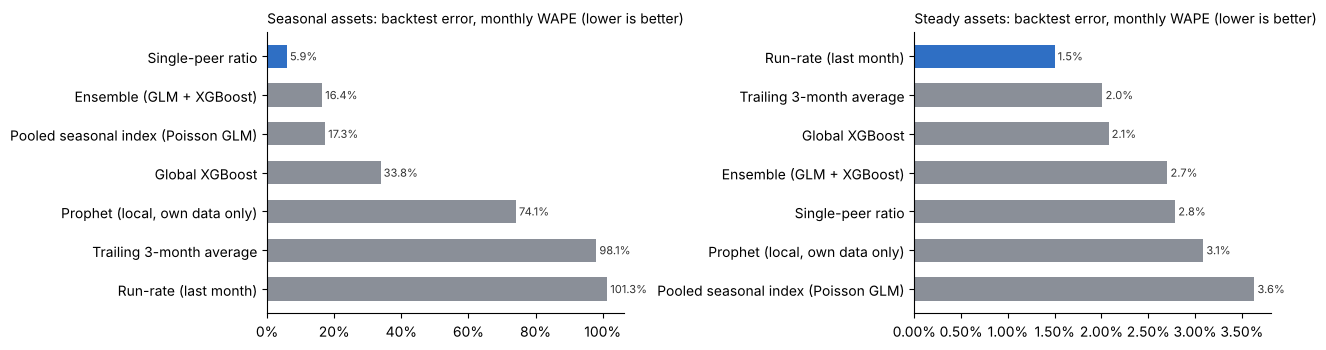

FY2027 momentum baseline by property (TTM as booked; partial years not grossed up):


,Property,Family,Months observed,Revenue TTM,NOI TTM,Revenue Low,Revenue Base,Revenue High,NOI Low,NOI Base,NOI High,NOI margin,Borrowed share of revenue
SCODE,,,,,,,,,,,,,
CRF_1001,Aspen Hollow RV Resort,Seasonal,12,"1,297,926","230,311","1,213,803","1,297,926","1,382,048","154,421","230,311","306,201",18%,0%
CRF_1002,Maple Court Apartments,Steady,12,"2,074,701","1,028,945","2,056,122","2,097,589","2,139,055","1,011,110","1,050,918","1,090,726",50%,0%
CRF_1003,Stor-Easy Storage,Steady,12,"1,063,835","648,659","1,053,836","1,075,089","1,096,342","639,202","659,302","679,402",61%,0%
GDF_1001,Riverside Business Park,Steady,12,"2,854,018","2,279,284","2,821,226","2,878,122","2,935,019","2,247,488","2,302,655","2,357,822",80%,0%
GDF_1002,Elm Street Lofts,Steady,11,"899,490","362,909","1,066,651","1,088,162","1,109,673","478,341","498,992","519,643",46%,8%
OPF_1001,Pinecrest RV Park,Seasonal,12,"1,637,403","509,031","1,523,798","1,637,403","1,751,007","404,481","509,031","613,582",31%,0%
OPF_1002,Bluewater Marina & RV,Seasonal,5,"490,724","190,235","598,246","653,948","709,650","7,977","59,278","110,580",9%,25%
OPF_1003,Cedar Bluff Campground,Seasonal,12,"635,848","44,708","590,397","635,848","681,300","3,898","44,708","85,519",7%,0%
TOTAL,Total (all properties),,,"10,953,944","5,294,082","10,924,079","11,364,086","11,804,093","4,946,918","5,355,196","5,763,474",47%,2%


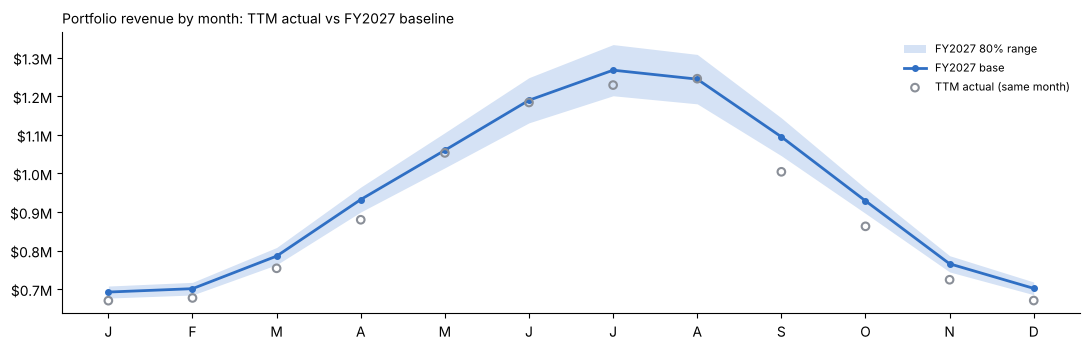

In [27]:
import matplotlib.pyplot as plt, matplotlib.ticker as mtick
BLUE, GREY, INK, BAND = '#2f6fc4', '#8a8f98', '#333333', '#d5e2f5'
fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
for ax, (fam, g) in zip(axes, fc.board.groupby('Family')):
    g = g.sort_values('WAPE (monthly)')
    ax.barh(g.Approach[::-1], g['WAPE (monthly)'][::-1] * 100, height=0.6, color=[BLUE if x == 'SELECTED' else GREY for x in g.Selected[::-1]])
    for i, v in enumerate(g['WAPE (monthly)'][::-1]):
        ax.text(v * 100, i, f' {v:.1%}', va='center', fontsize=8, color=INK)
    ax.set_title(f'{fam} assets: backtest error, monthly WAPE (lower is better)', fontsize=10, loc='left')
    ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); plt.show()

s = fc.summary()
print('FY2027 momentum baseline by property (TTM as booked; partial years not grossed up):')
display(s.style.format({**{c: '{:,.0f}' for c in s.columns if c not in ('Property', 'Family', 'NOI margin', 'Borrowed share of revenue', 'Months observed')},
                        'NOI margin': '{:.0%}', 'Borrowed share of revenue': '{:.0%}', 'Months observed': '{:.0f}'}, na_rep=''))

f = fc.fc[fc.fc.FLine.isin(['Contract revenue', 'Transient & ancillary revenue'])].groupby('Month')[['Low', 'Base', 'High']].sum()
act = fc.n[(fc.n.Level == 'Asset') & (fc.n.Group == 'REV')].groupby(fc.n.Month.dt.month).Amount.sum()
fig, ax = plt.subplots(figsize=(11, 3.6))
x = range(1, 13)
ax.fill_between(x, f.Low.values, f.High.values, color=BAND, lw=0, label='FY2027 80% range')
ax.plot(x, f.Base.values, color=BLUE, lw=2, marker='o', ms=4, label='FY2027 base')
ax.scatter(act.index, act.values, facecolors='none', edgecolors=GREY, s=30, lw=1.5, label='TTM actual (same month)', zorder=3)
ax.set_xticks(list(x)); ax.set_xticklabels(list('JFMAMJJASOND'))
ax.yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f'${v/1e6:,.1f}M'))
ax.set_title('Portfolio revenue by month: TTM actual vs FY2027 baseline', loc='left', fontsize=10)
ax.legend(fontsize=8, frameon=False); ax.spines[['top', 'right']].set_visible(False)
fig.tight_layout(); plt.show()

In [28]:
# CFO interpretation, generated from the numbers above
from IPython.display import Markdown
t, b = s.loc['TOTAL'], fc.board.set_index(['Family', 'Approach'])
part = [p for p in fc.props if fc.gaps[p]]
sea, std = fc.chosen.get('Seasonal'), fc.chosen.get('Steady')
local = b.loc['Seasonal'].loc[['Run-rate (last month)', 'Trailing 3-month average', 'Prophet (local, own data only)'], 'WAPE (monthly)'].min()
gl = b.loc['Seasonal'].loc[['Pooled seasonal index (Poisson GLM)', 'Global XGBoost'], 'WAPE (monthly)'].min()
M = lambda v: f"\\${v / 1e6:,.2f}M"
memo = (
    f"**Bottom line.** If every property repeats its TTM operations, FY2027 revenue is **{M(t['Revenue Base'])}** and property NOI "
    f"**{M(t['NOI Base'])}** (80% range {M(t['NOI Low'])} to {M(t['NOI High'])}), against TTM NOI of {M(t['NOI TTM'])} as booked. "
    "This is the momentum case: no rate increases, no new units or sites, no initiatives. NOI is property-level, after management fees "
    "and before debt service.\n\n"
    f"**Accuracy vs interpretability.** For seasonal assets, approaches that use only the property's own months fail: the best of them "
    f"missed by **{local:.0%}** a month in the backtest (Prophet included), because a few months cannot reveal a season. Borrowing "
    f"from peers cut the error to **{b.loc[('Seasonal', sea), 'WAPE (monthly)']:.1%}** ({sea}). The global machine-learning models "
    f"(Poisson GLM, XGBoost: best {gl:.1%}) were less accurate here and harder to explain, so the written rule keeps the simpler one. "
    f"For steady assets the run-rate wins ({b.loc[('Steady', std), 'WAPE (monthly)']:.1%}): a rent roll has no season. A CFO can "
    "defend every number in one sentence: same month last year, or its peers' shape scaled to its own months.\n\n"
    "**Where the baseline is solid and where it is not.** "
    + "; ".join(f"{nm[p]} has {12 - len(fc.gaps[p])} of 12 months, {s.loc[p, 'Borrowed share of revenue']:.0%} of its revenue borrowed" for p in part)
    + ". Every other property's months are its own. Contract billings before ownership are not assumed: Asset Management confirms "
    "them first.\n\n"
    "**What to do with it.** Use Base as each property's starting point: budget = baseline + drivers + owned initiatives, and a line "
    "that differs from the baseline by more than the range needs a driver explanation. Size reserves on Low. Re-run after each close: "
    "a second year of history makes local seasonal models (Prophet, SARIMA) testable, and the same backtest decides whether they "
    "replace peer-borrowing."
    + ("\n\n**Demo data caveat.** The demo parks share one seasonal shape by construction, so peer-borrowing scores far better here "
       "than on real books (Week 5 on real data: about 36% monthly error, still well ahead of park-only methods)." if True else "")
)
display(Markdown(memo))

**Bottom line.** If every property repeats its TTM operations, FY2027 revenue is **\$11.36M** and property NOI **\$5.36M** (80% range \$4.95M to \$5.76M), against TTM NOI of \$5.29M as booked. This is the momentum case: no rate increases, no new units or sites, no initiatives. NOI is property-level, after management fees and before debt service.

**Accuracy vs interpretability.** For seasonal assets, approaches that use only the property's own months fail: the best of them missed by **74%** a month in the backtest (Prophet included), because a few months cannot reveal a season. Borrowing from peers cut the error to **5.9%** (Single-peer ratio). The global machine-learning models (Poisson GLM, XGBoost: best 17.3%) were less accurate here and harder to explain, so the written rule keeps the simpler one. For steady assets the run-rate wins (1.5%): a rent roll has no season. A CFO can defend every number in one sentence: same month last year, or its peers' shape scaled to its own months.

**Where the baseline is solid and where it is not.** Elm Street Lofts has 11 of 12 months, 8% of its revenue borrowed; Bluewater Marina & RV has 5 of 12 months, 25% of its revenue borrowed. Every other property's months are its own. Contract billings before ownership are not assumed: Asset Management confirms them first.

**What to do with it.** Use Base as each property's starting point: budget = baseline + drivers + owned initiatives, and a line that differs from the baseline by more than the range needs a driver explanation. Size reserves on Low. Re-run after each close: a second year of history makes local seasonal models (Prophet, SARIMA) testable, and the same backtest decides whether they replace peer-borrowing.

**Demo data caveat.** The demo parks share one seasonal shape by construction, so peer-borrowing scores far better here than on real books (Week 5 on real data: about 36% monthly error, still well ahead of park-only methods).

In [29]:
import shutil
from datetime import datetime
xl = f'FY2027_Baseline_Forecast_{datetime.now():%Y%m%d_%H%M}.xlsx'
fc.export(xl)
paths = fc.export_app_data('app_data')                      # forecast.csv, forecast_board.csv, forecast_summary.csv next to 4b's files
shutil.make_archive('app_data', 'zip', 'app_data')
print('Wrote', xl, 'and', ', '.join(os.path.basename(x) for x in paths), '-> app_data.zip (the app starts from this baseline)')
try:
    from google.colab import files
    files.download(xl); files.download('app_data.zip')
except ImportError:
    pass

Wrote FY2027_Baseline_Forecast_20261025_2058.xlsx and forecast.csv, forecast_board.csv, forecast_summary.csv -> app_data.zip (the app starts from this baseline)


## 5. After review: read the approved register back
Upload the workbook with your Status decisions. The normalized baseline (raw + approved) is written as a long CSV for the budget template's prior-year block.

In [30]:
REVIEWED = None   # e.g. 'uploads/Consolidation_Output_20261023_2100_reviewed.xlsx'
if REVIEWED:
    bp.load_register(REVIEWED)
    base = bp.normalized()
    cols = ['SCODE', 'LineID', 'AccountCode', 'AccountName', 'PeriodText', 'Amount', 'Provenance', 'RowType']
    base[cols].to_csv('Normalized_Baseline.csv', index=False)
    print(bp.adjustments.Status.value_counts())
    print('Normalized NOI:', round(base[base.Group.isin(['REV', 'OPX'])].Amount.sum()))

## 6. Prove it: planted-problem test (recall on known answers)
The demo files carry 25 known problems (answer key: the Demo_Answer_Key sheet of pipeline_config.xlsx):
- accounting anomalies for every detector D01-D12
- dirty cells (#REF!, numbers stored as text), a new GL not in the chart, a roll-up tab, a partial month, a 4-digit QBO code
- two ledgers for one property (book of record, plus amortizing items added from the other ledger)
- balance sheets missing for some months, one out of balance, one whose earnings do not match the P&L

The run has to find every one.

In [31]:
from budget_pipeline.validate import score
if config_path:
    key = pd.read_excel(config_path, sheet_name='Demo_Answer_Key', header=3).fillna('')
    sc = score(bp, key)
    print(f"Caught {(sc.Found == 'Y').sum()} of {len(sc)} planted problems")
    display(sc[['PlantID', 'Description', 'Expected', 'Found', 'CaughtBy']])
else:
    print('Upload pipeline_config.xlsx (it holds the answer key) to run the planted-problem test.')

Caught 25 of 25 planted problems


,PlantID,Description,Expected,Found,CaughtBy
0,P01,"Maple Court water bill missing in May, both months booked in June",D01,Y,F-0002
1,P02,Riverside Tenant C rent not billed in July,D02,Y,F-0009
2,P03,Stor-Easy annual insurance premium expensed in March instead of prepaid,D03,Y,F-0006
3,P04,"Maple Court roof replacement ($48,000) expensed to repairs",D04,Y,F-0005
4,P05,Elm Street Lofts books not closed for September,D05,Y,F-0001
5,P06,Bluewater has no property tax booked since acquisition,D06,Y,F-0007
6,P07,Cedar Bluff season deposits booked as revenue in February (park closed),D07,Y,F-0008
7,P08,Riverside repairs accrual reversed in April and rebooked in May,D08,Y,F-0003
8,P09,Maple Court landscaping invoice posted twice in August,D09,Y,F-0004
9,P10,Cedar Bluff pre-season inventory purchase expensed as cost of sales in March,D10,Y,F-0010
